# Will this hotel booking be cancelled?

**Machine Learning Assignment 1: the ML process, classification problem.**

**Author:** Abel Mari Shiferaw  
**Student ID:** GSR/1670/19  
**Course:** Machine Learning  
**Instructor:** Dr Fantahun Bogale Gereme  
**Institution:** Addis Ababa University, College of Technology and Built Environment

This notebook follows the assignment's steps in order, using the assignment's own numbering (which
skips 7 and 9):

| Assignment step | Where in this notebook |
|---|---|
| 1. Problem definition: problem, goal, success criteria | Section 1 |
| 2. Data collection: source, representativeness | Section 2 |
| 3. Exploration and preparation: EDA | 3.5 (after the split, so the test set stays unseen) |
| 3. Cleaning: missing values, duplicates, outliers, inconsistencies | 3.1 and 3.2 |
| 3. Feature engineering: new features, encoding, scaling | 3.4 |
| 3. Splitting: training, validation, test | 3.3 |
| 3. (beyond the brief) Leakage audit and what the duplicates really do | 3.6 and 3.7 |
| 4. Algorithm selection: complexity, interpretability, cost | Section 4 |
| 5. Model development and training | Section 5 |
| 6. Evaluation on validation: accuracy, precision, recall, F1, ROC-AUC | 5 (all candidates) and 6.3 (champion) |
| 6. Underfitting and overfitting | 6.2 |
| 6. Grid search, random search, Bayesian optimisation | 6.1 |
| 8. Final test with the same metrics | 8.1 |
| 8. Deployment and integration | 8.2 and 8.3 |
| 10. Monitoring: latency, drift, feedback, retraining | Section 10 |
| 11. Documentation and reporting | Section 11 (summary, limitations, next steps) |

**How to run it.** The notebook is self-contained: upload it on its own to Colab or Jupyter and run all
cells. It installs any missing packages, downloads the data and defines every function it uses. A full
run takes roughly 30 to 60 minutes depending on the machine; set the environment variable `ML_FAST=1`
for a smoke run of a few minutes with tiny budgets (never used for reported results).

**Where the code comes from.** The same project also exists as a tested Python package with a
command-line pipeline. The code cells marked *"Copied from hotel_cancellation..."* are copied verbatim
from that package by a build script, so this notebook and the pipeline run identical code; an automated
test checks that they produce the same data splits and the same test metrics.

**A note on numbers.** No result in this notebook's text is typed by hand. Wherever a finding includes
a number, the sentence is generated by code from the computed result. The headline results are in the
summary at the end (Section 11).

## 0. Setup

Installs only what is missing, at the version this notebook was tested with. Packages already present
(for example numpy, pandas and scikit-learn on Colab) are left alone, because force-reinstalling them
can break the runtime; the version table printed below shows any difference from the tested versions.
With different versions the notebook still runs (it was also tested in fast mode with numpy 2.0,
pandas 2.2 and scikit-learn 1.6), but numbers can differ slightly from the saved outputs.

In [1]:
import importlib.util
import subprocess
import sys
import warnings

# Versions this notebook was tested with (from pyproject.toml)
TESTED_VERSIONS = {"numpy": "2.5.4", "pandas": "3.0.6", "scikit-learn": "1.9.1", "lightgbm": "4.7.0", "optuna": "5.0.0", "shap": "0.54.1", "matplotlib": "3.11.2", "seaborn": "0.13.2", "PyYAML": "6.0.3", "onnx": "1.23.2", "onnxruntime": "1.31.0", "skl2onnx": "1.20.0", "onnxmltools": "1.16.0", "imbalanced-learn": "0.14.2"}
REQUIRED = {"lightgbm": "lightgbm", "optuna": "optuna", "shap": "shap", "imblearn": "imbalanced-learn",
            "onnx": "onnx", "onnxruntime": "onnxruntime", "skl2onnx": "skl2onnx", "onnxmltools": "onnxmltools",
            "yaml": "PyYAML", "seaborn": "seaborn", "sklearn": "scikit-learn"}
missing = [pkg for module, pkg in REQUIRED.items() if importlib.util.find_spec(module) is None]
if missing:
    print("Installing:", ", ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           *[f"{pkg}=={TESTED_VERSIONS[pkg]}" if pkg in TESTED_VERSIONS else pkg for pkg in missing]])
else:
    print("All required packages are already installed.")
warnings.filterwarnings("ignore", message=".*IProgress not found.*")

All required packages are already installed.


In [2]:
# Every third-party import used by the code in this notebook
import dataclasses
import gzip
import hashlib
import itertools
import json
import logging
import math
import matplotlib.pyplot as plt
import numpy as np
import onnxruntime as ort
import optuna
import pandas as pd
import pickle
import platform
import seaborn as sns
import shap
import shutil
import subprocess
import sys
import time
import urllib.request
import yaml
from dataclasses import dataclass
from datetime import UTC, datetime
from datetime import date, timedelta
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline
from importlib import metadata
from lightgbm import LGBMClassifier
from matplotlib.container import BarContainer
from pathlib import Path
from scipy.stats import ks_2samp
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, average_precision_score, brier_score_loss, confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.metrics import precision_recall_curve, roc_curve
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.model_selection import StratifiedKFold, cross_validate, learning_curve, validation_curve
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, OrdinalEncoder, TargetEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from typing import Any

In [3]:
import os
from pathlib import Path

from IPython.display import Markdown, display

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="sklearn")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 120)


def say(text: str) -> None:
    """Show a finding whose numbers come from computed results."""
    display(Markdown(text))


OUTPUT_DIR = Path(os.environ.get("OUTPUT_DIR", "outputs"))
FAST = os.environ.get("ML_FAST") == "1"

**Logging, configuration and output folders.** Every tunable setting (data source, cleaning limits,
leakage decisions, costs, search budgets, success criteria) lives in one configuration file, embedded
below so the notebook runs on its own.

In [4]:
# Copied from hotel_cancellation.log by scripts/build_notebooks.py
from __future__ import annotations

def get_logger(name: str = "hotel_cancellation") -> logging.Logger:
    """Return a logger that writes one timestamped line per message to stderr."""
    logger = logging.getLogger(name)
    if not logger.handlers:
        handler = logging.StreamHandler(sys.stderr)
        handler.setFormatter(
            logging.Formatter("%(asctime)s %(levelname)s %(name)s | %(message)s", "%H:%M:%S")
        )
        logger.addHandler(handler)
        logger.setLevel(logging.INFO)
        logger.propagate = False
    return logger


LOGGER = get_logger()

In [5]:
# Copied from hotel_cancellation.config by scripts/build_notebooks.py
from __future__ import annotations

@dataclass(frozen=True)
class DataConfig:
    name: str
    citation: str
    license: str
    sources: list[str]
    mirror_path: str
    mirror_url: str
    sha256: str
    expected_rows: int
    expected_columns: int


@dataclass(frozen=True)
class CleaningConfig:
    drop_duplicates: bool
    max_valid_adr: float
    fill_meal_undefined_as: str


@dataclass(frozen=True)
class SplitConfig:
    val_size: float
    test_size: float
    temporal_train_until_year: int


@dataclass(frozen=True)
class FeatureConfig:
    min_category_frequency: int
    safe_sources: list[str]
    tier3_sources: list[str]
    candidate_sources: list[str]
    tier2_sources: list[str]
    tier1_sources: list[str]


@dataclass(frozen=True)
class LeakageDecision:
    decision: str
    reason: str


@dataclass(frozen=True)
class LeakageConfig:
    tier1_columns: list[str]
    tier2_columns: list[str]
    never_columns: list[str]
    tier3_decisions: dict[str, LeakageDecision]


@dataclass(frozen=True)
class CostConfig:
    false_negative: float
    false_positive: float


@dataclass(frozen=True)
class RiskBandConfig:
    low: float
    high: float


@dataclass(frozen=True)
class ModelsConfig:
    n_jobs: int


@dataclass(frozen=True)
class TuningConfig:
    subsample_rows: int
    cv_folds: int
    logreg_grid: dict[str, list[Any]]
    rf_random_iterations: int
    lgbm_budget: int
    lgbm_grid: dict[str, list[Any]]
    refine_trials: int


@dataclass(frozen=True)
class DiagnosticsConfig:
    learning_curve_sizes: list[float]
    validation_curve_num_leaves: list[int]


@dataclass(frozen=True)
class EvaluationConfig:
    bootstrap_samples: int
    calibration_folds: int
    calibration_min_brier_gain: float
    cost_sensitivity_false_positive: list[float]


@dataclass(frozen=True)
class ExplainConfig:
    permutation_repeats: int
    shap_rows: int


@dataclass(frozen=True)
class SuccessConfig:
    roc_auc: float


@dataclass(frozen=True)
class ServiceConfig:
    url: str


@dataclass(frozen=True)
class SelectionConfig:
    tie_tolerance: float


@dataclass(frozen=True)
class FirstTestEvaluation:
    """Record of the first time the test set was scored (see configs/config.yaml)."""

    date: str
    champion: str
    validation_roc_auc: float
    roc_auc: float
    roc_auc_ci: list[float]
    pr_auc: float
    threshold: float
    precision: float
    recall: float
    f1: float
    what_changed_afterwards: str


@dataclass(frozen=True)
class Config:
    project: str
    seed: int
    data: DataConfig
    target: str
    cleaning: CleaningConfig
    split: SplitConfig
    features: FeatureConfig
    leakage: LeakageConfig
    costs: CostConfig
    risk_bands: RiskBandConfig
    models: ModelsConfig
    tuning: TuningConfig
    diagnostics: DiagnosticsConfig
    evaluation: EvaluationConfig
    explain: ExplainConfig
    success: SuccessConfig
    service: ServiceConfig
    selection: SelectionConfig
    test_pass_models: list[str]
    first_test_evaluation: FirstTestEvaluation
    fast: dict[str, Any]
    sample_rows: int | None = None
    is_fast: bool = False


SECTION_TYPES = {
    "data": DataConfig,
    "cleaning": CleaningConfig,
    "split": SplitConfig,
    "features": FeatureConfig,
    "costs": CostConfig,
    "risk_bands": RiskBandConfig,
    "models": ModelsConfig,
    "tuning": TuningConfig,
    "diagnostics": DiagnosticsConfig,
    "evaluation": EvaluationConfig,
    "explain": ExplainConfig,
    "success": SuccessConfig,
    "service": ServiceConfig,
    "selection": SelectionConfig,
    "first_test_evaluation": FirstTestEvaluation,
}


def build_section(cls: type, values: dict[str, Any], section: str) -> Any:
    """Instantiate one config dataclass, rejecting missing or unknown keys."""
    fields = dataclasses.fields(cls)
    allowed = {f.name for f in fields}
    required = {f.name for f in fields
                if f.default is dataclasses.MISSING and f.default_factory is dataclasses.MISSING}
    missing, unknown = required - set(values), set(values) - allowed
    if missing or unknown:
        raise ValueError(f"config section '{section}': missing={sorted(missing)} unknown={sorted(unknown)}")
    return cls(**values)


def config_from_dict(raw: dict[str, Any]) -> Config:
    """Convert the parsed YAML mapping into a validated :class:`Config`."""
    raw = dict(raw)
    sections = {name: build_section(cls, raw.pop(name), name) for name, cls in SECTION_TYPES.items()}
    leak = dict(raw.pop("leakage"))
    leak["tier3_decisions"] = {
        col: build_section(LeakageDecision, val, f"leakage.tier3_decisions.{col}")
        for col, val in leak["tier3_decisions"].items()
    }
    for col, dec in leak["tier3_decisions"].items():
        if dec.decision not in {"keep", "exclude"}:
            raise ValueError(f"leakage decision for {col} must be keep or exclude")
    sections["leakage"] = build_section(LeakageConfig, leak, "leakage")
    return build_section(Config, {**raw, **sections}, "top level")


def load_config_text(text: str) -> Config:
    """Parse configuration from a YAML string (used by the self-contained notebook)."""
    return config_from_dict(yaml.safe_load(text))


def load_config(path: str | Path) -> Config:
    """Parse configuration from a YAML file."""
    return load_config_text(Path(path).read_text(encoding="utf-8"))


def apply_fast_mode(cfg: Config) -> Config:
    """Return a copy with tiny budgets for smoke tests. Never used for reported results."""
    fast = cfg.fast
    return dataclasses.replace(
        cfg,
        is_fast=True,
        sample_rows=fast["sample_rows"],
        tuning=dataclasses.replace(
            cfg.tuning,
            subsample_rows=fast["subsample_rows"],
            cv_folds=fast["cv_folds"],
            rf_random_iterations=fast["rf_random_iterations"],
            lgbm_budget=fast["lgbm_budget"],
            refine_trials=fast["refine_trials"],
            lgbm_grid={"num_leaves": [15, 31], "learning_rate": [0.1], "n_estimators": [50, 100]},
        ),
        diagnostics=dataclasses.replace(
            cfg.diagnostics, learning_curve_sizes=[0.3, 1.0], validation_curve_num_leaves=[8, 32]
        ),
        evaluation=dataclasses.replace(cfg.evaluation, bootstrap_samples=fast["bootstrap_samples"]),
        explain=ExplainConfig(permutation_repeats=fast["permutation_repeats"], shap_rows=fast["shap_rows"]),
    )


def deployed_sources(cfg: Config) -> list[str]:
    """Feature groups used by the deployed model: safe groups plus Tier 3 groups marked keep."""
    kept = [s for s in cfg.features.tier3_sources if cfg.leakage.tier3_decisions[s].decision == "keep"]
    return list(cfg.features.safe_sources) + kept

In [6]:
# Copied from hotel_cancellation.artifacts by scripts/build_notebooks.py
from __future__ import annotations

@dataclass
class RunContext:
    """Folder layout for one run.

    ``layout="pipeline"`` follows the repository layout (data/, artifacts/,
    reports/). ``layout="notebook"`` keeps everything under one output folder
    so a notebook works when it is the only file present.
    """

    root: Path
    layout: str = "pipeline"
    show: bool = False

    def __post_init__(self) -> None:
        self.root = Path(self.root)
        if self.layout not in {"pipeline", "notebook"}:
            raise ValueError("layout must be 'pipeline' or 'notebook'")

    @property
    def data_dir(self) -> Path:
        return self.root / "data"

    @property
    def artifacts_dir(self) -> Path:
        return self.root / "artifacts"

    @property
    def fig_dir(self) -> Path:
        return self.root / "reports" / "figures" if self.layout == "pipeline" else self.root / "figures"

    @property
    def metrics_dir(self) -> Path:
        return self.root / "reports" / "metrics" / "pipeline" if self.layout == "pipeline" else self.root

    def ensure(self) -> RunContext:
        for d in (self.data_dir / "raw", self.data_dir / "interim", self.data_dir / "processed",
                  self.artifacts_dir, self.fig_dir, self.metrics_dir):
            d.mkdir(parents=True, exist_ok=True)
        return self


def to_jsonable(obj: Any) -> Any:
    """Convert numpy scalars/arrays and paths so ``json.dump`` accepts them."""
    if isinstance(obj, dict):
        return {str(k): to_jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [to_jsonable(v) for v in obj]
    if isinstance(obj, np.ndarray):
        return [to_jsonable(v) for v in obj.tolist()]
    if isinstance(obj, np.bool_):
        return bool(obj)
    if isinstance(obj, np.integer):
        return int(obj)
    if isinstance(obj, np.floating):
        return None if np.isnan(obj) else float(obj)
    if isinstance(obj, float) and obj != obj:
        return None
    if isinstance(obj, Path):
        return str(obj)
    return obj


def save_json(obj: Any, path: str | Path) -> Path:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(to_jsonable(obj), indent=2, sort_keys=False) + "\n", encoding="utf-8")
    return path


def load_json(path: str | Path) -> Any:
    return json.loads(Path(path).read_text(encoding="utf-8"))


def file_sha256(path: str | Path) -> str:
    digest = hashlib.sha256()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


def package_versions(names: list[str]) -> dict[str, str]:
    out = {}
    for name in names:
        try:
            out[name] = metadata.version(name)
        except metadata.PackageNotFoundError:
            out[name] = "not installed"
    return out


TRACKED_PACKAGES = ["numpy", "pandas", "scikit-learn", "lightgbm", "optuna", "shap",
                    "imbalanced-learn", "matplotlib", "seaborn", "skl2onnx", "onnxmltools", "onnxruntime"]


def git_sha(root: Path) -> str:
    try:
        return subprocess.run(["git", "rev-parse", "HEAD"], cwd=root, capture_output=True,
                              text=True, check=True).stdout.strip()
    except (OSError, subprocess.CalledProcessError):
        return "unknown"


def write_manifest(ctx: RunContext, stage: str, config_dict: dict[str, Any], extra: dict[str, Any]) -> Path:
    """Record what produced an artifact: code version, config, environment, results."""
    stamp = datetime.now(UTC).strftime("%Y%m%dT%H%M%SZ")
    manifest = {
        "stage": stage,
        "created_utc": stamp,
        "git_sha": git_sha(ctx.root),
        "python": platform.python_version(),
        "packages": package_versions(TRACKED_PACKAGES),
        "config": config_dict,
        **extra,
    }
    return save_json(manifest, ctx.artifacts_dir / "runs" / f"{stamp}_{stage}.json")

In [7]:
# configs/config.yaml, embedded so this notebook runs on its own
CONFIG_YAML = r"""
# Every tunable setting for the project lives here. Code reads it through
# hotel_cancellation.config.load_config(); nothing below is repeated in code.

project: hotel-cancellation-classification
seed: 42

data:
  name: Hotel Booking Demand
  citation: >-
    Antonio, N., de Almeida, A., & Nunes, L. (2019). Hotel booking demand
    datasets. Data in Brief, 22, 41-49. https://doi.org/10.1016/j.dib.2018.11.126
  license: CC BY 4.0
  # The same file from the TidyTuesday repository, pinned to the commit that added it. The CDN copy is
  # tried first because raw.githubusercontent.com is throttled on some networks; either way the
  # SHA-256 below must match, so it is provably the same file.
  sources:
    - https://cdn.jsdelivr.net/gh/rfordatascience/tidytuesday@d75aaa0d31596ad6487ae0db20138067d301e031/data/2020/2020-02-11/hotels.csv
    - https://raw.githubusercontent.com/rfordatascience/tidytuesday/d75aaa0d31596ad6487ae0db20138067d301e031/data/2020/2020-02-11/hotels.csv
  mirror_path: data/mirror/hotels.csv.gz   # compressed copy shipped in the repo
  mirror_url: ""                            # optional: raw GitHub URL of the mirror once pushed
  sha256: 7c2ae42a7353905ea136e5c2287f17c92c5435826598bfbb8491c6f0c7b1fc06
  expected_rows: 119390
  expected_columns: 32

target: is_canceled

cleaning:
  drop_duplicates: true
  max_valid_adr: 1000.0          # domain limit, not learned from data
  fill_meal_undefined_as: SC     # dataset paper: "Undefined" and "SC" both mean no meal package

split:
  val_size: 0.15
  test_size: 0.15
  temporal_train_until_year: 2016   # robustness check on train+validation rows only

features:
  min_category_frequency: 30        # rarer categories are grouped; learned on training data only
  # Feature groups produced by rowlevel.py, named after the raw column(s) they come from.
  safe_sources: [base]
  tier3_sources: [adr, required_car_parking_spaces, total_of_special_requests, country]
  # Extra booking-time features tested in Section 5 and not adopted (the gain is within fold noise).
  candidate_sources: [candidate]
  tier2_sources: [tier2]
  tier1_sources: [tier1]

leakage:
  tier1_columns: [reservation_status, reservation_status_date]
  tier2_columns: [assigned_room_type, booking_changes, days_in_waiting_list]
  never_columns: [arrival_date_year]
  # Decisions for timing-uncertain columns. The notebook shows the evidence for each.
  tier3_decisions:
    adr:
      decision: keep
      reason: >-
        The price is agreed when the room is booked. It can change later, but the
        cancellation rate by price band changes smoothly, with no value that only
        guests who arrived would have.
    required_car_parking_spaces:
      decision: exclude
      reason: >-
        Every booking with a parking space has a cancellation rate of exactly zero.
        Parking is recorded at check-in, so the value encodes the outcome.
    total_of_special_requests:
      decision: exclude
      reason: >-
        Requests can be added at any time up to check-in, and guests who cancel
        never reach that point. The timing cannot be established, so the rule
        "when in doubt, exclude" applies.
    country:
      decision: exclude
      reason: >-
        Nationality is usually confirmed at check-in. Cancelled bookings keep the
        value entered at booking, which tends to default to the hotels' home
        country, so Portugal shows an implausibly high cancellation rate.

costs:
  # Cost of each wrong decision, in room-nights. Relocating an overbooked guest
  # who does arrive (false positive) costs more than one empty room (false negative).
  false_negative: 1.0
  false_positive: 2.0

risk_bands:          # calibrated-probability cut-offs for the label shown in the demo
  low: 0.30
  high: 0.70

models:
  n_jobs: 4

tuning:
  subsample_rows: 20000
  cv_folds: 3
  logreg_grid:
    C: [0.01, 0.1, 1.0, 10.0]
    class_weight: [null, balanced]
  rf_random_iterations: 20
  # The same budget goes to all three strategies on LightGBM, so the comparison
  # between Grid, Random and Bayesian search is fair.
  lgbm_budget: 24
  lgbm_grid:
    num_leaves: [31, 63, 127]
    learning_rate: [0.03, 0.1]
    n_estimators: [200, 400, 600, 800]
  # Second stage: Bayesian search on ALL training rows, started from LightGBM's defaults and from
  # the best setting of each subsample search. Settings found on a 20,000-row sample do not
  # transfer to 61,000 rows (the first champion scored below the untuned default on validation).
  refine_trials: 24

diagnostics:
  learning_curve_sizes: [0.1, 0.25, 0.5, 0.75, 1.0]
  validation_curve_num_leaves: [8, 16, 32, 64, 128, 256]

evaluation:
  bootstrap_samples: 1000
  calibration_folds: 5
  calibration_min_brier_gain: 0.0005
  # False-alarm costs (missed cancellation fixed at 1) for the sensitivity table: how the threshold,
  # precision and recall move when the hotel's action is cheaper or dearer than relocating a guest.
  cost_sensitivity_false_positive: [0.2, 0.5, 1.0, 2.0, 3.0]

explain:
  permutation_repeats: 5
  shap_rows: 2000

success:
  roc_auc: 0.85

service:
  # Base URL of the deployed API. The notebooks call it for the live checks (Sections 8.3 and 10);
  # the SERVICE_URL environment variable overrides it. Empty means not deployed.
  url: "https://hotel-cancellation-risk.vercel.app"

selection:
  # Models within this validation ROC-AUC of the best are treated as tied (the difference is below
  # run-to-run noise), and the smallest of them is chosen: it deploys and scores faster.
  tie_tolerance: 0.002

# Models scored on the test set, fixed before the test pass.
test_pass_models: [dummy, logreg, champion]

# The test set has been scored twice. This block is the record of the first time; the archived
# results file is reports/metrics/history/2026-11-10_first_test_evaluation.json and a unit test
# checks that the numbers below match it.
first_test_evaluation:
  date: "2026-11-10"
  champion: LightGBM tuned by Bayesian search on a 20,000-row training subsample
  validation_roc_auc: 0.8017
  roc_auc: 0.7974
  roc_auc_ci: [0.7887, 0.8049]
  pr_auc: 0.6206
  threshold: 0.61
  precision: 0.8247
  recall: 0.1633
  f1: 0.2726
  what_changed_afterwards: >-
    Only the champion's hyperparameters. The first champion scored lower on validation than
    LightGBM with default settings, because settings found on a 20,000-row subsample do not
    transfer to the full training set. A second search stage on all training rows was added.
    The data, the split, the features, the leakage decisions, the costs and the success criterion
    are unchanged, and the change was decided on validation data before the test set was scored again.

fast:   # ML_FAST=1 or --fast: tiny budgets for tests and CI; never used for reported results
  sample_rows: 8000
  subsample_rows: 3000
  cv_folds: 2
  rf_random_iterations: 3
  lgbm_budget: 4
  refine_trials: 3
  bootstrap_samples: 50
  permutation_repeats: 2
  shap_rows: 200
"""

In [8]:
cfg = load_config_text(CONFIG_YAML)
if FAST:
    cfg = apply_fast_mode(cfg)
    print("FAST MODE: tiny budgets, results are not meaningful.")
ctx = RunContext(OUTPUT_DIR, layout="notebook", show=True).ensure()
print(f"Figures and results are saved in the '{ctx.root.name}' folder. Random seed: {cfg.seed}.")
installed = package_versions(TRACKED_PACKAGES)
display(pd.DataFrame({"installed": installed, "tested with": {k: TESTED_VERSIONS.get(k, "") for k in installed}}))

Figures and results are saved in the 'outputs' folder. Random seed: 42.


,installed,tested with
numpy,2.5.4,2.5.4
pandas,3.0.6,3.0.6
scikit-learn,1.9.1,1.9.1
lightgbm,4.7.0,4.7.0
optuna,5.0.0,5.0.0
shap,0.54.1,0.54.1
imbalanced-learn,0.14.2,0.14.2
matplotlib,3.11.2,3.11.2
seaborn,0.13.2,0.13.2
skl2onnx,1.20.0,1.20.0


**Plotting helpers.** One house style for every figure. Each figure is shown here and also saved to
`outputs/figures/` at 200 dpi.

In [9]:
# Copied from hotel_cancellation.plotting by scripts/build_notebooks.py
from __future__ import annotations

PALETTE = {"ink": "#1d2b36", "blue": "#2b6cb0", "red": "#c0392b", "teal": "#16867a",
           "amber": "#d68910", "grey": "#8a96a3", "light": "#d9dee3"}


def set_plot_style() -> None:
    sns.set_theme(style="whitegrid", context="notebook")
    plt.rcParams.update({
        "figure.dpi": 100, "savefig.dpi": 200, "axes.titleweight": "bold", "axes.titlesize": 12,
        "axes.labelcolor": PALETTE["ink"], "axes.edgecolor": PALETTE["light"],
        "text.color": PALETTE["ink"], "axes.spines.top": False, "axes.spines.right": False,
        "font.family": "DejaVu Sans",
    })


def finish_figure(fig, name: str, ctx: RunContext) -> None:
    """Save the figure as ``<name>.png`` in the run's figure folder, then show it (notebook) or close it.

    Returns nothing on purpose: as the last line of a notebook cell, a returned path would be
    echoed into the saved output, and that path is specific to the machine.
    """
    path = ctx.fig_dir / f"{name}.png"
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, bbox_inches="tight")
    if ctx.show:
        plt.show()
    else:
        plt.close(fig)


def plot_missingness(raw: pd.DataFrame):
    miss = raw.isna().sum()
    miss = (miss[miss > 0] / len(raw)).sort_values()
    fig, ax = plt.subplots(figsize=(7, 2.8))
    ax.barh(miss.index, miss.values * 100, color=PALETTE["blue"])
    for i, v in enumerate(miss.values):
        ax.text(v * 100 + 1, i, f"{v:.1%}", va="center", fontsize=9)
    ax.set(xlabel="Share of rows missing (%)", title="Missing values in the raw data", xlim=(0, 110))
    return fig


def plot_cleaning_log(log: list[dict]):
    frame = pd.DataFrame(log)
    frame["affected"] = frame["rows_removed"] + frame["values_changed"].fillna(0)
    frame = frame[frame["affected"] > 0]
    colors = [PALETTE["red"] if r > 0 else PALETTE["amber"] for r in frame["rows_removed"]]
    fig, ax = plt.subplots(figsize=(7, 3))
    ax.barh(frame["rule"], frame["affected"], color=colors)
    ax.set_xscale("log")
    for i, v in enumerate(frame["affected"]):
        ax.text(v * 1.1, i, f"{int(v):,}", va="center", fontsize=9)
    ax.invert_yaxis()
    ax.set(xlabel="Rows removed (red) or values changed (amber), log scale", title="Cleaning rules")
    return fig


def plot_duplicate_effect(removed_rate: float, kept_rate: float):
    fig, ax = plt.subplots(figsize=(5, 3))
    bars = ax.bar(["Removed duplicate rows", "Rows kept (train + validation)"], [removed_rate, kept_rate],
                  color=[PALETTE["red"], PALETTE["blue"]])
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.01, f"{b.get_height():.1%}", ha="center")
    ax.set(ylabel="Cancellation rate", ylim=(0, 1), title="Duplicates are mostly cancellations")
    return fig


def plot_rate_by_category(trval: pd.DataFrame, columns: list[str], target: str):
    rows = (len(columns) + 1) // 2
    fig, axes = plt.subplots(rows, 2, figsize=(10, 3.6 * rows), sharey=True)
    base = trval[target].mean()
    for ax, col in zip(np.ravel(axes), columns):
        stats = trval.groupby(col)[target].agg(["mean", "size"]).sort_values("size", ascending=False).head(8)
        bars = ax.bar(stats.index.astype(str), stats["mean"], color=PALETTE["blue"])
        ax.bar_label(bars, labels=[f"{v:.0%}" for v in stats["mean"]], fontsize=9, padding=2)
        ax.axhline(base, color=PALETTE["red"], ls="--", lw=1)
        ax.set_title(col.replace("_", " ").capitalize())
        ax.tick_params(axis="x", rotation=25, labelsize=9)
        for lbl in ax.get_xticklabels():
            lbl.set_ha("right")
    for ax in np.ravel(axes)[len(columns):]:
        ax.set_visible(False)
    for ax in np.atleast_2d(axes)[:, 0]:
        ax.set_ylabel("Cancellation rate")
    np.ravel(axes)[0].set_ylim(0, 1.12)
    fig.suptitle("Cancellation rate by category (largest groups; dashed line = overall rate)", fontweight="bold")
    fig.tight_layout()
    return fig


def plot_numeric_by_outcome(trval: pd.DataFrame, target: str):
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
    for ax, col, clip in zip(axes, ["lead_time", "adr"], [500, 350]):
        for label, color, name in [(0, PALETTE["blue"], "Kept"), (1, PALETTE["red"], "Cancelled")]:
            vals = trval.loc[trval[target] == label, col].clip(upper=clip)
            ax.hist(vals, bins=50, density=True, alpha=0.55, color=color, label=name)
        ax.set(title=f"{col} by outcome", xlabel=col, ylabel="Density")
        ax.legend()
    fig.tight_layout()
    return fig


def plot_monthly_rate(trval: pd.DataFrame, target: str):
    months = pd.to_datetime(trval["arrival_date_year"].astype(str) + "-" + trval["arrival_date_month"] + "-01",
                            format="%Y-%B-%d")
    series = trval.assign(month=months).groupby("month")[target].agg(["mean", "size"])
    fig, ax = plt.subplots(figsize=(10, 3.4))
    ax.bar(series.index, series["size"], width=20, color=PALETTE["light"], label="Bookings")
    ax.set_ylabel("Bookings per arrival month")
    ax2 = ax.twinx()
    ax2.plot(series.index, series["mean"], color=PALETTE["red"], marker="o", ms=3, label="Cancellation rate")
    ax2.set_ylabel("Cancellation rate")
    ax2.grid(False)
    ax.set_title("Seasonality and drift: bookings and cancellation rate by arrival month")
    return fig


def plot_correlation(features: pd.DataFrame, y: pd.Series):
    num = features.select_dtypes("number").assign(cancelled=y.to_numpy())
    corr = num.corr()
    fig, ax = plt.subplots(figsize=(10, 8))
    sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, cbar_kws={"shrink": 0.7},
                xticklabels=True, yticklabels=True)
    ax.tick_params(labelsize=7)
    ax.set_title("Correlation between numeric features and the target")
    return fig


def plot_pca(features: pd.DataFrame, y: pd.Series, seed: int, n: int = 5000):
    num = features.select_dtypes("number")
    idx = np.random.default_rng(seed).choice(len(num), size=min(n, len(num)), replace=False)
    pca = PCA(n_components=2, random_state=seed)
    pts = pca.fit_transform(StandardScaler().fit_transform(num.iloc[idx]))
    lab = y.to_numpy()[idx]
    fig, ax = plt.subplots(figsize=(6, 4.5))
    for label, color, name in [(0, PALETTE["blue"], "Kept"), (1, PALETTE["red"], "Cancelled")]:
        m = lab == label
        ax.scatter(pts[m, 0], pts[m, 1], s=5, alpha=0.35, color=color, label=name)
    ev = pca.explained_variance_ratio_
    ax.set(xlabel=f"PC1 ({ev[0]:.0%} of variance)", ylabel=f"PC2 ({ev[1]:.0%})",
           title="PCA of numeric features (unsupervised view)")
    ax.legend(markerscale=3)
    return fig


def plot_tier3_evidence(evidence: dict):
    fig, axes = plt.subplots(2, 2, figsize=(11, 7.4))
    titles = {"required_car_parking_spaces": "Parking spaces requested", "total_of_special_requests": "Special requests",
              "country": "Country (10 largest)", "adr": "Price per night (ten equal groups)"}
    for ax, (key, title) in zip(np.ravel(axes), titles.items()):
        table = pd.DataFrame(evidence[key])
        bars = ax.bar(table["value"], table["cancel_rate"], color=PALETTE["amber"])
        small = len(table) > 6
        for b, rate, n in zip(bars, table["cancel_rate"], table["rows"]):
            ax.text(b.get_x() + b.get_width() / 2, rate + 0.015, f"{rate:.0%}" if small else f"{rate:.0%}\nn={n:,}",
                    ha="center", va="bottom", fontsize=9)
        ax.set(title=title, ylim=(0, max(0.6, float(table["cancel_rate"].max()) + 0.18)))
        ax.tick_params(axis="x", rotation=30 if small else 0, labelsize=9)
        if small:
            for lbl in ax.get_xticklabels():
                lbl.set_ha("right")
    for ax in axes[:, 0]:
        ax.set_ylabel("Cancellation rate")
    fig.suptitle("Evidence for the timing-uncertain (Tier 3) columns", fontweight="bold")
    fig.tight_layout()
    return fig


def plot_leakage_ablation(ablation: dict, dedup: dict):
    ladder = pd.DataFrame(ablation["ladder"])
    rows = list(ladder["step"]) + ["Deployed features, duplicates kept"]
    vals = list(ladder["val_roc_auc"]) + [dedup["val_roc_auc_duplicates_kept"]]
    colors = [PALETTE["teal"], PALETTE["teal"], PALETTE["amber"], PALETTE["red"], PALETTE["red"], PALETTE["grey"]]
    fig, ax = plt.subplots(figsize=(8, 3.8))
    ax.barh(rows, vals, color=colors)
    for i, v in enumerate(vals):
        ax.text(v + 0.003, i, f"{v:.3f}", va="center", fontsize=9)
    ax.invert_yaxis()
    ax.set(xlim=(0.5, 1.05), xlabel="Validation ROC-AUC",
           title="How much apparent performance leakage and duplicates buy")
    return fig


def plot_candidates(table: pd.DataFrame):
    t = table.sort_values("val_roc_auc")
    fig, ax = plt.subplots(figsize=(7, 3.6))
    ax.barh(t["model"], t["val_roc_auc"], color=PALETTE["blue"], label="Validation (full-train fit)")
    ax.errorbar(t["cv_roc_auc_mean"], np.arange(len(t)), xerr=t["cv_roc_auc_std"], fmt="o",
                color=PALETTE["ink"], ms=4, label="CV mean ± std (subsample)")
    ax.set(xlim=(0.45, 0.85), xlabel="ROC-AUC", title="Candidate models before tuning")
    ax.legend(loc="lower right", fontsize=8)
    return fig


def plot_search_comparison(tuning: dict):
    fig, ax = plt.subplots(figsize=(7, 3.8))
    for key, color, name in [("lgbm_grid", PALETTE["grey"], "Grid"), ("lgbm_random", PALETTE["blue"], "Random"),
                             ("lgbm_bayesian", PALETTE["red"], "Bayesian (Optuna TPE)")]:
        r = tuning[key]
        ax.plot(np.arange(1, len(r["best_so_far"]) + 1), r["best_so_far"], color=color, lw=2, label=name)
        ax.scatter(np.arange(1, len(r["history"]) + 1), r["history"], color=color, s=10, alpha=0.4)
    ax.set(xlabel="Configurations tried (same budget for each strategy)", ylabel="CV ROC-AUC",
           title="LightGBM: best score found vs. search effort")
    ax.legend()
    return fig


def plot_learning_curve(lc: dict):
    fig, ax = plt.subplots(figsize=(6, 3.8))
    sizes = np.array(lc["train_sizes"])
    for key, color, name in [("train", PALETTE["blue"], "Training folds"), ("cv", PALETTE["red"], "Held-out folds")]:
        mean, std = np.array(lc[f"{key}_mean"]), np.array(lc[f"{key}_std"])
        ax.plot(sizes, mean, marker="o", color=color, label=name)
        ax.fill_between(sizes, mean - std, mean + std, color=color, alpha=0.15)
    ax.set(xlabel="Training rows", ylabel="ROC-AUC", title="Learning curve (champion settings)")
    ax.legend()
    return fig


def plot_validation_curve(vc: dict):
    fig, ax = plt.subplots(figsize=(6, 3.8))
    ax.plot(vc["values"], vc["train_mean"], marker="o", color=PALETTE["blue"], label="Training folds")
    ax.errorbar(vc["values"], vc["cv_mean"], yerr=vc["cv_std"], marker="o", color=PALETTE["red"],
                label="Held-out folds")
    ax.set_xscale("log", base=2)
    if vc.get("chosen"):
        ax.axvline(vc["chosen"], color=PALETTE["grey"], ls=":", label=f"Champion: {vc['chosen']}")
    ax.set(xlabel=vc["param"] + " (model capacity)", ylabel="ROC-AUC", title="Validation curve")
    ax.legend()
    return fig


def plot_roc_pr(curves: dict, title: str):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
    colors = [PALETTE["red"], PALETTE["blue"], PALETTE["grey"], PALETTE["teal"]]
    for (name, (y, p)), color in zip(curves.items(), colors):
        fpr, tpr, _ = roc_curve(y, p)
        prec, rec, _ = precision_recall_curve(y, p)
        axes[0].plot(fpr, tpr, color=color, label=name)
        axes[1].plot(rec, prec, color=color, label=name)
    axes[0].plot([0, 1], [0, 1], ls=":", color=PALETTE["grey"])
    axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curve")
    axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall curve")
    for ax in axes:
        ax.legend(fontsize=8)
    fig.suptitle(title, fontweight="bold")
    fig.tight_layout()
    return fig


def plot_calibration(y, raw_p, cal_p):
    fig, ax = plt.subplots(figsize=(5, 4.5))
    for p, color, name in [(raw_p, PALETTE["grey"], "Uncalibrated"), (cal_p, PALETTE["red"], "Calibrated")]:
        frac, mean = calibration_curve(y, p, n_bins=10, strategy="quantile")
        ax.plot(mean, frac, marker="o", color=color, label=name)
    ax.plot([0, 1], [0, 1], ls=":", color=PALETTE["ink"])
    ax.set(xlabel="Predicted probability", ylabel="Observed cancellation rate", title="Calibration (validation)")
    ax.legend()
    return fig


def plot_cost_curve(curve: pd.DataFrame, threshold: float, fn_cost: float, fp_cost: float):
    fig, ax = plt.subplots(figsize=(6.5, 3.8))
    ax.plot(curve["threshold"], curve["cost_per_booking"], color=PALETTE["blue"], lw=2)
    ax.axvline(threshold, color=PALETTE["red"], ls="--", label=f"Chosen threshold {threshold:.2f}")
    ax.axvline(0.5, color=PALETTE["grey"], ls=":", label="Default 0.50")
    ax.set(xlabel="Decision threshold", ylabel="Expected cost per booking",
           title=f"Threshold from costs (missed cancellation = {fn_cost:g}, false alarm = {fp_cost:g})")
    ax.legend()
    return fig


def plot_confusion(cm: list[list[int]], title: str):
    fig, ax = plt.subplots(figsize=(4.2, 3.6))
    sns.heatmap(np.array(cm), annot=True, fmt=",", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Kept", "Cancelled"], yticklabels=["Kept", "Cancelled"])
    ax.set(xlabel="Predicted", ylabel="Actual", title=title)
    return fig


def plot_importance(frame: pd.DataFrame, value: str, error: str | None, title: str, top: int = 15):
    t = frame.head(top).iloc[::-1]
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.barh(t["feature"], t[value], xerr=t[error] if error else None, color=PALETTE["teal"])
    ax.set(title=title, xlabel=value.replace("_", " "))
    return fig


def plot_shap_summary(values):
    shap.plots.beeswarm(values, max_display=15, show=False)
    fig = plt.gcf()
    fig.set_size_inches(8, 5.5)
    plt.title("SHAP: how each feature pushes the prediction (validation sample)")
    return fig


def plot_shap_waterfall(values, row: int):
    shap.plots.waterfall(values[row], max_display=12, show=False)
    fig = plt.gcf()
    fig.set_size_inches(8, 5)
    plt.title("Why the model scored this booking as it did (log-odds)")
    return fig


def plot_segments(report: pd.DataFrame):
    groups = list(report["by"].unique())
    fig, axes = plt.subplots(1, len(groups), figsize=(4.2 * len(groups), 4.2), sharey=True)
    for ax, by in zip(np.atleast_1d(axes), groups):
        part = report[report["by"] == by]
        x = np.arange(len(part))
        ax.bar(x - 0.2, part["actual_cancel_rate"], 0.4, color=PALETTE["grey"], label="Actual cancellation rate")
        ax.bar(x + 0.2, part["error_rate"], 0.4, color=PALETTE["red"], label="Error rate at the threshold")
        ax.set_xticks(x, part["segment"], rotation=40, ha="right", fontsize=9)
        ax.set_title(by.replace("_", " ").capitalize())
    np.atleast_1d(axes)[0].legend(fontsize=9)
    fig.suptitle("Error analysis by segment (validation)", fontweight="bold")
    fig.tight_layout()
    return fig


def plot_temporal(temporal: dict):
    t = pd.DataFrame(temporal["by_month"])
    fig, ax = plt.subplots(figsize=(8, 3.4))
    ax.plot(t["month"].str[:3], t["roc_auc"], marker="o", color=PALETTE["red"], label="ROC-AUC")
    ax.axhline(temporal["eval_roc_auc"], color=PALETTE["grey"], ls="--", label="Whole year")
    ax.set(ylabel="ROC-AUC", title=f"Trained on arrivals {temporal['fit_years']}, scored on {temporal['eval_year']}")
    ax.legend()
    return fig


def plot_test_results(test: dict):
    metrics = ["roc_auc", "pr_auc", "f1", "precision", "recall", "accuracy"]
    names = list(test["models"].keys())
    x = np.arange(len(metrics))
    width = 0.8 / len(names)
    fig, ax = plt.subplots(figsize=(10, 3.8))
    colors = [PALETTE["grey"], PALETTE["blue"], PALETTE["red"]]
    for i, (name, color) in enumerate(zip(names, colors)):
        vals = [test["models"][name]["metrics"][m] for m in metrics]
        ax.bar(x + i * width, vals, width, color=color, label=name)
    ci = test["models"]["champion"]["ci"]
    j = names.index("champion")
    lows = [test["models"]["champion"]["metrics"][m] - ci[m]["low"] for m in metrics]
    highs = [ci[m]["high"] - test["models"]["champion"]["metrics"][m] for m in metrics]
    ax.errorbar(x + j * width, [test["models"]["champion"]["metrics"][m] for m in metrics],
                yerr=[lows, highs], fmt="none", color=PALETTE["ink"], capsize=3)
    ax.set_xticks(x + width * (len(names) - 1) / 2, [m.replace("_", "-") for m in metrics])
    ax.set(ylim=(0, 1.12), title="Test set: the single final evaluation (champion with 95% bootstrap CI)")
    ax.legend(ncol=len(names), loc="upper center", frameon=False, bbox_to_anchor=(0.5, 1.0))
    return fig


def plot_experiments(encodings: pd.DataFrame, imbalance: pd.DataFrame):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
    axes[0].barh(encodings["encoding"], encodings["cv_roc_auc_mean"], xerr=encodings["cv_roc_auc_std"],
                 color=PALETTE["blue"])
    lo = min(encodings["cv_roc_auc_mean"].min(), imbalance["val_roc_auc"].min()) - 0.02
    axes[0].set(xlim=(lo, None), xlabel="CV ROC-AUC (training data)", title="Encoding the categories")
    axes[1].barh(imbalance["method"], imbalance["val_pr_auc"], color=PALETTE["teal"])
    axes[1].set(xlim=(imbalance["val_pr_auc"].min() - 0.03, None), xlabel="Validation PR-AUC",
                title="Handling class imbalance")
    for ax in axes:
        for c in ax.containers:
            if isinstance(c, BarContainer):
                ax.bar_label(c, fmt="%.3f", fontsize=8, padding=3)
    fig.tight_layout()
    return fig


def plot_outliers(raw: pd.DataFrame):
    """Box plots of the skewed numeric columns (log scale), with the largest value labelled."""
    columns = {"lead_time": "Lead time (days)", "adr": "Price per night",
               "stays_in_week_nights": "Week nights", "adults": "Adults"}
    fig, axes = plt.subplots(1, len(columns), figsize=(10, 3.4))
    for ax, (col, label) in zip(axes, columns.items()):
        values = raw[col].dropna()
        values = values[values >= 0]
        ax.boxplot(values, widths=0.5, patch_artist=True, showfliers=True,
                   boxprops={"facecolor": PALETTE["light"], "edgecolor": PALETTE["ink"]},
                   medianprops={"color": PALETTE["red"], "linewidth": 2},
                   flierprops={"marker": ".", "markersize": 3, "markerfacecolor": PALETTE["grey"],
                               "markeredgecolor": PALETTE["grey"], "alpha": 0.4})
        ax.set_yscale("symlog", linthresh=1)
        ax.set_xticks([])
        ax.set_title(label)
        ax.annotate(f"max {values.max():,.0f}", (1, values.max()), xytext=(1.32, values.max()), fontsize=9,
                    va="center", color=PALETTE["red"])
    axes[0].set_ylabel("Value (log scale)")
    fig.suptitle("Outliers: rare but mostly real values (red line = median)", fontweight="bold")
    fig.tight_layout()
    return fig


def plot_duplicate_decomposition(dup: dict):
    """Three scores with duplicates kept: what is memorisation and what is a different population."""
    labels = ["Random split\n(copies on both sides)", "Copies kept together,\nevery row scored",
              "Copies kept together,\none row per booking"]
    vals = [dup["roc_auc_random_split"], dup["roc_auc_grouped_split"], dup["roc_auc_grouped_one_per_record"]]
    fig, ax = plt.subplots(figsize=(8, 4))
    bars = ax.bar(labels, vals, color=[PALETTE["grey"], PALETTE["amber"], PALETTE["teal"]], width=0.6)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.004, f"{v:.3f}", ha="center", fontweight="bold")
    for i, (name, value) in enumerate([("memorisation", dup["memorisation"]),
                                       ("repeated rows are\nan easier population", dup["population"])]):
        ax.annotate("", xy=(i + 1, vals[i + 1] + 0.022), xytext=(i, vals[i] + 0.022),
                    arrowprops={"arrowstyle": "->", "color": PALETTE["ink"]})
        ax.text(i + 0.5, max(vals[i], vals[i + 1]) + 0.034, f"-{value:.3f}\n{name}", ha="center", fontsize=9)
    ax.set(ylim=(0.7, 0.97), ylabel="Validation ROC-AUC", title="Duplicates kept: where the higher score comes from")
    return fig


def plot_operating_points(y, proba, table: pd.DataFrame, title: str):
    """Precision-recall curve with the validation-chosen thresholds marked."""
    prec, rec, _ = precision_recall_curve(y, proba)
    fig, ax = plt.subplots(figsize=(7, 4.2))
    ax.plot(rec, prec, color=PALETTE["blue"], lw=2)
    ax.axhline(float(np.mean(y)), color=PALETTE["grey"], ls=":", label="Flag everyone (base rate)")
    colors = {"cost-based (deployed)": PALETTE["red"], "default 0.5": PALETTE["amber"], "best F1": PALETTE["teal"]}
    for row in table.to_dict("records"):
        ax.scatter(row["recall"], row["precision"], s=70, zorder=3, color=colors.get(row["operating_point"]),
                   label=f"{row['operating_point']}: threshold {row['threshold']:.2f}, precision "
                         f"{row['precision']:.2f}, recall {row['recall']:.2f}")
    ax.set(xlabel="Recall (share of cancellations caught)", ylabel="Precision (share of flags that are right)",
           title=title, xlim=(0, 1), ylim=(0, 1.02))
    ax.legend(fontsize=8, loc="upper right")
    return fig


def plot_gains(gains: pd.DataFrame, title: str):
    """Cancellation rate per risk group, and the share of all cancellations reached."""
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar(gains["risk_group"], gains["cancel_rate"], color=PALETTE["blue"])
    overall = float((gains["cancel_rate"] * gains["bookings"]).sum() / gains["bookings"].sum())
    ax.axhline(overall, color=PALETTE["grey"], ls="--", label=f"Overall rate {overall:.0%}")
    for x, v in zip(gains["risk_group"], gains["cancel_rate"]):
        ax.text(x, v + 0.012, f"{v:.0%}", ha="center", fontsize=8)
    ax.set(xlabel="Bookings grouped by predicted risk (1 = riskiest tenth)", ylabel="Actual cancellation rate",
           title=title, xticks=gains["risk_group"])
    ax2 = ax.twinx()
    ax2.plot(gains["risk_group"], gains["cumulative_share_of_cancellations"], color=PALETTE["red"], marker="o", ms=4,
             label="Share of all cancellations reached")
    ax2.set(ylim=(0, 1.05), ylabel="Cumulative share of cancellations")
    ax2.grid(False)
    lines = ax.get_legend_handles_labels()
    lines2 = ax2.get_legend_handles_labels()
    ax.legend(lines[0] + lines2[0], lines[1] + lines2[1], fontsize=8, loc="center right")
    return fig


def plot_capacity(capacity: dict, title: str):
    """Predicted against actual cancellations per hotel and arrival week."""
    weekly = pd.DataFrame(capacity["by_week"])
    top = float(max(weekly["actual"].max(), weekly["predicted"].max())) * 1.05
    fig, ax = plt.subplots(figsize=(6, 4.6))
    ax.scatter(weekly["base_rate_forecast"], weekly["actual"], s=14, color=PALETTE["grey"], alpha=0.5,
               label=f"No model: bookings x overall rate (error {capacity['wape_base_rate']:.0%})")
    ax.scatter(weekly["predicted"], weekly["actual"], s=16, color=PALETTE["red"], alpha=0.75,
               label=f"Model: sum of probabilities (error {capacity['wape_model']:.0%})")
    ax.plot([0, top], [0, top], ls=":", color=PALETTE["ink"])
    ax.set(xlabel="Forecast cancellations in the week", ylabel="Actual cancellations in the week", title=title,
           xlim=(0, top), ylim=(0, top))
    ax.legend(fontsize=8, loc="upper left")
    return fig


def plot_drift(report: pd.DataFrame, title: str, top: int = 15):
    t = report.head(top).iloc[::-1]
    colors = [PALETTE["red"] if v > 0.25 else PALETTE["amber"] if v > 0.1 else PALETTE["teal"] for v in t["psi"]]
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.barh(t["feature"], t["psi"], color=colors)
    ax.axvline(0.1, color=PALETTE["grey"], ls=":", label="0.1 moderate shift")
    ax.axvline(0.25, color=PALETTE["ink"], ls="--", label="0.25 large shift")
    ax.set(xlabel="Population stability index", title=title)
    ax.legend(fontsize=8, loc="lower right")
    return fig


def plot_latency(result: dict):
    lat = np.asarray(result["client_latencies_ms"])
    fig, ax = plt.subplots(figsize=(7, 3.4))
    ax.hist(lat[1:] if len(lat) > 1 else lat, bins=40, color=PALETTE["blue"])
    ax.axvline(result["warm_p50_ms"], color=PALETTE["teal"], ls="--", label=f"p50 {result['warm_p50_ms']:.0f} ms")
    ax.axvline(result["warm_p95_ms"], color=PALETTE["red"], ls="--", label=f"p95 {result['warm_p95_ms']:.0f} ms")
    ax.set(xlabel="Round-trip latency per request (ms)", ylabel="Requests",
           title=f"Latency of {result['requests']} requests to the running service "
                 f"(first request: {result['first_request_ms']:.0f} ms)")
    ax.legend()
    return fig

In [10]:
set_plot_style()

## 1. Problem definition

**The business problem.** Hotels lose revenue when a booked room is cancelled too late to resell it.
Revenue managers protect against this by overbooking, but overbooking blind is risky: if more guests
arrive than there are rooms, the hotel must relocate ("walk") a guest to another hotel, paying for the
room, transport and lost goodwill. A reliable estimate of each booking's cancellation risk lets the hotel
overbook where it is safe and, for risky bookings, ask for a deposit or confirm with the guest.

**The task.** Supervised binary classification. Target: `is_canceled` (1 = cancelled, 0 = the guest arrived).

**The prediction moment is the day the booking is made.** Only information known at that moment may be
a feature. This single decision drives the whole leakage audit in Section 3.6: any column that is filled
in or changed later, for example at check-in, would let the model see the future.

**How the prediction is used.** Two ways, and they need different things from the model:

1. *One booking at a time:* flag a booking and act on it (count the room as likely to come free, ask for
   a deposit, send a confirmation request). This needs a **threshold**, and the right threshold depends
   on what a wrong flag costs.
2. *Many bookings together:* add up the probabilities of all bookings for a hotel and week to get the
   expected number of cancellations, which is what an overbooking level is set from. This needs
   **calibrated probabilities**, not a threshold.

**Two kinds of error, with different costs.**

| Error | What happens | Cost in this project |
|---|---|---|
| Missed cancellation (false negative) | The room stays empty | 1 room-night |
| False alarm (false positive) | The hotel overbooks, the guest arrives, someone is relocated | 2 room-nights |

These costs are an assumption, stated in the configuration before modelling. They decide the operating
threshold in Section 6.3; changing them changes the threshold, not the model, and Section 6.3 shows how
the decision moves when they change.

**Success criteria, fixed before any modelling:**

In [11]:
say(f"""
- **Test ROC-AUC of at least {cfg.success.roc_auc}**, the main criterion. ROC-AUC measures ranking quality
  (how well the model puts bookings that cancel above bookings that do not) and does not depend on any
  threshold or on the cost assumptions.
- The champion must beat both baselines on the test set: a majority-class model and a tuned logistic
  regression.
- Also reported on the test set: PR-AUC, accuracy, precision, recall and F1 at the cost-based threshold,
  at 0.5 and at the F1-optimal threshold, the Brier score (probability quality), and 95% bootstrap
  confidence intervals.
- Probabilities must be calibrated, because the hotel acts on them.

The criterion is not changed after seeing results. Section 8.1 reports whether it was met and, since the
answer is no, Sections 3.6, 3.7, 5 and 6 contain the evidence for why.
""")


- **Test ROC-AUC of at least 0.85**, the main criterion. ROC-AUC measures ranking quality
  (how well the model puts bookings that cancel above bookings that do not) and does not depend on any
  threshold or on the cost assumptions.
- The champion must beat both baselines on the test set: a majority-class model and a tuned logistic
  regression.
- Also reported on the test set: PR-AUC, accuracy, precision, recall and F1 at the cost-based threshold,
  at 0.5 and at the F1-optimal threshold, the Brier score (probability quality), and 95% bootstrap
  confidence intervals.
- Probabilities must be calibrated, because the hotel acts on them.

The criterion is not changed after seeing results. Section 8.1 reports whether it was met and, since the
answer is no, Sections 3.6, 3.7, 5 and 6 contain the evidence for why.


## 2. Data collection

**Source.** *Hotel booking demand datasets*, Antonio, de Almeida and Nunes (2019), Data in Brief 22,
41-49, https://doi.org/10.1016/j.dib.2018.11.126, published open access under the **CC BY 4.0** licence
(free to use and adapt with attribution). The file used here is the combined version distributed by the
TidyTuesday project. It was not scraped or generated: it is an extract from the property management
systems of two real hotels.

**Does it represent the problem domain?** Yes, directly, with limits that are stated rather than hidden:

- These are the bookings a revenue manager sees: one row per booking, with what was booked, how, at what
  price, and whether it was cancelled.
- Two hotels in Portugal (a city hotel in Lisbon and a resort in the Algarve), arrivals from July 2015
  to August 2017. The patterns may not hold for other countries, hotel types or years.
- It is a snapshot taken after the outcome was known, so some columns hold values recorded after the
  booking was made. Section 3.6 deals with that.
- There is no booking ID and no guest ID, so repeated rows cannot be told apart from repeated bookings
  (Section 3.7), and a guest's history is only what the hotel typed into two counter columns.

**Download.** The file is fetched from a public URL pinned to the exact commit that added it, with a
second URL and (inside the repository) a compressed copy as fallbacks. Whatever the source, the file's
SHA-256 checksum must match, so the analysis always runs on exactly the same bytes.

In [12]:
# Copied from hotel_cancellation.data by scripts/build_notebooks.py
from __future__ import annotations

def fetch_url(url: str, dest: Path, timeout: int = 30, max_seconds: float | None = 120) -> None:
    """Download ``url`` to ``dest``.

    ``timeout`` only limits each read, so a connection that keeps trickling data never trips it.
    ``max_seconds`` is a deadline for the whole download; past it the caller moves on to the next source.
    """
    req = urllib.request.Request(url, headers={"User-Agent": "hotel-cancellation/1.0"})
    start = time.monotonic()
    part = dest.with_name(dest.name + ".part")
    try:
        with urllib.request.urlopen(req, timeout=timeout) as resp, open(part, "wb") as fh:
            while chunk := resp.read(1 << 16):
                fh.write(chunk)
                if max_seconds is not None and time.monotonic() - start > max_seconds:
                    raise TimeoutError(f"download not finished after {max_seconds:.0f} s")
        part.replace(dest)
    finally:
        part.unlink(missing_ok=True)


def gunzip(source: Path, dest: Path) -> None:
    """Byte-exact decompression, so the result has the same checksum as the original file."""
    with gzip.open(source, "rb") as src, open(dest, "wb") as fh:
        shutil.copyfileobj(src, fh)


def download_raw(cfg: Config, dest_dir: Path, repo_root: Path | None = None) -> dict:
    """Obtain the raw CSV and verify its checksum, whatever the source.

    Order: a verified copy already on disk; the public URLs; the optional mirror URL; the
    compressed mirror inside the repository (when run from a clone). If every source failed (for
    example a slow connection cut off by the download deadline, with no mirror at hand), the
    first URL is retried without a deadline. Returns where the data came from.
    """
    dest_dir = Path(dest_dir)
    dest_dir.mkdir(parents=True, exist_ok=True)
    target = dest_dir / "hotels.csv"
    if target.exists() and file_sha256(target) == cfg.data.sha256:
        LOGGER.info("raw data already on disk (%s), checksum verified", target.name)
        return {"path": str(target), "source_kind": "cache", "source": target.name, "sha256": cfg.data.sha256}
    attempts = [("url", u, 60.0) for u in cfg.data.sources]
    if cfg.data.mirror_url:
        attempts.append(("mirror_url", cfg.data.mirror_url, 60.0))
    if repo_root is not None and (Path(repo_root) / cfg.data.mirror_path).exists():
        attempts.append(("repo_mirror", str(Path(repo_root) / cfg.data.mirror_path), None))
    attempts.append(("url", cfg.data.sources[0], None))  # last resort: no deadline
    errors = []
    for kind, where, deadline in attempts:
        try:
            if kind == "repo_mirror":
                gunzip(Path(where), target)
            elif where.endswith(".gz"):
                tmp = dest_dir / "hotels.csv.gz"
                fetch_url(where, tmp, max_seconds=deadline)
                gunzip(tmp, target)
                tmp.unlink()
            else:
                fetch_url(where, target, max_seconds=deadline)
            digest = file_sha256(target)
            if digest != cfg.data.sha256:
                target.unlink()
                raise ValueError(f"checksum mismatch: {digest}")
            shown = where if kind != "repo_mirror" else cfg.data.mirror_path
            LOGGER.info("raw data from %s (%s), checksum verified", kind, shown)
            return {"path": str(target), "source_kind": kind, "source": shown, "sha256": digest}
        except Exception as exc:  # noqa: BLE001 - try the next source, report all failures
            errors.append(f"{kind} {where}: {exc}")
            LOGGER.warning("data source failed: %s", errors[-1])
    raise RuntimeError("Could not obtain the dataset from any source:\n" + "\n".join(errors))


def load_raw(path: str | Path) -> pd.DataFrame:
    """Read the raw CSV and add ``row_id``, the row's position in the original file."""
    df = pd.read_csv(path)
    df.insert(0, "row_id", range(len(df)))
    return df

In [13]:
# Copied from hotel_cancellation.validation by scripts/build_notebooks.py
from __future__ import annotations

RAW_NUMERIC_COLUMNS = [
    "is_canceled", "lead_time", "arrival_date_year", "arrival_date_week_number",
    "arrival_date_day_of_month", "stays_in_weekend_nights", "stays_in_week_nights", "adults",
    "children", "babies", "is_repeated_guest", "previous_cancellations",
    "previous_bookings_not_canceled", "booking_changes", "agent", "company",
    "days_in_waiting_list", "adr", "required_car_parking_spaces", "total_of_special_requests",
]


RAW_TEXT_COLUMNS = [
    "hotel", "arrival_date_month", "meal", "country", "market_segment", "distribution_channel",
    "reserved_room_type", "assigned_room_type", "deposit_type", "customer_type",
    "reservation_status", "reservation_status_date",
]


def validate_raw(df: pd.DataFrame, cfg: Config) -> dict:
    """Check shape, columns, types and the target; return a structural audit report."""
    data_cols = [c for c in df.columns if c != "row_id"]
    problems = []
    if len(df) != cfg.data.expected_rows:
        problems.append(f"expected {cfg.data.expected_rows} rows, found {len(df)}")
    if len(data_cols) != cfg.data.expected_columns:
        problems.append(f"expected {cfg.data.expected_columns} columns, found {len(data_cols)}")
    missing_cols = sorted(set(RAW_NUMERIC_COLUMNS + RAW_TEXT_COLUMNS) - set(data_cols))
    if missing_cols:
        problems.append(f"missing columns: {missing_cols}")
    for col in RAW_NUMERIC_COLUMNS:
        if col in df and not pd.api.types.is_numeric_dtype(df[col]):
            problems.append(f"{col} should be numeric")
    if set(df[cfg.target].dropna().unique()) - {0, 1}:
        problems.append("target is not binary")
    if problems:
        raise ValueError("raw data failed validation: " + "; ".join(problems))
    missing = df[data_cols].isna().sum()
    return {
        "rows": int(len(df)),
        "columns": int(len(data_cols)),
        "missing_values": {k: int(v) for k, v in missing[missing > 0].items()},
        "exact_duplicate_rows": int(df.duplicated(subset=data_cols).sum()),
        "target_rate": float(df[cfg.target].mean()),
        "arrival_years": sorted(int(y) for y in df["arrival_date_year"].unique()),
    }


def quality_audit(df: pd.DataFrame, cfg: Config) -> dict:
    """Evidence behind the cleaning rules: logical inconsistencies and outliers per numeric column.

    Structural only (no row is judged by its outcome), so it can look at every row.
    """
    guests = df["adults"] + df["children"].fillna(0) + df["babies"]
    nights = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
    history = df["previous_cancellations"] + df["previous_bookings_not_canceled"]
    limit = cfg.cleaning.max_valid_adr
    checks = [
        ("Booking for zero guests", guests == 0, "removed", "A booking for nobody is a data-entry error."),
        ("Negative price per night", df["adr"] < 0, "removed", "Impossible."),
        (f"Price above {limit:.0f} per night", df["adr"] > limit, "removed",
         "A single row, far above every other price in the data."),
        ("Meal code 'Undefined'", df["meal"] == "Undefined", "merged into SC",
         "The dataset paper says both codes mean no meal package."),
        ("Children count missing", df["children"].isna(), "set to 0", "Missing means none."),
        ("Country missing", df["country"].isna(), "own category",
         "Country is not a deployed feature; it is used only in the leakage audit."),
        ("Zero nights booked", nights == 0, "kept", "Day-use rooms and same-day departures exist in hotels."),
        ("Price of exactly 0", df["adr"] == 0, "kept", "Complimentary stays and staff bookings are real."),
        ("No adults, only children or babies", (df["adults"] == 0) & (guests > 0), "kept",
         "Usually an extra room attached to a family booking."),
        ("Market segment or channel 'Undefined'",
         (df["market_segment"] == "Undefined") | (df["distribution_channel"] == "Undefined"), "kept",
         "A handful of rows; the encoder groups rare categories together."),
        ("Not flagged as repeated guest, but has earlier bookings", (df["is_repeated_guest"] == 0) & (history > 0),
         "kept", "The two fields are recorded separately; the model sees both."),
        ("Flagged as repeated guest, but no earlier bookings", (df["is_repeated_guest"] == 1) & (history == 0),
         "kept", "Same reason."),
    ]
    inconsistencies = [{"check": name, "rows": int(mask.sum()), "share": float(mask.mean()), "action": action,
                        "why": why} for name, mask, action, why in checks]
    decisions = {
        "lead_time": "kept: bookings a year or more ahead are real (groups, events); the model uses log(1 + lead time)",
        "adr": f"kept up to {limit:.0f}; the single value above it is removed",
        "stays_in_week_nights": "kept: long stays are real",
        "stays_in_weekend_nights": "kept: long stays are real",
        "adults": "kept: large parties are group bookings",
        "children": "kept",
        "babies": "kept",
        "previous_cancellations": "kept: a strong, legitimate signal",
        "previous_bookings_not_canceled": "kept: a strong, legitimate signal",
    }
    outliers = []
    for col, decision in decisions.items():
        s = df[col].dropna()
        q1, q3 = s.quantile(0.25), s.quantile(0.75)
        fence = q3 + 1.5 * (q3 - q1)
        outliers.append({"column": col, "median": float(s.median()), "p99": float(s.quantile(0.99)),
                         "max": float(s.max()), "upper_fence": float(fence),
                         "rows_above_fence": int((s > fence).sum()), "share_above_fence": float((s > fence).mean()),
                         "decision": decision})
    return {"inconsistencies": inconsistencies, "outliers": outliers}

In [14]:
def find_repo_root(start: Path) -> Path | None:
    """When run inside the repository, the compressed mirror in data/mirror/ is a fallback source."""
    for candidate in [start, *start.parents]:
        if (candidate / "configs" / "config.yaml").exists():
            return candidate
    return None


source = download_raw(cfg, ctx.data_dir / "raw", repo_root=find_repo_root(Path.cwd()))
raw = load_raw(source["path"])
audit = validate_raw(raw, cfg)
source_names = {"url": "the public URL", "mirror_url": "the mirror URL", "repo_mirror": "the repository's copy",
                "cache": "a copy already downloaded by an earlier run"}
say(f"Loaded **{audit['rows']:,} bookings** with **{audit['columns']} columns** from "
    f"{source_names[source['source_kind']]}; SHA-256 `{source['sha256'][:16]}...` matches the expected "
    f"checksum. Arrival years: {audit['arrival_years']}.")
raw.head()

23:37:48 INFO hotel_cancellation | raw data from url (https://cdn.jsdelivr.net/gh/rfordatascience/tidytuesday@d75aaa0d31596ad6487ae0db20138067d301e031/data/2020/2020-02-11/hotels.csv), checksum verified


Loaded **119,390 bookings** with **32 columns** from the public URL; SHA-256 `7c2ae42a7353905e...` matches the expected checksum. Arrival years: [2015, 2016, 2017].

,row_id,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


**Data dictionary (main columns).**

| Column | Meaning |
|---|---|
| `hotel` | City Hotel (Lisbon) or Resort Hotel (Algarve) |
| `lead_time` | Days between booking and arrival |
| `arrival_date_*` | Year, month, week number and day of arrival |
| `stays_in_weekend_nights`, `stays_in_week_nights` | Length of stay |
| `adults`, `children`, `babies` | Party size |
| `meal` | BB bed and breakfast, HB half board, FB full board, SC no meal package |
| `country` | Guest nationality (see the leakage audit) |
| `market_segment`, `distribution_channel` | How the booking was sold (TA = travel agent, TO = tour operator) |
| `is_repeated_guest`, `previous_cancellations`, `previous_bookings_not_canceled` | Guest history |
| `reserved_room_type`, `assigned_room_type` | Room booked and room actually given |
| `booking_changes`, `days_in_waiting_list` | Changes after booking |
| `deposit_type` | No Deposit, Non Refund, Refundable |
| `agent`, `company` | IDs of the travel agency and company, if any |
| `customer_type` | Transient, Transient-Party, Contract, Group |
| `adr` | Average daily rate: price per night |
| `required_car_parking_spaces`, `total_of_special_requests` | Extras |
| `reservation_status`, `reservation_status_date` | Final status (Check-Out, Canceled, No-Show) and its date |
| `is_canceled` | **Target** |

## 3. Data exploration and preparation

**Order.** The assignment lists exploration, cleaning, feature engineering and splitting. This notebook
does all four, in a slightly different order for one reason: **anything that looks at the target uses
training and validation rows only**. So structural checks (types, missing values, duplicates,
impossible values) come first on all rows (3.1, 3.2), then the split (3.3), then feature engineering
(3.4), and only then the exploratory analysis of how features relate to cancellation (3.5). That keeps
the test set unseen until the final evaluation in Section 8.

### 3.1 First look: structure, missing values, inconsistencies and outliers


- **31,994 rows are exact duplicates** of another row
  (26.8% of the data). There is no booking ID, so repeated
  rows cannot be told apart from repeated bookings; Sections 3.2 and 3.7 deal with them.
- Missing values: `children` 4, `country` 488, `agent` 16,340, `company` 112,593.


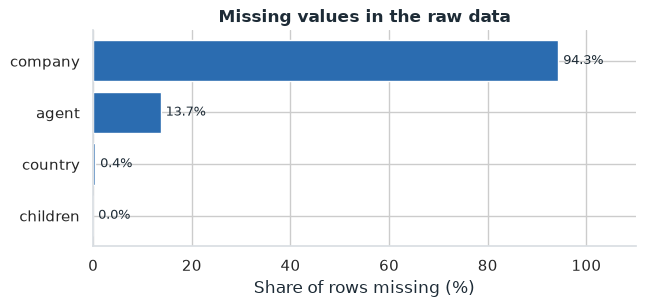

In [15]:
say(f"""
- **{audit['exact_duplicate_rows']:,} rows are exact duplicates** of another row
  ({audit['exact_duplicate_rows'] / audit['rows']:.1%} of the data). There is no booking ID, so repeated
  rows cannot be told apart from repeated bookings; Sections 3.2 and 3.7 deal with them.
- Missing values: {', '.join(f'`{k}` {v:,}' for k, v in audit['missing_values'].items())}.
""")
finish_figure(plot_missingness(raw.drop(columns="row_id")), "eda_missingness", ctx)

**Missing values.** Missing `company` and `agent` are not errors: they mean the booking had no company
or agent, so they become features ("has a company", and "none" as an agent code). Missing `children`
means none. Missing `country` becomes its own category (country is not a deployed feature anyway).
Nothing is imputed with a statistic, so nothing is learned from the data at this stage.

**Inconsistencies.** Every logical check that was run, how many rows it catches and what is done:

In [16]:
quality = quality_audit(raw, cfg)
inconsistencies = pd.DataFrame(quality["inconsistencies"])
display(inconsistencies.assign(share=inconsistencies["share"].map("{:.2%}".format)))

,check,rows,share,action,why
0,Booking for zero guests,180,0.15%,removed,A booking for nobody is a data-entry error.
1,Negative price per night,1,0.00%,removed,Impossible.
2,Price above 1000 per night,1,0.00%,removed,"A single row, far above every other price in the data."
3,Meal code 'Undefined',1169,0.98%,merged into SC,The dataset paper says both codes mean no meal package.
4,Children count missing,4,0.00%,set to 0,Missing means none.
5,Country missing,488,0.41%,own category,Country is not a deployed feature; it is used only in the leakage audit.
6,Zero nights booked,715,0.60%,kept,Day-use rooms and same-day departures exist in hotels.
7,Price of exactly 0,1959,1.64%,kept,Complimentary stays and staff bookings are real.
8,"No adults, only children or babies",223,0.19%,kept,Usually an extra room attached to a family booking.
9,Market segment or channel 'Undefined',5,0.00%,kept,A handful of rows; the encoder groups rare categories together.


**Outliers.** The usual rule of thumb (more than 1.5 interquartile ranges above the upper quartile)
flags thousands of rows in every skewed column, so it cannot be applied blindly. Each column is judged
on whether the extreme values are *impossible* (removed) or merely *rare* (kept):

,column,median,p99,max,upper_fence,rows_above_fence,share_above_fence,decision
0,lead_time,69.000,444.0,737.0,373.000,3005,2.5%,"kept: bookings a year or more ahead are real (groups, events); the model uses log(1 + lead time)"
1,adr,94.575,252.0,5400.0,211.065,3793,3.2%,kept up to 1000; the single value above it is removed
2,stays_in_week_nights,2.000,10.0,50.0,6.000,3354,2.8%,kept: long stays are real
3,stays_in_weekend_nights,1.000,4.0,19.0,5.000,265,0.2%,kept: long stays are real
4,adults,2.000,3.0,55.0,2.000,6280,5.3%,kept: large parties are group bookings
5,children,0.000,2.0,10.0,0.000,8590,7.2%,kept
6,babies,0.000,0.0,10.0,0.000,917,0.8%,kept
7,previous_cancellations,0.000,1.0,26.0,0.000,6484,5.4%,"kept: a strong, legitimate signal"
8,previous_bookings_not_canceled,0.000,3.0,72.0,0.000,3620,3.0%,"kept: a strong, legitimate signal"


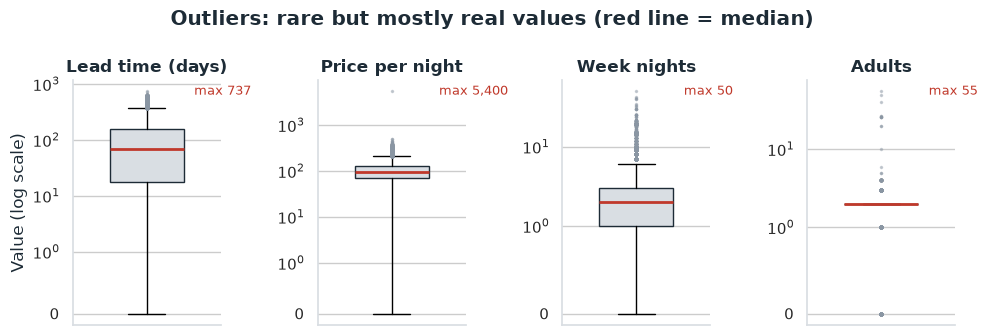

In [17]:
outliers = pd.DataFrame(quality["outliers"])
display(outliers.assign(share_above_fence=outliers["share_above_fence"].map("{:.1%}".format)))
finish_figure(plot_outliers(raw), "eda_outliers", ctx)

Only values that cannot be real are removed (a negative price, one price of 5,400 per night, bookings
for zero guests). Long lead times, long stays and large parties are rare but genuine, and they are
exactly the bookings a hotel worries about, so deleting them would make the model worse where it
matters. They are handled in the model instead: tree models split on the order of values and are
insensitive to how extreme a value is, and for the linear models lead time enters as a logarithm and
every numeric feature is standardised (3.4).

### 3.2 Data cleaning

Every rule is fixed and documented; none is learned from the data, so cleaning can run before the
split without leaking information. The log records how many rows each rule removed or changed.

**Duplicates are removed before splitting.** If they were kept, copies of the same row would land
in both the training and the test set, and the model would be graded partly on rows it had memorised.
Removing them is the cautious reading of ambiguous data (one row per distinct booking record);
Section 3.7 measures what the choice does to the score and what the repeated rows actually are.

In [18]:
# Copied from hotel_cancellation.cleaning by scripts/build_notebooks.py
from __future__ import annotations

def clean_bookings(df: pd.DataFrame, cfg: Config, drop_duplicates: bool | None = None) -> tuple[pd.DataFrame, list[dict]]:
    """Apply the cleaning rules in order and return the cleaned frame and a log."""
    drop_dups = cfg.cleaning.drop_duplicates if drop_duplicates is None else drop_duplicates
    out = df.copy()
    log: list[dict] = []

    def record(rule: str, before: int, why: str, changed: int | None = None) -> None:
        log.append({"rule": rule, "rows_before": before, "rows_after": len(out),
                    "rows_removed": before - len(out), "values_changed": changed, "why": why})

    data_cols = [c for c in out.columns if c != "row_id"]
    if drop_dups:
        before = len(out)
        out = out[~out.duplicated(subset=data_cols, keep="first")]
        record("drop_exact_duplicates", before,
               "Identical rows would land in both train and test and inflate scores.")

    before = len(out)
    guests = out["adults"] + out["children"].fillna(0) + out["babies"]
    out = out[guests > 0]
    record("drop_zero_guests", before, "A booking for nobody is a data-entry error.")

    before = len(out)
    out = out[out["adr"] >= 0]
    record("drop_negative_price", before, "A negative nightly rate is impossible.")

    before = len(out)
    out = out[out["adr"] <= cfg.cleaning.max_valid_adr]
    record("drop_extreme_price", before,
           f"Rates above {cfg.cleaning.max_valid_adr:.0f} per night are entry errors in this data.")

    before = len(out)
    n = int(out["children"].isna().sum())
    out["children"] = out["children"].fillna(0)
    record("fill_children_missing_as_zero", before, "Missing children count means none.", n)

    n = int(out["country"].isna().sum())
    out["country"] = out["country"].fillna("UNK")
    record("fill_country_missing_as_UNK", len(out), "Kept as its own category.", n)

    n = int((out["meal"] == "Undefined").sum())
    out["meal"] = out["meal"].replace({"Undefined": cfg.cleaning.fill_meal_undefined_as})
    record("merge_meal_undefined_into_SC", len(out), "Dataset paper: both codes mean no meal package.", n)

    record("keep_agent_company_missing", len(out),
           "Missing agent or company means the booking had none; handled as a feature.", 0)
    return out.reset_index(drop=True), log

,rule,rows_before,rows_after,rows_removed,values_changed,why
0,drop_exact_duplicates,119390,87396,31994,NaN,Identical rows would land in both train and test and inflate scores.
1,drop_zero_guests,87396,87230,166,NaN,A booking for nobody is a data-entry error.
2,drop_negative_price,87230,87229,1,NaN,A negative nightly rate is impossible.
3,drop_extreme_price,87229,87228,1,NaN,Rates above 1000 per night are entry errors in this data.
4,fill_children_missing_as_zero,87228,87228,0,4.0,Missing children count means none.
5,fill_country_missing_as_UNK,87228,87228,0,447.0,Kept as its own category.
6,merge_meal_undefined_into_SC,87228,87228,0,492.0,Dataset paper: both codes mean no meal package.
7,keep_agent_company_missing,87228,87228,0,0.0,Missing agent or company means the booking had none; handled as a feature.


After cleaning, **87,228 bookings** remain. The removed duplicate rows have a cancellation rate of **63.1%**: the duplicates are mostly cancellations, so they also change the class balance.

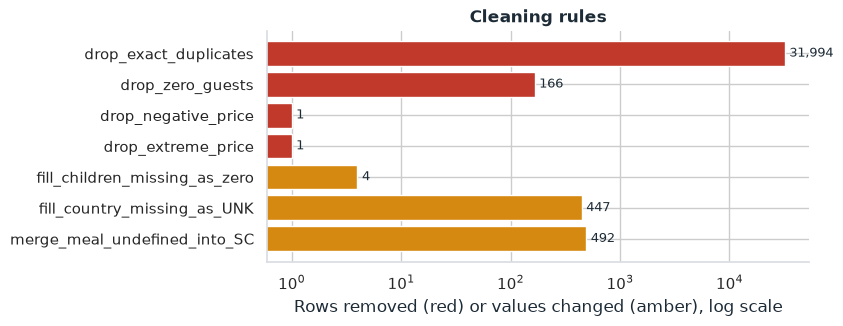

In [19]:
clean, cleaning_log = clean_bookings(raw, cfg)
data_cols = [c for c in raw.columns if c != "row_id"]
duplicate_rows_cancel_rate = float(raw.loc[raw.duplicated(subset=data_cols), cfg.target].mean())
rows_after_cleaning = len(clean)
display(pd.DataFrame(cleaning_log)[["rule", "rows_before", "rows_after", "rows_removed", "values_changed", "why"]])
say(f"After cleaning, **{rows_after_cleaning:,} bookings** remain. The removed duplicate rows have a "
    f"cancellation rate of **{duplicate_rows_cancel_rate:.1%}**: the duplicates are mostly cancellations, "
    "so they also change the class balance.")
finish_figure(plot_cleaning_log(cleaning_log), "eda_cleaning_rules", ctx)

### 3.3 Data splitting

Stratified split into **70% training, 15% validation and 15% test**. Stratification keeps the same
cancellation rate in every part. Roles:

- **Training:** fitting models, and cross-validation for tuning.
- **Validation:** choosing the champion, calibrating it and choosing the threshold.
- **Test:** the final evaluation of a list of models declared in advance (Section 8).

A fingerprint of the test rows is recorded so the pipeline and this notebook can prove they used the
same split. A second, time-based split (train on earlier arrivals, score the next year) is used as a
robustness check in Section 6.6, because a hotel would train on the past and predict the future.

In [20]:
# Copied from hotel_cancellation.split by scripts/build_notebooks.py
from __future__ import annotations

def stratified_split(df: pd.DataFrame, target: str, val_size: float, test_size: float,
                     seed: int) -> dict[str, np.ndarray]:
    """Stratified train/validation/test positions (fractions are of the whole frame)."""
    positions = np.arange(len(df))
    rest, test = train_test_split(positions, test_size=test_size, stratify=df[target], random_state=seed)
    train, val = train_test_split(rest, test_size=val_size / (1 - test_size),
                                  stratify=df[target].iloc[rest], random_state=seed)
    return {"train": np.sort(train), "validation": np.sort(val), "test": np.sort(test)}


def rows_hash(row_ids) -> str:
    """Fingerprint of a set of original rows, used to prove two runs used the same split."""
    joined = ",".join(str(i) for i in sorted(int(x) for x in row_ids))
    return hashlib.sha256(joined.encode()).hexdigest()


def split_summary(df: pd.DataFrame, splits: dict[str, np.ndarray], target: str) -> dict:
    out = {}
    for name, pos in splits.items():
        part = df.iloc[pos]
        out[name] = {"rows": int(len(part)), "positive_rate": float(part[target].mean())}
    out["test_rows_sha256"] = rows_hash(df.iloc[splits["test"]]["row_id"])
    return out


def temporal_positions(df: pd.DataFrame, train_until_year: int) -> tuple[np.ndarray, np.ndarray]:
    """Earlier arrivals for fitting, the following year for evaluation."""
    years = df["arrival_date_year"].to_numpy()
    return np.flatnonzero(years <= train_until_year), np.flatnonzero(years == train_until_year + 1)


def sample_for_fast_mode(clean: pd.DataFrame, cfg: Config) -> pd.DataFrame:
    """In fast mode only, keep a stratified sample so smoke runs finish in minutes."""
    if not cfg.sample_rows or len(clean) <= cfg.sample_rows:
        return clean
    keep, _ = train_test_split(np.arange(len(clean)), train_size=cfg.sample_rows,
                               stratify=clean[cfg.target], random_state=cfg.seed)
    return clean.iloc[np.sort(keep)].reset_index(drop=True)

In [21]:
clean = sample_for_fast_mode(clean, cfg)  # does nothing unless ML_FAST=1
splits = stratified_split(clean, cfg.target, cfg.split.val_size, cfg.split.test_size, cfg.seed)
split_info = split_summary(clean, splits, cfg.target)
display(pd.DataFrame({k: v for k, v in split_info.items() if k != "test_rows_sha256"}).T)
print("Test rows fingerprint:", split_info["test_rows_sha256"][:16], "...")
trval = clean.iloc[np.sort(np.concatenate([splits["train"], splits["validation"]]))]

,rows,positive_rate
train,61058.0,0.275246
validation,13085.0,0.275201
test,13085.0,0.275201


Test rows fingerprint: 4e2bceeeebaa0bdd ...


### 3.4 Feature engineering

All per-row feature logic lives in one small pure-Python module (below). The training code applies it
to every row, and the deployed API runs **the same file**, so the features cannot differ between
training and serving. Features are grouped by the raw column they come from, so the leakage audit can
add or remove whole groups.

**New features created from existing ones:**

| Feature | How it is made | Why |
|---|---|---|
| `log_lead_time` | log(1 + lead time) | Lead time is very skewed; the log suits linear models (trees don't mind) |
| `arrival_week`, `arrival_weekday` | From the assembled arrival date | Weekly and weekday patterns |
| `month_sin`, `month_cos` | Cyclical encoding of the month | December and January are neighbours |
| `total_nights`, `weekend_share` | From the two stay columns | Length and type of stay |
| `total_guests`, `is_family` | From adults, children, babies | Party size and families |
| `has_booking_history`, `prior_cancel_ratio` | From previous cancellations and stays | A guest's track record |
| `agent_id`, `has_company` | Missing means none | Who sold the booking |
| `adr_per_person` | Price over paying guests | Price relative to party size |

**Encoding categorical variables and scaling numeric ones.** These steps are learned from data, so they
live inside the model pipeline and are refitted in every cross-validation fold (fitting them once on all
rows would leak information from the held-out fold):

- **Tree models:** categories become integer codes (ordinal encoding); categories seen fewer than 30
  times in training share one code, and categories never seen get their own "unknown" code. No scaling:
  trees split on the order of values, so scaling changes nothing.
- **Linear models and the neural network:** one-hot encoding with the same grouping of rare categories,
  and standardised numeric features (mean 0, standard deviation 1), which these models need.

Section 5 compares ordinal, one-hot and target encoding directly, and tests whether a further group of
engineered features (`candidate_features` below) is worth adding.

In [22]:
# Copied from hotel_cancellation.rowlevel by scripts/build_notebooks.py
from __future__ import annotations

MONTH_NUMBERS = {
    "January": 1, "February": 2, "March": 3, "April": 4, "May": 5, "June": 6, "July": 7,
    "August": 8, "September": 9, "October": 10, "November": 11, "December": 12,
}


CATEGORICAL_FEATURES = frozenset({
    "hotel", "meal", "market_segment", "distribution_channel", "reserved_room_type",
    "deposit_type", "customer_type", "agent_id", "company_id", "country", "assigned_room_type",
    "reservation_status",
})


HOME_COUNTRY = "PRT"


def is_missing(value) -> bool:
    """True for None and NaN (pandas passes missing numbers as float NaN)."""
    return value is None or (isinstance(value, float) and value != value)


def as_number(value, default: float = 0.0) -> float:
    return default if is_missing(value) else float(value)


def arrival_date(r: dict) -> date:
    return date(int(r["arrival_date_year"]), MONTH_NUMBERS[r["arrival_date_month"]],
                int(r["arrival_date_day_of_month"]))


def base_features(r: dict) -> dict:
    """Features known when the booking is made."""
    arrival = arrival_date(r)
    weekend = as_number(r["stays_in_weekend_nights"])
    weekday = as_number(r["stays_in_week_nights"])
    nights = weekend + weekday
    adults = as_number(r["adults"])
    children = as_number(r["children"])
    babies = as_number(r["babies"])
    prev_cancelled = as_number(r["previous_cancellations"])
    prev_kept = as_number(r["previous_bookings_not_canceled"])
    history = prev_cancelled + prev_kept
    month_angle = 2 * math.pi * (arrival.month - 1) / 12
    return {
        "hotel": str(r["hotel"]),
        "meal": str(r["meal"]),
        "market_segment": str(r["market_segment"]),
        "distribution_channel": str(r["distribution_channel"]),
        "reserved_room_type": str(r["reserved_room_type"]),
        "deposit_type": str(r["deposit_type"]),
        "customer_type": str(r["customer_type"]),
        "agent_id": "none" if is_missing(r.get("agent")) else str(int(r["agent"])),
        "log_lead_time": math.log1p(as_number(r["lead_time"])),
        "arrival_week": float(arrival.isocalendar()[1]),
        "arrival_weekday": float(arrival.weekday()),
        "month_sin": math.sin(month_angle),
        "month_cos": math.cos(month_angle),
        "stays_in_weekend_nights": weekend,
        "stays_in_week_nights": weekday,
        "total_nights": nights,
        "weekend_share": weekend / nights if nights > 0 else 0.0,
        "adults": adults,
        "children": children,
        "babies": babies,
        "total_guests": adults + children + babies,
        "is_family": 1.0 if children + babies > 0 else 0.0,
        "is_repeated_guest": as_number(r["is_repeated_guest"]),
        "previous_cancellations": prev_cancelled,
        "previous_bookings_not_canceled": prev_kept,
        "has_booking_history": 1.0 if history > 0 else 0.0,
        "prior_cancel_ratio": prev_cancelled / history if history > 0 else 0.0,
        "has_company": 0.0 if is_missing(r.get("company")) else 1.0,
    }


def adr_features(r: dict) -> dict:
    """Price per night, total and per paying guest (babies excluded)."""
    adr = as_number(r["adr"])
    paying = max(as_number(r["adults"]) + as_number(r["children"]), 1.0)
    return {"adr": adr, "adr_per_person": adr / paying}


def parking_features(r: dict) -> dict:
    return {"required_car_parking_spaces": as_number(r["required_car_parking_spaces"])}


def requests_features(r: dict) -> dict:
    return {"total_of_special_requests": as_number(r["total_of_special_requests"])}


def country_features(r: dict) -> dict:
    country = "UNK" if is_missing(r.get("country")) else str(r["country"])
    return {"country": country, "is_domestic": 1.0 if country == HOME_COUNTRY else 0.0}


def candidate_features(r: dict) -> dict:
    """More booking-time features, all legitimate, tested in the notebook and not adopted.

    The booking date is the arrival date minus the lead time, so it is known on the day of booking.
    """
    arrival = arrival_date(r)
    booked = arrival - timedelta(days=int(as_number(r["lead_time"])))
    nights = as_number(r["stays_in_weekend_nights"]) + as_number(r["stays_in_week_nights"])
    booked_angle = 2 * math.pi * (booked.month - 1) / 12
    return {
        "company_id": "none" if is_missing(r.get("company")) else str(int(r["company"])),
        "booking_weekday": float(booked.weekday()),
        "booking_month_sin": math.sin(booked_angle),
        "booking_month_cos": math.cos(booked_angle),
        "booking_day_of_year": float(booked.timetuple().tm_yday),
        "arrival_day_of_year": float(arrival.timetuple().tm_yday),
        "arrival_day_of_month": float(arrival.day),
        "stay_value": as_number(r["adr"]) * nights,
    }


def tier2_features(r: dict) -> dict:
    """Known only after booking: used in the leakage ablation, never deployed."""
    return {
        "assigned_room_type": str(r["assigned_room_type"]),
        "room_changed": 1.0 if r["assigned_room_type"] != r["reserved_room_type"] else 0.0,
        "booking_changes": as_number(r["booking_changes"]),
        "days_in_waiting_list": as_number(r["days_in_waiting_list"]),
    }


def tier1_features(r: dict) -> dict:
    """The outcome itself: used only to show what leakage looks like."""
    status_day = date.fromisoformat(str(r["reservation_status_date"])[:10])
    return {
        "reservation_status": str(r["reservation_status"]),
        "status_days_before_arrival": float((arrival_date(r) - status_day).days),
    }


FEATURE_SOURCES = {
    "base": base_features,
    "adr": adr_features,
    "required_car_parking_spaces": parking_features,
    "total_of_special_requests": requests_features,
    "country": country_features,
    "candidate": candidate_features,
    "tier2": tier2_features,
    "tier1": tier1_features,
}


def derive_features(r: dict, sources: list[str]) -> dict:
    """All features from the given groups, in a stable order."""
    out: dict = {}
    for source in sources:
        out.update(FEATURE_SOURCES[source](r))
    return out

In [23]:
# Copied from hotel_cancellation.features by scripts/build_notebooks.py
from __future__ import annotations

def build_feature_frame(df: pd.DataFrame, sources: list[str]) -> pd.DataFrame:
    """Run ``derive_features`` on every row; the index is kept so labels stay aligned."""
    rows = [derive_features(r, sources) for r in df.to_dict("records")]
    return pd.DataFrame(rows, index=df.index)


def split_feature_types(columns: list[str]) -> tuple[list[str], list[str]]:
    cats = [c for c in columns if c in CATEGORICAL_FEATURES]
    nums = [c for c in columns if c not in CATEGORICAL_FEATURES]
    return cats, nums


def to_float32(X) -> np.ndarray:
    """Trees are trained on float32 so the ONNX copy, which runs in float32, matches them."""
    return np.asarray(X, dtype=np.float32)


def make_tree_preprocessor(cats: list[str], nums: list[str], min_frequency: int) -> list:
    """Integer codes for categories (rare ones grouped, unseen ones -1), numbers unchanged."""
    columns = ColumnTransformer(
        [("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1,
                                min_frequency=min_frequency), cats),
         ("num", "passthrough", nums)],
        verbose_feature_names_out=False,
    )
    return [("prep", columns), ("float32", FunctionTransformer(to_float32))]


def make_linear_preprocessor(cats: list[str], nums: list[str], min_frequency: int) -> list:
    """One-hot categories (rare and unseen ones share a column), standardised numbers."""
    columns = ColumnTransformer(
        [("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=min_frequency,
                               sparse_output=False), cats),
         ("num", StandardScaler(), nums)],
        verbose_feature_names_out=False,
    )
    return [("prep", columns)]

In [24]:
example = derive_features(clean.iloc[0].to_dict(), deployed_sources(cfg))
pd.Series(example, name="first booking").to_frame()

,first booking
hotel,Resort Hotel
meal,BB
market_segment,Direct
distribution_channel,Direct
reserved_room_type,C
deposit_type,No Deposit
customer_type,Transient
agent_id,none
log_lead_time,5.83773
arrival_week,27.0


### 3.5 Exploratory data analysis (training and validation rows only)

Organised from one variable at a time, to pairs, to many variables together.

**Univariate: distributions.** Most numeric columns are strongly right-skewed (the mean is well above
the median), which is why the outlier rule in 3.1 flags so many rows.

In [25]:
numeric_view = ["lead_time", "adr", "stays_in_week_nights", "stays_in_weekend_nights", "adults", "children",
                "previous_cancellations", "previous_bookings_not_canceled"]
display(trval[numeric_view].describe().T[["mean", "50%", "std", "min", "max"]].rename(columns={"50%": "median"}).round(2))

,mean,median,std,min,max
lead_time,79.83,49.0,85.89,0.0,737.0
adr,106.64,98.6,51.89,0.0,508.0
stays_in_week_nights,2.62,2.0,2.04,0.0,50.0
stays_in_weekend_nights,1.00,1.0,1.03,0.0,19.0
adults,1.88,2.0,0.60,0.0,50.0
children,0.14,0.0,0.46,0.0,10.0
previous_cancellations,0.03,0.0,0.39,0.0,26.0
previous_bookings_not_canceled,0.19,0.0,1.76,0.0,72.0


**Univariate: the target.** After deduplication the classes are moderately imbalanced.

Cancellation rate in training + validation: **27.5%** (before deduplication it was 37.0%).

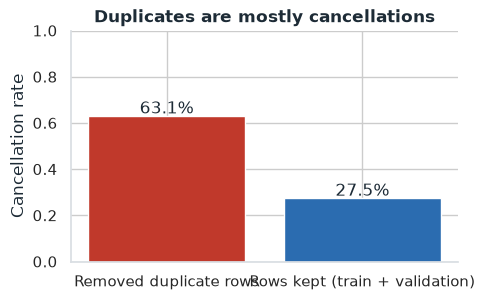

In [26]:
rate = trval[cfg.target].mean()
say(f"Cancellation rate in training + validation: **{rate:.1%}** "
    f"(before deduplication it was {audit['target_rate']:.1%}).")
finish_figure(plot_duplicate_effect(duplicate_rows_cancel_rate, float(rate)), "eda_duplicates_are_cancellations", ctx)

**Bivariate: cancellation rate by category.**

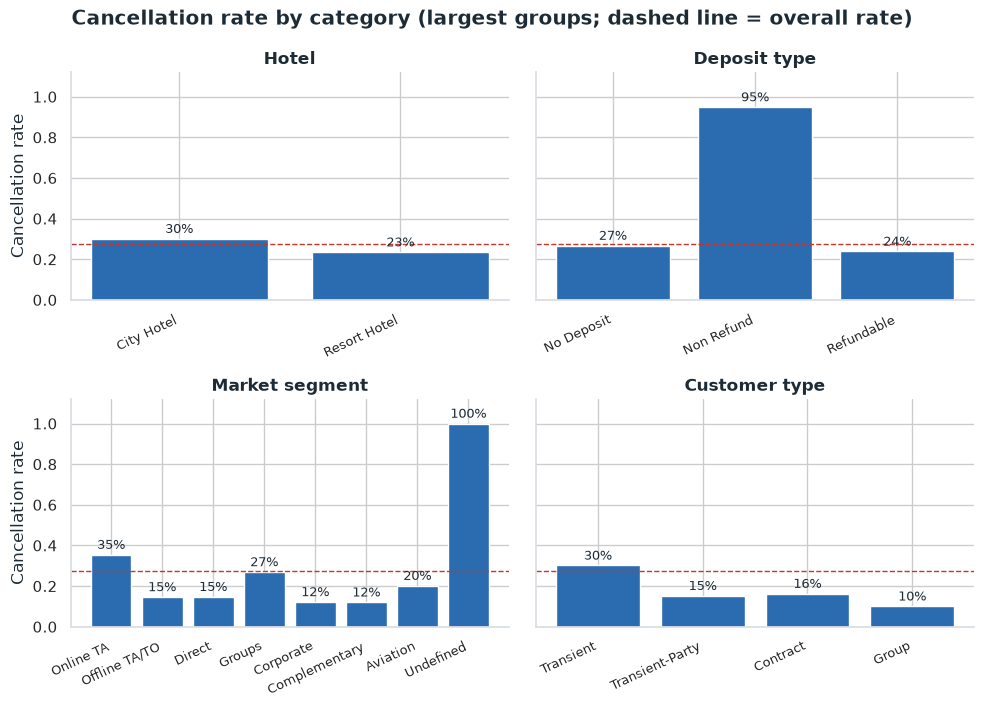

The **Non Refund** deposit shows a cancellation rate of **94.9%** over 860 bookings, against 26.7% with no deposit. Common sense says a non-refundable booking should rarely be cancelled. The likely explanation is that these are mostly block bookings by tour operators and groups that are released in bulk, so the label reflects how the hotels record such blocks. The deposit type is known at booking time, so it stays as a feature, but it is an example of why a high score should never be taken at face value (Section 3.7 comes back to it).

In [27]:
finish_figure(plot_rate_by_category(trval, ["hotel", "deposit_type", "market_segment", "customer_type"],
                                    cfg.target), "eda_rate_by_category", ctx)
nonref = trval.groupby("deposit_type")[cfg.target].agg(["mean", "size"])
say(f"The **Non Refund** deposit shows a cancellation rate of **{nonref.loc['Non Refund', 'mean']:.1%}** "
    f"over {int(nonref.loc['Non Refund', 'size']):,} bookings, against "
    f"{nonref.loc['No Deposit', 'mean']:.1%} with no deposit. Common sense says a non-refundable booking "
    "should rarely be cancelled. The likely explanation is that these are mostly block bookings by tour "
    "operators and groups that are released in bulk, so the label reflects how the hotels record such "
    "blocks. The deposit type is known at booking time, so it stays as a feature, but it is an example of "
    "why a high score should never be taken at face value (Section 3.7 comes back to it).")

**Bivariate: numeric features by outcome.** Cancelled bookings were made much further ahead.

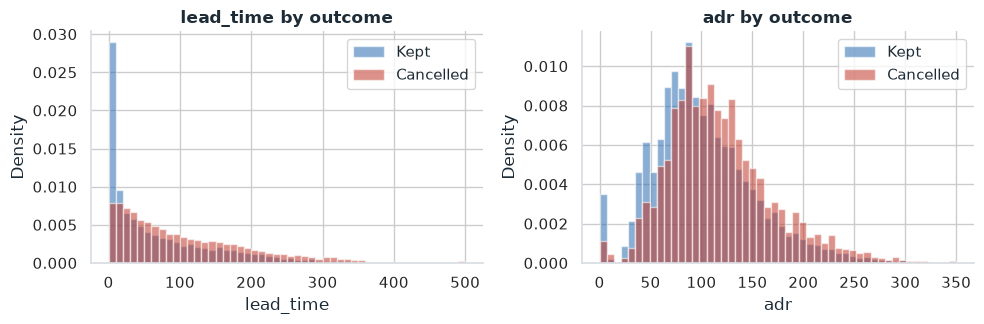

Median lead time: **80 days** for cancelled bookings, **38 days** for kept ones.

In [28]:
finish_figure(plot_numeric_by_outcome(trval, cfg.target), "eda_numeric_by_outcome", ctx)
med = trval.groupby(cfg.target)["lead_time"].median()
say(f"Median lead time: **{med.loc[1]:.0f} days** for cancelled bookings, **{med.loc[0]:.0f} days** for kept ones.")

**Trend and seasonality.** The cancellation rate moves with the season and over the years, which is a
first hint that the relationship may drift over time (examined in Section 6.6 and Section 10).

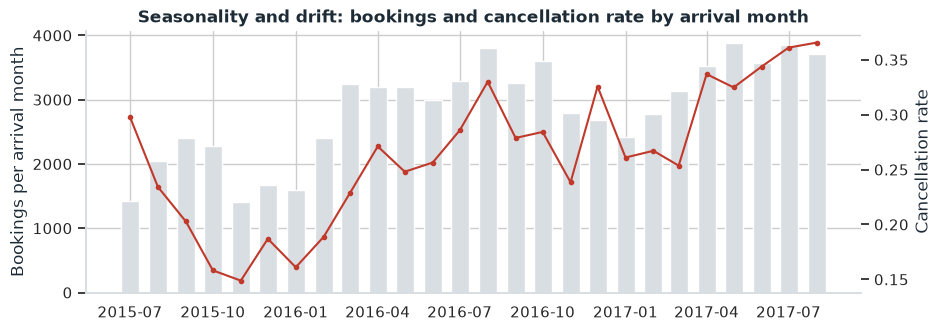

In [29]:
finish_figure(plot_monthly_rate(trval, cfg.target), "eda_monthly_rate", ctx)

**Multivariate: correlations and a PCA projection.** The correlation map shows groups of related
features (for example the stay-length features) and which ones move with the target. The PCA view is
an unsupervised look at the numeric features: the classes overlap heavily, so no single direction
separates them and a non-linear model is likely to help.

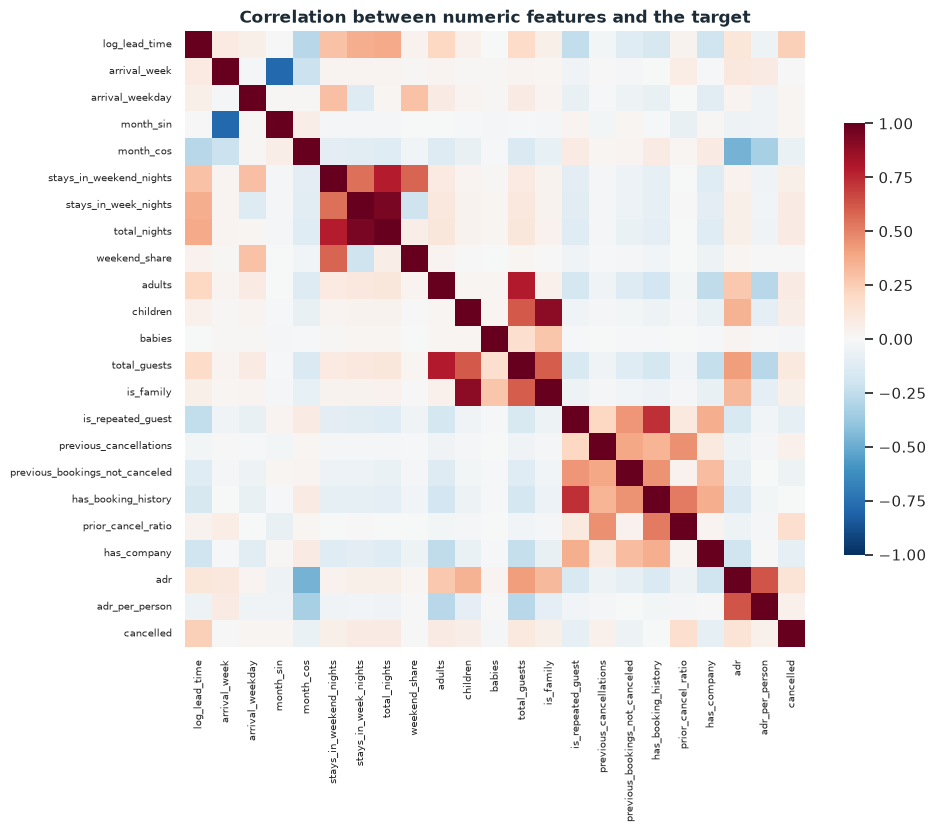

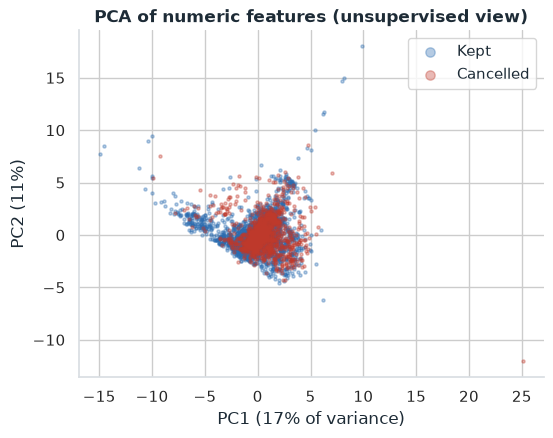

In [30]:
eda_features = build_feature_frame(trval, deployed_sources(cfg))
finish_figure(plot_correlation(eda_features, trval[cfg.target]), "eda_correlation", ctx)
finish_figure(plot_pca(eda_features, trval[cfg.target], cfg.seed), "eda_pca", ctx)

### 3.6 Leakage audit

This dataset is a snapshot taken after the outcome was known, not at booking, so some columns contain
values entered or changed after the booking was made. A model that uses them would look excellent here
and be useless in practice, because on the day of booking those values do not exist yet. Every column
is sorted into a tier:

| Tier | Columns | Treatment |
|---|---|---|
| 1. The outcome itself | `reservation_status`, `reservation_status_date` | Dropped |
| 2. Known only after booking | `assigned_room_type`, `booking_changes`, `days_in_waiting_list` | Excluded |
| 3. Timing uncertain | `required_car_parking_spaces`, `total_of_special_requests`, `adr`, `country` | Decided on evidence below |
| Never a feature | `arrival_date_year` | A model cannot generalise to a year it has not seen |

The audit trains LightGBM (the model family defined below, used here with default settings) on
training rows and scores validation rows; the test set is not used.

In [31]:
# Copied from hotel_cancellation.models by scripts/build_notebooks.py
from __future__ import annotations

LINEAR_KINDS = {"dummy", "logreg", "mlp"}


MODEL_NOTES = {
    "dummy": "Predicts the base rate for everyone. The floor every model must beat.",
    "logreg": "Linear in the features; every coefficient can be read directly.",
    "tree": "One readable tree, but unstable and prone to overfitting.",
    "rf": "Averages many trees; robust, but large to store and slower to score.",
    "hgb": "Gradient boosting in scikit-learn; strong and fast on tabular data.",
    "lgbm": "Gradient boosting in LightGBM; usually the strongest on tabular data. Explained with SHAP.",
    "mlp": "Small neural network; needs scaling, hardest to interpret.",
}


def base_estimator(kind: str, cfg: Config, **params):
    """The bare estimator for ``kind`` with fixed seeds and thread counts."""
    seed, jobs = cfg.seed, cfg.models.n_jobs
    if kind == "dummy":
        return DummyClassifier(strategy="prior")
    if kind == "logreg":
        return LogisticRegression(max_iter=3000, **params)
    if kind == "tree":
        return DecisionTreeClassifier(random_state=seed, **{"min_samples_leaf": 20, **params})
    if kind == "rf":
        defaults = {"n_estimators": 200, "min_samples_leaf": 5, "max_features": "sqrt"}
        return RandomForestClassifier(random_state=seed, n_jobs=jobs, **{**defaults, **params})
    if kind == "hgb":
        return HistGradientBoostingClassifier(random_state=seed, early_stopping=True, **params)
    if kind == "lgbm":
        defaults = {"n_estimators": 400, "learning_rate": 0.05, "num_leaves": 63}
        return LGBMClassifier(objective="binary", random_state=seed, n_jobs=jobs, deterministic=True,
                              force_row_wise=True, verbose=-1, **{**defaults, **params})
    if kind == "mlp":
        return MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-3, early_stopping=True,
                             max_iter=200, random_state=seed, **params)
    raise ValueError(f"unknown model kind: {kind}")


def make_model(kind: str, cats: list[str], nums: list[str], cfg: Config, **params) -> Pipeline:
    """Preprocessing plus estimator. Linear models and the MLP get one-hot and scaling."""
    minf = cfg.features.min_category_frequency
    prep = (make_linear_preprocessor(cats, nums, minf) if kind in LINEAR_KINDS
            else make_tree_preprocessor(cats, nums, minf))
    return Pipeline(prep + [("model", base_estimator(kind, cfg, **params))])


CANDIDATE_KINDS = ["dummy", "logreg", "tree", "rf", "hgb", "lgbm", "mlp"]

In [32]:
# Copied from hotel_cancellation.leakage by scripts/build_notebooks.py
from __future__ import annotations

def rate_table(frame: pd.DataFrame, column: str, target: str, top: int | None = None,
               by_size: bool = True) -> list[dict]:
    """Cancellation rate and row count per value of ``column``."""
    table = frame.groupby(column, observed=True)[target].agg(cancel_rate="mean", rows="size").reset_index()
    if by_size:
        table = table.sort_values("rows", ascending=False)
    if top:
        table = table.head(top)
    table[column] = table[column].astype(str)
    return table.rename(columns={column: "value"}).to_dict("records")


def tier3_evidence(trval: pd.DataFrame, cfg: Config) -> dict:
    """The tables behind each Tier 3 decision."""
    t = cfg.target
    bands = pd.qcut(trval["adr"], 10, duplicates="drop")
    labels = {iv: f"{max(iv.left, 0):.0f}-{iv.right:.0f}" for iv in bands.cat.categories}
    priced = trval.assign(price_band=bands.cat.rename_categories(labels))
    return {
        "required_car_parking_spaces": rate_table(trval, "required_car_parking_spaces", t),
        "total_of_special_requests": rate_table(trval, "total_of_special_requests", t),
        "country": rate_table(trval, "country", t, top=10),
        "adr": rate_table(priced, "price_band", t, by_size=False),
    }


def fit_and_score(sources: list[str], train: pd.DataFrame, val: pd.DataFrame, cfg: Config) -> float:
    """Validation ROC-AUC of LightGBM (default settings) on the given feature groups."""
    Xtr, Xva = build_feature_frame(train, sources), build_feature_frame(val, sources)
    cats, nums = split_feature_types(list(Xtr.columns))
    model = make_model("lgbm", cats, nums, cfg).fit(Xtr, train[cfg.target])
    return float(roc_auc_score(val[cfg.target], model.predict_proba(Xva)[:, 1]))


def leakage_ablation(train: pd.DataFrame, val: pd.DataFrame, cfg: Config) -> dict:
    """ROC-AUC as each tier of suspect columns is added back, plus each Tier 3 column alone."""
    f = cfg.features
    deployed = deployed_sources(cfg)
    steps = [
        ("Base features only", list(f.safe_sources)),
        ("Deployed (base + kept Tier 3)", deployed),
        ("+ all Tier 3 (timing uncertain)", list(f.safe_sources) + list(f.tier3_sources)),
        ("+ Tier 2 (known after booking)", list(f.safe_sources) + list(f.tier3_sources) + list(f.tier2_sources)),
        ("+ Tier 1 (the outcome itself)",
         list(f.safe_sources) + list(f.tier3_sources) + list(f.tier2_sources) + list(f.tier1_sources)),
    ]
    ladder = [{"step": name, "sources": src, "val_roc_auc": fit_and_score(src, train, val, cfg)}
              for name, src in steps]
    base_score = ladder[0]["val_roc_auc"]
    single = []
    for source in f.tier3_sources:
        score = fit_and_score(list(f.safe_sources) + [source], train, val, cfg)
        single.append({"column": source, "decision": cfg.leakage.tier3_decisions[source].decision,
                       "val_roc_auc": score, "gain_over_base": score - base_score})
    return {"ladder": ladder, "tier3_single": single}

In [33]:
# Copied from hotel_cancellation.robustness by scripts/build_notebooks.py
from __future__ import annotations

def dedup_sensitivity(raw: pd.DataFrame, cfg: Config, deduplicated_score: float) -> dict:
    """Validation ROC-AUC when duplicates are kept, compared with the deduplicated run.

    With duplicates kept, copies of training rows appear in validation, so the
    score is inflated. The gap is the size of that illusion.
    """
    kept, _ = clean_bookings(raw, cfg, drop_duplicates=False)
    splits = stratified_split(kept, cfg.target, cfg.split.val_size, cfg.split.test_size, cfg.seed)
    sources = deployed_sources(cfg)
    train, val = kept.iloc[splits["train"]], kept.iloc[splits["validation"]]
    Xtr, Xva = build_feature_frame(train, sources), build_feature_frame(val, sources)
    cats, nums = split_feature_types(list(Xtr.columns))
    model = make_model("lgbm", cats, nums, cfg).fit(Xtr, train[cfg.target])
    with_dups = float(roc_auc_score(val[cfg.target], model.predict_proba(Xva)[:, 1]))
    val_rows_seen_in_train = int(val.drop(columns="row_id").merge(
        train.drop(columns="row_id").drop_duplicates(), how="inner").shape[0])
    return {"val_roc_auc_deduplicated": deduplicated_score, "val_roc_auc_duplicates_kept": with_dups,
            "inflation": with_dups - deduplicated_score,
            "share_of_val_rows_also_in_train_when_kept": val_rows_seen_in_train / len(val)}


BOOKING_TIME_COLUMNS = [
    "hotel", "lead_time", "arrival_date_year", "arrival_date_month", "arrival_date_day_of_month",
    "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children", "babies", "meal",
    "market_segment", "distribution_channel", "is_repeated_guest", "previous_cancellations",
    "previous_bookings_not_canceled", "reserved_room_type", "deposit_type", "agent", "company",
    "customer_type", "adr",
]


def duplicate_decomposition(raw: pd.DataFrame, clean: pd.DataFrame, splits: dict, cfg: Config,
                            repeats: int = 3) -> dict:
    """Why does keeping the duplicates raise the score? Memorisation, or a different population?

    Uses training and validation bookings only: every row that shares its booking-time inputs
    with a test booking is removed first. Duplicates are then kept, and LightGBM (default
    settings, deployed features) is scored three ways, averaged over ``repeats`` splits:

    1. random split: copies of a booking can sit on both sides (what a careless pipeline does);
    2. grouped split: all rows with the same booking-time inputs stay on one side, so nothing
       can be memorised, and every row is scored;
    3. the same grouped split, scoring one row per distinct record (the deduplicated view).

    1 minus 2 is memorisation. 2 minus 3 is the effect of counting the repeated rows, which are
    a different and easier population. The last score drops the non-refundable bookings, which
    are almost always cancelled, to show where that easy signal sits.
    """
    from sklearn.model_selection import GroupShuffleSplit, train_test_split

    t = cfg.target
    kept, _ = clean_bookings(raw, cfg, drop_duplicates=False)
    record_cols = [c for c in kept.columns if c != "row_id"]
    kept = kept.assign(inputs=kept.groupby(BOOKING_TIME_COLUMNS, dropna=False, sort=False).ngroup())
    test_inputs = clean.iloc[splits["test"]][BOOKING_TIME_COLUMNS].drop_duplicates().merge(
        kept[BOOKING_TIME_COLUMNS + ["inputs"]].drop_duplicates(), on=BOOKING_TIME_COLUMNS, how="left")["inputs"]
    pool = kept[~kept["inputs"].isin(set(test_inputs))].reset_index(drop=True)
    copies = pool.groupby(record_cols, dropna=False, sort=False)[t].transform("size").to_numpy()
    repeated, single = pool[copies > 1], pool[copies == 1]
    sources = deployed_sources(cfg)
    X, y = build_feature_frame(pool, sources), pool[t]
    cats, nums = split_feature_types(list(X.columns))
    holdout = cfg.split.val_size / (1 - cfg.split.test_size)
    positions = pd.RangeIndex(len(pool)).to_numpy()
    scores: dict[str, list[float]] = {"random": [], "grouped": [], "grouped_one_per_record": [],
                                      "grouped_without_non_refundable": []}
    for i in range(repeats):
        seed = cfg.seed + i
        fit, ev = train_test_split(positions, test_size=holdout, stratify=y, random_state=seed)
        model = make_model("lgbm", cats, nums, cfg).fit(X.iloc[fit], y.iloc[fit])
        scores["random"].append(roc_auc_score(y.iloc[ev], model.predict_proba(X.iloc[ev])[:, 1]))
        fit, ev = next(GroupShuffleSplit(1, test_size=holdout, random_state=seed).split(positions, groups=pool["inputs"]))
        model = make_model("lgbm", cats, nums, cfg).fit(X.iloc[fit], y.iloc[fit])
        proba, part = model.predict_proba(X.iloc[ev])[:, 1], pool.iloc[ev]
        truth = y.iloc[ev].to_numpy()
        first = ~part.duplicated(subset=record_cols).to_numpy()
        refundable = (part["deposit_type"] != "Non Refund").to_numpy()
        scores["grouped"].append(roc_auc_score(truth, proba))
        scores["grouped_one_per_record"].append(roc_auc_score(truth[first], proba[first]))
        scores["grouped_without_non_refundable"].append(roc_auc_score(truth[refundable], proba[refundable]))
    mean = {k: float(sum(v) / len(v)) for k, v in scores.items()}

    def profile(frame: pd.DataFrame) -> dict:
        return {"rows": int(len(frame)), "cancel_rate": float(frame[t].mean()),
                "share_groups_segment": float((frame["market_segment"] == "Groups").mean()),
                "share_non_refundable": float((frame["deposit_type"] == "Non Refund").mean())}

    non_refundable = pool[pool["deposit_type"] == "Non Refund"]
    return {"rows": int(len(pool)), "repeats": repeats,
            "roc_auc_random_split": mean["random"], "roc_auc_grouped_split": mean["grouped"],
            "roc_auc_grouped_one_per_record": mean["grouped_one_per_record"],
            "roc_auc_grouped_without_non_refundable": mean["grouped_without_non_refundable"],
            "memorisation": mean["random"] - mean["grouped"],
            "population": mean["grouped"] - mean["grouped_one_per_record"],
            "rows_with_copies": profile(repeated), "rows_without_copies": profile(single),
            "non_refundable": {"rows": int(len(non_refundable)), "cancel_rate": float(non_refundable[t].mean())}}


def temporal_check(trval: pd.DataFrame, params: dict, cfg: Config) -> dict:
    """Fit on earlier arrivals, score the next year, month by month."""
    fit_pos, eval_pos = temporal_positions(trval, cfg.split.temporal_train_until_year)
    sources = deployed_sources(cfg)
    early, late = trval.iloc[fit_pos], trval.iloc[eval_pos]
    Xe, Xl = build_feature_frame(early, sources), build_feature_frame(late, sources)
    cats, nums = split_feature_types(list(Xe.columns))
    model = make_model("lgbm", cats, nums, cfg, **params).fit(Xe, early[cfg.target])
    proba = model.predict_proba(Xl)[:, 1]
    frame = pd.DataFrame({"month": late["arrival_date_month"].to_numpy(), "y": late[cfg.target].to_numpy(),
                          "p": proba})
    order = {m: i for i, m in enumerate(["January", "February", "March", "April", "May", "June", "July",
                                         "August", "September", "October", "November", "December"])}
    by_month = []
    for month, part in sorted(frame.groupby("month"), key=lambda kv: order[kv[0]]):
        by_month.append({"month": month, "rows": int(len(part)), "cancel_rate": float(part["y"].mean()),
                         "roc_auc": float(roc_auc_score(part["y"], part["p"]))})
    return {"fit_years": f"<= {cfg.split.temporal_train_until_year}",
            "eval_year": cfg.split.temporal_train_until_year + 1,
            "fit_rows": int(len(early)), "eval_rows": int(len(late)),
            "eval_roc_auc": float(roc_auc_score(late[cfg.target], proba)), "by_month": by_month,
            "model": model, "eval_proba": proba}

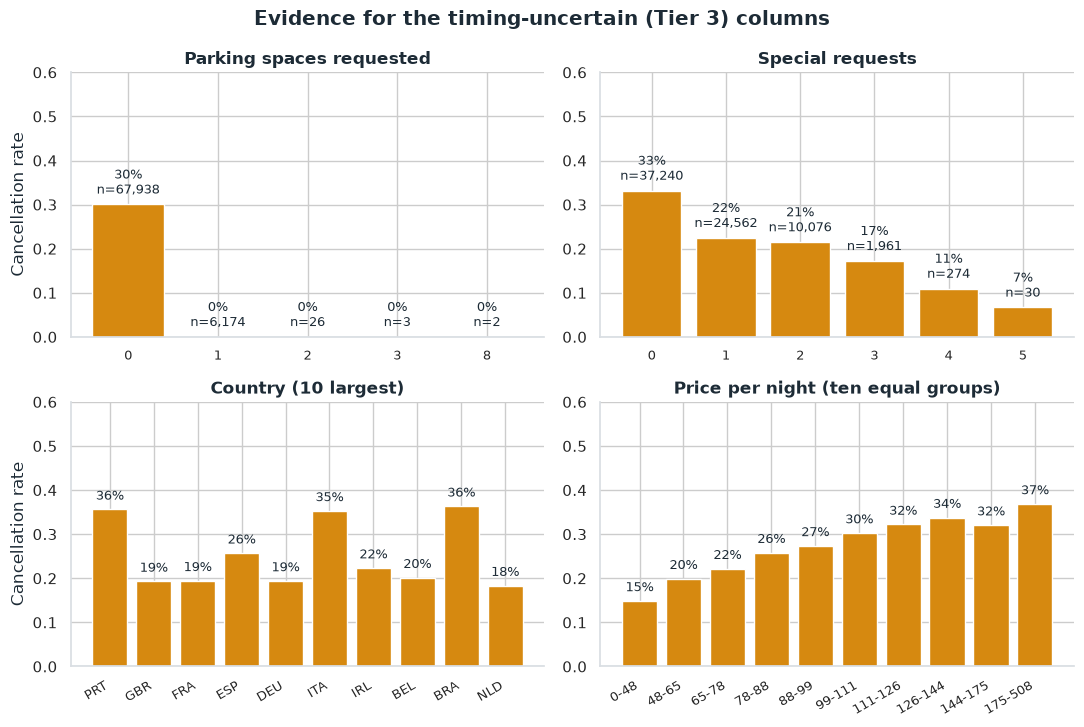

**Parking:** across 6,205 bookings with at least one parking space, the cancellation rate is **0.0%**. No real behaviour is that clean: parking is recorded at check-in, so the value encodes the outcome.

In [34]:
train_rows, val_rows = clean.iloc[splits["train"]], clean.iloc[splits["validation"]]
evidence = tier3_evidence(trval, cfg)
finish_figure(plot_tier3_evidence(evidence), "leakage_tier3_evidence", ctx)
parking = pd.DataFrame(evidence["required_car_parking_spaces"])
with_parking = parking[parking["value"] != "0"]
say(f"**Parking:** across {int(with_parking['rows'].sum()):,} bookings with at least one parking space, "
    f"the cancellation rate is **{(with_parking['cancel_rate'] * with_parking['rows']).sum() / with_parking['rows'].sum():.1%}**. "
    "No real behaviour is that clean: parking is recorded at check-in, so the value encodes the outcome.")

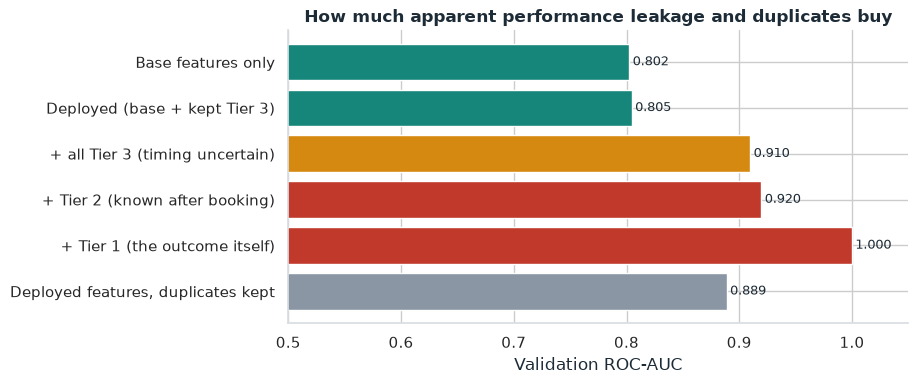

,column,decision,val_roc_auc,gain_over_base
0,adr,keep,0.804653,0.002183
1,required_car_parking_spaces,exclude,0.827651,0.025181
2,total_of_special_requests,exclude,0.831358,0.028889
3,country,exclude,0.871193,0.068724



- With only the deployed features, validation ROC-AUC is **0.805**.
- Adding the timing-uncertain columns lifts it to **0.910**, the
  post-booking columns to **0.920**, and the outcome columns to
  **1.000**.
- Keeping the duplicates and splitting at random would report **0.889**;
  31% of validation rows would then also be in training.
  Section 3.7 takes that number apart.

So a careless pipeline would report a much higher score than the model can deliver on the day of booking.
The honest number is the lower one, and it is the one this project reports.


In [35]:
ablation = leakage_ablation(train_rows, val_rows, cfg)
raw_audit = raw if not FAST else raw.sample(n=min(len(raw), cfg.sample_rows * 2), random_state=cfg.seed)
dedup = dedup_sensitivity(raw_audit, cfg, ablation["ladder"][1]["val_roc_auc"])
finish_figure(plot_leakage_ablation(ablation, dedup), "leakage_ablation", ctx)
display(pd.DataFrame(ablation["tier3_single"]))
ladder = {r["step"]: r["val_roc_auc"] for r in ablation["ladder"]}
say(f"""
- With only the deployed features, validation ROC-AUC is **{ladder['Deployed (base + kept Tier 3)']:.3f}**.
- Adding the timing-uncertain columns lifts it to **{ladder['+ all Tier 3 (timing uncertain)']:.3f}**, the
  post-booking columns to **{ladder['+ Tier 2 (known after booking)']:.3f}**, and the outcome columns to
  **{ladder['+ Tier 1 (the outcome itself)']:.3f}**.
- Keeping the duplicates and splitting at random would report **{dedup['val_roc_auc_duplicates_kept']:.3f}**;
  {dedup['share_of_val_rows_also_in_train_when_kept']:.0%} of validation rows would then also be in training.
  Section 3.7 takes that number apart.

So a careless pipeline would report a much higher score than the model can deliver on the day of booking.
The honest number is the lower one, and it is the one this project reports.
""")

**Decisions for the timing-uncertain columns.** When the evidence does not establish that a value is
known at booking, the rule is **"when in doubt, exclude"**, and the cost of that choice is reported
(the "gain over base" column above is what each excluded column would have added).

In [36]:
display(pd.DataFrame([{"column": c, "decision": d.decision, "reason": " ".join(d.reason.split())}
                      for c, d in cfg.leakage.tier3_decisions.items()]))

,column,decision,reason
0,adr,keep,"The price is agreed when the room is booked. It can change later, but the cancellation rate by price band changes sm..."
1,required_car_parking_spaces,exclude,"Every booking with a parking space has a cancellation rate of exactly zero. Parking is recorded at check-in, so the ..."
2,total_of_special_requests,exclude,"Requests can be added at any time up to check-in, and guests who cancel never reach that point. The timing cannot be..."
3,country,exclude,"Nationality is usually confirmed at check-in. Cancelled bookings keep the value entered at booking, which tends to d..."


### 3.7 What the duplicates really do to the score

It is tempting to say that keeping duplicates inflates the score *because the model memorises copies*.
That is only part of it, and the difference matters for how the final result should be read. The
experiment below keeps the duplicates and scores the same model three ways (training and validation
bookings only; every row that shares its booking-time inputs with a test booking is removed first):

1. **Random split:** copies of a booking can sit on both sides. This is what a careless pipeline does.
2. **Grouped split, every row scored:** all rows with identical booking-time inputs stay on one side,
   so nothing can be memorised, but a booking that appears ten times still counts ten times.
3. **Grouped split, one row per distinct record:** the same predictions, each distinct record counted once.

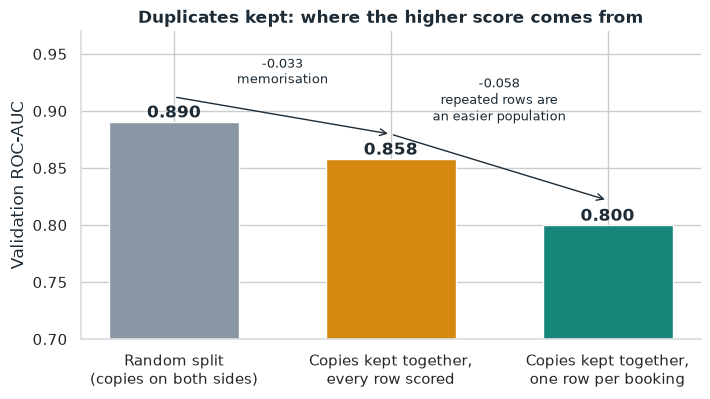


- Random split: **0.890**. With copies kept together: **0.858**.
  Memorisation therefore accounts for **0.033**.
- Counting each distinct record once: **0.800**. The other
  **0.058** is not memorisation at all: the repeated rows are a different, much
  easier population. 40% of them are in the Groups segment (against
  3% of rows without copies) and 39% carry a
  non-refundable deposit (against 0.3%). Non-refundable bookings are
  cancelled 99.6% of the time in this data, so a single column predicts them
  almost perfectly.
- Remove the non-refundable bookings from the scored rows and the same model is back at
  **0.795**.

**What this means.** The repeated rows look like block bookings (many identical rooms booked and released
together), not copying errors, but without a booking ID that cannot be proven. There are therefore two
honest numbers, and they answer different questions. Counting every row, with no memorisation, a
booking-time model reaches about 0.86, because a tenth of the rows are
trivially predictable blocks. On ordinary bookings, where a prediction is actually needed, it reaches about
0.80, whichever way the duplicates are handled. This project
set its criterion on the stricter reading (one row per distinct record, duplicates removed) before
modelling, so that is the number it is judged on.


In [37]:
duplicates = duplicate_decomposition(raw_audit, clean, splits, cfg, repeats=1 if FAST else 3)
finish_figure(plot_duplicate_decomposition(duplicates), "leakage_duplicates", ctx)
rep, single, nonref_all = duplicates["rows_with_copies"], duplicates["rows_without_copies"], duplicates["non_refundable"]
say(f"""
- Random split: **{duplicates['roc_auc_random_split']:.3f}**. With copies kept together: **{duplicates['roc_auc_grouped_split']:.3f}**.
  Memorisation therefore accounts for **{duplicates['memorisation']:.3f}**.
- Counting each distinct record once: **{duplicates['roc_auc_grouped_one_per_record']:.3f}**. The other
  **{duplicates['population']:.3f}** is not memorisation at all: the repeated rows are a different, much
  easier population. {rep['share_groups_segment']:.0%} of them are in the Groups segment (against
  {single['share_groups_segment']:.0%} of rows without copies) and {rep['share_non_refundable']:.0%} carry a
  non-refundable deposit (against {single['share_non_refundable']:.1%}). Non-refundable bookings are
  cancelled {nonref_all['cancel_rate']:.1%} of the time in this data, so a single column predicts them
  almost perfectly.
- Remove the non-refundable bookings from the scored rows and the same model is back at
  **{duplicates['roc_auc_grouped_without_non_refundable']:.3f}**.

**What this means.** The repeated rows look like block bookings (many identical rooms booked and released
together), not copying errors, but without a booking ID that cannot be proven. There are therefore two
honest numbers, and they answer different questions. Counting every row, with no memorisation, a
booking-time model reaches about {duplicates['roc_auc_grouped_split']:.2f}, because a tenth of the rows are
trivially predictable blocks. On ordinary bookings, where a prediction is actually needed, it reaches about
{duplicates['roc_auc_grouped_one_per_record']:.2f}, whichever way the duplicates are handled. This project
set its criterion on the stricter reading (one row per distinct record, duplicates removed) before
modelling, so that is the number it is judged on.
""")

## 4. Algorithm selection

This is **supervised** learning (every booking has a known outcome) and **binary classification**, on
tabular data with a mix of numeric and categorical features, about 60,000 training rows and a moderate
class imbalance. Candidates, from simplest to most flexible:

| Model | Complexity | Interpretability | Compute cost | Why consider it |
|---|---|---|---|---|
| Majority-class baseline | None | Total | None | The floor every model must beat |
| Logistic regression | Low | High: one coefficient per feature | Very low | Strong, honest linear baseline |
| Decision tree | Medium | High for a shallow tree | Low | Readable rules, but unstable |
| Random forest | High | Medium (importances) | Medium; large model files | Robust non-linear baseline |
| HistGradientBoosting | High | Medium | Low | Fast boosting in scikit-learn |
| LightGBM | High | Medium, explained with SHAP | Low | Usually strongest on tabular data |
| Small neural network (MLP) | High | Low | Medium | Covers the neural-network family |

**Not chosen, and why.** *Unsupervised* methods (K-Means, PCA) have no target to learn from; PCA is used
for exploration only (3.5). *Reinforcement learning* does not fit: there is no sequence of actions and
rewards, just one prediction per booking. Among supervised methods, support vector machines and
k-nearest neighbours scale poorly to 60,000 rows with one-hot features and give no calibrated
probability; deep networks have no advantage on a table of 30 columns and would be harder to explain
and to deploy.

**Deployment constraint.** The API runs on a serverless platform with a size limit, so the deployed
model must be small and convertible to ONNX. Tree ensembles convert well; that is one reason the
champion is chosen among tree models. The measured fit time, scoring time and model size of every
candidate are in the table in Section 5.

## 5. Model development and training

Each candidate is a scikit-learn pipeline: preprocessing (Section 3.4) plus the estimator, so encoders
and scalers are fitted inside each training fold. Every candidate gets two scores:

- **Cross-validation on a stratified training subsample** (mean and spread across folds), which shows stability.
- **A fit on all training rows scored on the validation set**, which is the number used to compare
  models. All the assignment's classification metrics are reported: accuracy, precision, recall and F1
  (at the default 0.5 threshold) and ROC-AUC, plus PR-AUC and the Brier score.

The table also records fit time, scoring time and model size (the "computational cost" of Section 4).

In [38]:
# Copied from hotel_cancellation.tuning by scripts/build_notebooks.py
from __future__ import annotations

def stratified_subsample(X: pd.DataFrame, y: pd.Series, n_rows: int, seed: int) -> tuple[pd.DataFrame, pd.Series]:
    """A stratified sample of at most ``n_rows`` rows, used to keep searches affordable."""
    if len(X) <= n_rows:
        return X, y
    keep, _ = train_test_split(np.arange(len(X)), train_size=n_rows, stratify=y, random_state=seed)
    keep = np.sort(keep)
    return X.iloc[keep], y.iloc[keep]


def cv_splitter(cfg: Config) -> StratifiedKFold:
    return StratifiedKFold(n_splits=cfg.tuning.cv_folds, shuffle=True, random_state=cfg.seed)


def search_result(name: str, model: str, scores: list[float], params: list[dict], seconds: float, folds: int) -> dict:
    """Common summary for every strategy: history in evaluation order and the best point."""
    best = int(np.argmax(scores))
    return {
        "strategy": name, "model": model, "configs_tried": len(scores), "fits": len(scores) * folds,
        "seconds": round(seconds, 1), "best_score": float(scores[best]), "best_params": params[best],
        "history": [float(s) for s in scores],
        "best_so_far": [float(v) for v in np.maximum.accumulate(scores)],
    }


def strip_prefix(params: dict) -> dict:
    return {k.split("__", 1)[1]: (v.item() if hasattr(v, "item") else v) for k, v in params.items()}


def run_grid_search(kind: str, grid: dict, X, y, cats, nums, cfg: Config) -> dict:
    start = time.time()
    search = GridSearchCV(make_model(kind, cats, nums, cfg), {f"model__{k}": v for k, v in grid.items()},
                          scoring="roc_auc", cv=cv_splitter(cfg), n_jobs=1, refit=False)
    search.fit(X, y)
    res = search.cv_results_
    return search_result("grid", kind, list(res["mean_test_score"]),
                         [strip_prefix(p) for p in res["params"]], time.time() - start, cfg.tuning.cv_folds)


def run_random_search(kind: str, distributions: dict, n_iter: int, X, y, cats, nums, cfg: Config) -> dict:
    start = time.time()
    search = RandomizedSearchCV(make_model(kind, cats, nums, cfg),
                                {f"model__{k}": v for k, v in distributions.items()}, n_iter=n_iter,
                                scoring="roc_auc", cv=cv_splitter(cfg), n_jobs=1, refit=False,
                                random_state=cfg.seed)
    search.fit(X, y)
    res = search.cv_results_
    return search_result("random", kind, list(res["mean_test_score"]),
                         [strip_prefix(p) for p in res["params"]], time.time() - start, cfg.tuning.cv_folds)


def lgbm_distributions() -> dict:
    """Random-search space for LightGBM; the Optuna space below covers the same ranges."""
    return {
        "num_leaves": randint(15, 256), "learning_rate": loguniform(0.01, 0.2),
        "n_estimators": randint(100, 900), "min_child_samples": randint(5, 100),
        "subsample": uniform(0.5, 0.5), "subsample_freq": [1], "colsample_bytree": uniform(0.5, 0.5),
        "reg_lambda": loguniform(1e-3, 10.0),
    }


def lgbm_trial_params(trial: optuna.Trial) -> dict:
    return {
        "num_leaves": trial.suggest_int("num_leaves", 15, 255),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "n_estimators": trial.suggest_int("n_estimators", 100, 899),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 99),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0), "subsample_freq": 1,
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
    }


def run_optuna_search(n_trials: int, X, y, cats, nums, cfg: Config, start_from: list[dict] | None = None,
                      name: str = "bayesian") -> dict:
    """Bayesian optimisation with a seeded TPE sampler and a single worker (reproducible).

    ``start_from`` lists settings to evaluate first; the sampler then learns from them.
    """
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    start = time.time()
    cv = cv_splitter(cfg)

    def objective(trial: optuna.Trial) -> float:
        model = make_model("lgbm", cats, nums, cfg, **lgbm_trial_params(trial))
        return float(np.mean(cross_val_score(model, X, y, scoring="roc_auc", cv=cv, n_jobs=1)))

    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=cfg.seed))
    for params in start_from or []:
        study.enqueue_trial({k: v for k, v in params.items() if k != "subsample_freq"})
    study.optimize(objective, n_trials=n_trials, n_jobs=1)
    scores = [t.value for t in study.trials]
    params = [{**t.params, "subsample_freq": 1} for t in study.trials]
    return search_result(name, "lgbm", scores, params, time.time() - start, cfg.tuning.cv_folds)


LGBM_UNTUNED = {"num_leaves": 63, "learning_rate": 0.05, "n_estimators": 400, "min_child_samples": 20,
                "subsample": 1.0, "colsample_bytree": 1.0, "reg_lambda": 1e-3}


def refine_lgbm(tuning: dict, X, y, cats, nums, cfg: Config) -> dict:
    """Second stage: Bayesian search on ALL training rows.

    The first stage compares the three strategies cheaply on a subsample, but the best settings
    for 20,000 rows are not the best for the full training set (smaller data favours smaller,
    slower-learning models). This stage starts from the untuned settings and from the winner of
    each first-stage search, so its result can only match or beat them in cross-validation, and
    then lets the sampler explore from there.
    """
    starts = [dict(LGBM_UNTUNED)]
    for key in ("lgbm_grid", "lgbm_random", "lgbm_bayesian"):
        best = {**LGBM_UNTUNED, **{k: v for k, v in tuning[key]["best_params"].items() if k in LGBM_UNTUNED}}
        # keep the starting point inside the search space (a grid may contain values outside it)
        best["n_estimators"] = int(min(max(best["n_estimators"], 100), 899))
        best["num_leaves"] = int(min(max(best["num_leaves"], 15), 255))
        best["learning_rate"] = float(min(max(best["learning_rate"], 0.01), 0.2))
        starts.append(best)
    result = run_optuna_search(max(cfg.tuning.refine_trials, len(starts)), X, y, cats, nums, cfg,
                               start_from=starts, name="bayesian, all training rows")
    result["rows"] = int(len(X))
    result["started_from"] = ["untuned settings", "best of grid search", "best of random search",
                              "best of Bayesian search"]
    result["start_scores"] = result["history"][:len(starts)]
    return result


def rf_distributions() -> dict:
    return {"n_estimators": randint(100, 301), "max_depth": [None, 12, 20, 30],
            "min_samples_leaf": randint(1, 11), "max_features": ["sqrt", 0.3, 0.5]}


def grid_size(grid: dict) -> int:
    return len(list(itertools.product(*grid.values())))


def tune_all(X, y, cats, nums, cfg: Config) -> dict:
    """Grid search on logistic regression, random search on the random forest, and all
    three strategies on LightGBM with the same budget. Runs on a stratified subsample."""
    Xs, ys = stratified_subsample(X, y, cfg.tuning.subsample_rows, cfg.seed)
    budget = cfg.tuning.lgbm_budget
    if grid_size(cfg.tuning.lgbm_grid) != budget:
        raise ValueError("lgbm_grid must contain exactly lgbm_budget combinations for a fair comparison")
    tuning = {
        "subsample_rows": int(len(Xs)),
        "logreg_grid": run_grid_search("logreg", cfg.tuning.logreg_grid, Xs, ys, cats, nums, cfg),
        "rf_random": run_random_search("rf", rf_distributions(), cfg.tuning.rf_random_iterations,
                                       Xs, ys, cats, nums, cfg),
        "lgbm_grid": run_grid_search("lgbm", cfg.tuning.lgbm_grid, Xs, ys, cats, nums, cfg),
        "lgbm_random": run_random_search("lgbm", lgbm_distributions(), budget, Xs, ys, cats, nums, cfg),
        "lgbm_bayesian": run_optuna_search(budget, Xs, ys, cats, nums, cfg),
    }
    tuning["lgbm_refine"] = refine_lgbm(tuning, X, y, cats, nums, cfg)
    return tuning


def best_lgbm_search(tuning: dict) -> dict:
    """The LightGBM settings to refit: the second-stage search on all training rows.

    Its cross-validated scores are not comparable with the first-stage ones (more rows per fold),
    which is why it is not simply the maximum over all searches.
    """
    return tuning["lgbm_refine"]

In [39]:
# Copied from hotel_cancellation.evaluation by scripts/build_notebooks.py
from __future__ import annotations

def classification_metrics(y, proba, threshold: float) -> dict:
    """Threshold metrics at ``threshold`` plus ranking and probability metrics."""
    y = np.asarray(y)
    proba = np.asarray(proba, dtype=float)
    pred = (proba >= threshold).astype(int)
    return {
        "roc_auc": float(roc_auc_score(y, proba)),
        "pr_auc": float(average_precision_score(y, proba)),
        "brier": float(brier_score_loss(y, proba)),
        "accuracy": float(accuracy_score(y, pred)),
        "precision": float(precision_score(y, pred, zero_division=0)),
        "recall": float(recall_score(y, pred, zero_division=0)),
        "f1": float(f1_score(y, pred, zero_division=0)),
        "threshold": float(threshold),
    }


def bootstrap_ci(y, proba, threshold: float, n_samples: int, seed: int) -> dict:
    """95% percentile intervals from resampling rows with replacement."""
    y = np.asarray(y)
    proba = np.asarray(proba, dtype=float)
    rng = np.random.default_rng(seed)
    draws: dict[str, list[float]] = {}
    for _ in range(n_samples):
        idx = rng.integers(0, len(y), len(y))
        if y[idx].min() == y[idx].max():
            continue
        for k, v in classification_metrics(y[idx], proba[idx], threshold).items():
            if k != "threshold":
                draws.setdefault(k, []).append(v)
    return {k: {"low": float(np.percentile(v, 2.5)), "high": float(np.percentile(v, 97.5))}
            for k, v in draws.items()}


def evaluate_candidates(X_train, y_train, X_val, y_val, cats, nums, cfg: Config) -> pd.DataFrame:
    """Cross-validation on a training subsample, then a full-train fit scored on validation."""
    import pickle

    Xs, ys = stratified_subsample(X_train, y_train, cfg.tuning.subsample_rows, cfg.seed)
    rows = []
    for kind in MODEL_NOTES:
        model = make_model(kind, cats, nums, cfg)
        cv = cross_validate(model, Xs, ys, cv=cv_splitter(cfg), scoring=["roc_auc", "average_precision"])
        start = time.time()
        model.fit(X_train, y_train)
        fit_seconds = time.time() - start
        start = time.time()
        proba = model.predict_proba(X_val)[:, 1]
        per_1k = (time.time() - start) / len(X_val) * 1000
        val = classification_metrics(y_val, proba, 0.5)
        rows.append({
            "model": kind, "cv_roc_auc_mean": float(np.mean(cv["test_roc_auc"])),
            "cv_roc_auc_std": float(np.std(cv["test_roc_auc"])),
            "cv_pr_auc_mean": float(np.mean(cv["test_average_precision"])),
            "val_roc_auc": val["roc_auc"], "val_pr_auc": val["pr_auc"], "val_accuracy_at_0_5": val["accuracy"],
            "val_precision_at_0_5": val["precision"], "val_recall_at_0_5": val["recall"],
            "val_f1_at_0_5": val["f1"], "val_brier": val["brier"], "fit_seconds": round(fit_seconds, 2),
            "predict_ms_per_1k_rows": round(per_1k * 1000, 2),
            "size_kb": round(len(pickle.dumps(model)) / 1024, 1), "notes": MODEL_NOTES[kind],
        })
    return pd.DataFrame(rows).sort_values("val_roc_auc", ascending=False).reset_index(drop=True)


def fit_calibration(val_proba, y_val, cfg: Config) -> dict:
    """Decide whether isotonic calibration helps, using out-of-fold predictions on validation.

    The mapping is fitted on all validation rows only if the out-of-fold Brier score
    improves by at least ``calibration_min_brier_gain``. Stored as breakpoints so the
    API can apply it with a plain interpolation.
    """
    p = np.asarray(val_proba, dtype=float)
    y = np.asarray(y_val)
    folds = StratifiedKFold(cfg.evaluation.calibration_folds, shuffle=True, random_state=cfg.seed)
    oof = np.zeros_like(p)
    for fit_idx, eval_idx in folds.split(p.reshape(-1, 1), y):
        iso = IsotonicRegression(out_of_bounds="clip", y_min=0.0, y_max=1.0).fit(p[fit_idx], y[fit_idx])
        oof[eval_idx] = iso.predict(p[eval_idx])
    raw_brier, cal_brier = brier_score_loss(y, p), brier_score_loss(y, oof)
    use = (raw_brier - cal_brier) >= cfg.evaluation.calibration_min_brier_gain
    result = {"method": "isotonic", "used": bool(use), "brier_raw": float(raw_brier),
              "brier_calibrated_out_of_fold": float(cal_brier), "x": [], "y": []}
    if use:
        iso = IsotonicRegression(out_of_bounds="clip", y_min=0.0, y_max=1.0).fit(p, y)
        result["x"] = [float(v) for v in iso.X_thresholds_]
        result["y"] = [float(v) for v in iso.y_thresholds_]
    return result


def apply_calibration(proba, calibration: dict) -> np.ndarray:
    proba = np.asarray(proba, dtype=float)
    if not calibration["used"]:
        return proba
    return np.interp(proba, calibration["x"], calibration["y"])


def cost_curve(y, proba, fn_cost: float, fp_cost: float, thresholds=None) -> pd.DataFrame:
    """Average cost per booking at each threshold."""
    y = np.asarray(y)
    proba = np.asarray(proba, dtype=float)
    thresholds = np.round(np.arange(0.05, 0.951, 0.01), 2) if thresholds is None else thresholds
    rows = []
    for t in thresholds:
        pred = proba >= t
        fp = int(np.sum(pred & (y == 0)))
        fn = int(np.sum(~pred & (y == 1)))
        rows.append({"threshold": float(t), "false_positives": fp, "false_negatives": fn,
                     "cost_per_booking": (fp * fp_cost + fn * fn_cost) / len(y)})
    return pd.DataFrame(rows)


def choose_threshold(curve: pd.DataFrame) -> float:
    return float(curve.loc[curve["cost_per_booking"].idxmin(), "threshold"])


def confusion(y, proba, threshold: float) -> list[list[int]]:
    return confusion_matrix(np.asarray(y), (np.asarray(proba) >= threshold).astype(int)).tolist()


def learning_curve_data(model, X, y, cfg: Config) -> dict:
    sizes, train_scores, val_scores = learning_curve(
        clone(model), X, y, train_sizes=cfg.diagnostics.learning_curve_sizes, cv=cv_splitter(cfg),
        scoring="roc_auc", n_jobs=1, shuffle=True, random_state=cfg.seed)
    return {"train_sizes": sizes.tolist(), "train_mean": train_scores.mean(1).tolist(),
            "train_std": train_scores.std(1).tolist(), "cv_mean": val_scores.mean(1).tolist(),
            "cv_std": val_scores.std(1).tolist()}


def validation_curve_data(params: dict, X, y, cats, nums, cfg: Config) -> dict:
    """Effect of ``num_leaves`` (model capacity) with the other tuned settings fixed.

    Run on all training rows, like the search that chose the settings: the best capacity
    depends on how much data there is, so a subsample would answer a different question.
    """
    fixed = {k: v for k, v in params.items() if k != "num_leaves"}
    values = cfg.diagnostics.validation_curve_num_leaves
    train_scores, val_scores = validation_curve(
        make_model("lgbm", cats, nums, cfg, **fixed), X, y, param_name="model__num_leaves",
        param_range=values, cv=cv_splitter(cfg), scoring="roc_auc", n_jobs=1)
    return {"param": "num_leaves", "values": list(values), "chosen": params.get("num_leaves"),
            "train_mean": train_scores.mean(1).tolist(), "cv_mean": val_scores.mean(1).tolist(),
            "cv_std": val_scores.std(1).tolist()}


def lead_time_band(days: pd.Series) -> pd.Series:
    return pd.cut(days, [-1, 7, 30, 90, 180, 365, 10_000],
                  labels=["0-7", "8-30", "31-90", "91-180", "181-365", "365+"]).astype(str)


def segment_report(raw: pd.DataFrame, y, proba, threshold: float, by: str) -> pd.DataFrame:
    """Where the model is wrong: error rate and AUC per segment on validation data."""
    frame = pd.DataFrame({"segment": lead_time_band(raw["lead_time"]) if by == "lead_time_band" else raw[by],
                          "y": np.asarray(y), "p": np.asarray(proba)}, index=raw.index)
    rows = []
    for seg, part in frame.groupby("segment", observed=True):
        auc = roc_auc_score(part["y"], part["p"]) if part["y"].nunique() == 2 else float("nan")
        rows.append({"by": by, "segment": str(seg), "rows": int(len(part)),
                     "actual_cancel_rate": float(part["y"].mean()),
                     "predicted_cancel_rate": float((part["p"] >= threshold).mean()),
                     "error_rate": float(((part["p"] >= threshold).astype(int) != part["y"]).mean()),
                     "roc_auc": float(auc)})
    return pd.DataFrame(rows).sort_values("rows", ascending=False)


def best_f1_threshold(y, proba) -> float:
    """The threshold with the highest F1 on the given (validation) data."""
    y = np.asarray(y)
    proba = np.asarray(proba, dtype=float)
    grid = np.round(np.arange(0.05, 0.951, 0.01), 2)
    scores = [f1_score(y, (proba >= t).astype(int), zero_division=0) for t in grid]
    return float(grid[int(np.argmax(scores))])


def operating_points(y_val, val_proba, cost_threshold: float, cfg: Config) -> list[dict]:
    """Three thresholds a hotel might act on, every one of them chosen on validation data.

    The cost-based one is the deployed decision rule. The other two are reported so the
    threshold metrics are not judged at a single, deliberately cautious operating point.
    """
    c = cfg.costs
    return [
        {"name": "cost-based (deployed)", "threshold": float(cost_threshold),
         "chosen_by": f"lowest expected cost: missed cancellation = {c.false_negative:g}, "
                      f"false alarm = {c.false_positive:g}"},
        {"name": "default 0.5", "threshold": 0.5, "chosen_by": "convention"},
        {"name": "best F1", "threshold": best_f1_threshold(y_val, val_proba), "chosen_by": "highest F1 on validation"},
    ]


def metrics_at_points(y, proba, points: list[dict]) -> pd.DataFrame:
    """Accuracy, precision, recall and F1 at each operating point, plus the share of bookings flagged."""
    proba = np.asarray(proba, dtype=float)
    rows = []
    for point in points:
        m = classification_metrics(y, proba, point["threshold"])
        rows.append({"operating_point": point["name"], "threshold": point["threshold"],
                     "flagged_share": float(np.mean(proba >= point["threshold"])),
                     **{k: m[k] for k in ("accuracy", "precision", "recall", "f1")}})
    return pd.DataFrame(rows)


def cost_sensitivity(y_val, val_proba, y_eval, eval_proba, cfg: Config) -> pd.DataFrame:
    """How the decision changes with the cost of a false alarm (a missed cancellation costs 1).

    For each cost the threshold is chosen on validation and then scored on the evaluation set.
    ``cost_without_model`` is the cheaper of the two rules that need no model: act on nobody
    or act on everybody. ``saving`` is the share of that cost the model removes.
    """
    y_eval = np.asarray(y_eval)
    eval_proba = np.asarray(eval_proba, dtype=float)
    fn = cfg.costs.false_negative
    rate = float(np.mean(y_eval))
    rows = []
    for fp in cfg.evaluation.cost_sensitivity_false_positive:
        threshold = choose_threshold(cost_curve(y_val, val_proba, fn, fp))
        cost = float(cost_curve(y_eval, eval_proba, fn, fp, thresholds=[threshold])["cost_per_booking"].iloc[0])
        without = min(rate * fn, (1 - rate) * fp)
        m = classification_metrics(y_eval, eval_proba, threshold)
        rows.append({"false_alarm_cost": float(fp), "threshold": threshold,
                     "flagged_share": float(np.mean(eval_proba >= threshold)), "precision": m["precision"],
                     "recall": m["recall"], "f1": m["f1"], "cost_per_booking": cost,
                     "cost_without_model": float(without), "saving": float(1 - cost / without)})
    return pd.DataFrame(rows)


def gains_table(y, proba, groups: int = 10) -> pd.DataFrame:
    """Bookings sorted from highest to lowest predicted risk and cut into equal groups.

    ``cumulative_share_of_cancellations`` answers: if the hotel contacted the riskiest
    10%, 20%, ... of bookings, what share of all cancellations would it reach?
    """
    y = np.asarray(y)
    order = np.argsort(-np.asarray(proba, dtype=float), kind="stable")
    parts = np.array_split(y[order], groups)
    base, total = float(y.mean()), float(y.sum())
    rows, reached = [], 0.0
    for i, part in enumerate(parts, start=1):
        reached += float(part.sum())
        rows.append({"risk_group": i, "bookings": int(len(part)), "cancel_rate": float(part.mean()),
                     "lift": float(part.mean() / base), "cumulative_share_of_bookings": i / groups,
                     "cumulative_share_of_cancellations": reached / total})
    return pd.DataFrame(rows)


def capacity_report(raw: pd.DataFrame, y, proba, base_rate: float) -> dict:
    """Does the model forecast HOW MANY bookings will cancel, per hotel and arrival week?

    Overbooking is decided for a hotel and a date range, not for one booking: the useful
    quantity is the expected number of cancellations, which is the sum of the predicted
    probabilities. It is compared with the forecast that needs no model (bookings times
    the overall cancellation rate seen in training). WAPE is the summed absolute error
    divided by the summed actual count; lower is better.
    """
    arrival = pd.to_datetime(raw["arrival_date_year"].astype(str) + "-" + raw["arrival_date_month"] + "-"
                             + raw["arrival_date_day_of_month"].astype(str), format="%Y-%B-%d")
    monday = arrival - pd.to_timedelta(arrival.dt.weekday, unit="D")
    frame = pd.DataFrame({"hotel": raw["hotel"].to_numpy(), "week": monday.dt.strftime("%Y-%m-%d").to_numpy(),
                          "actual": np.asarray(y, dtype=float), "predicted": np.asarray(proba, dtype=float)})
    weekly = frame.groupby(["hotel", "week"], as_index=False).agg(
        bookings=("actual", "size"), actual=("actual", "sum"), predicted=("predicted", "sum"))
    weekly["base_rate_forecast"] = weekly["bookings"] * base_rate
    total = float(weekly["actual"].sum())

    def wape(column: str) -> float:
        return float((weekly[column] - weekly["actual"]).abs().sum() / total)

    return {"weeks": int(len(weekly)), "bookings_per_week_median": float(weekly["bookings"].median()),
            "total_actual": total, "total_predicted": float(weekly["predicted"].sum()),
            "bias": float(weekly["predicted"].sum() / total - 1),
            "wape_model": wape("predicted"), "wape_base_rate": wape("base_rate_forecast"),
            "correlation": float(np.corrcoef(weekly["predicted"], weekly["actual"])[0, 1]),
            "by_week": weekly}

The shared workflow steps used from here on (frames, champion selection, diagnostics, the test pass
and the results report):

In [40]:
# Copied from hotel_cancellation.workflow by scripts/build_notebooks.py
from __future__ import annotations

TREE_KINDS = {"lgbm", "rf", "hgb", "tree"}


def build_model_frames(clean: pd.DataFrame, splits: dict, cfg: Config) -> dict:
    """Deployed feature set for each split, plus the raw rows for error analysis."""
    sources = deployed_sources(cfg)
    X = build_feature_frame(clean, sources)
    y = clean[cfg.target]
    cats, nums = split_feature_types(list(X.columns))
    frames = {"sources": sources, "cats": cats, "nums": nums}
    for name, pos in splits.items():
        frames[f"X_{name}"], frames[f"y_{name}"], frames[f"raw_{name}"] = X.iloc[pos], y.iloc[pos], clean.iloc[pos]
    return frames


def fit_tuned_models(tuning: dict, frames: dict, cfg: Config) -> dict:
    """Refit the best setting of each tuned family on all training rows; score on validation."""
    picks = {"logreg": tuning["logreg_grid"], "rf": tuning["rf_random"], "lgbm": best_lgbm_search(tuning)}
    out = {}
    for kind, search in picks.items():
        model = make_model(kind, frames["cats"], frames["nums"], cfg, **search["best_params"])
        model.fit(frames["X_train"], frames["y_train"])
        proba = model.predict_proba(frames["X_validation"])[:, 1]
        out[kind] = {"model": model, "params": search["best_params"], "strategy": search["strategy"],
                     "cv_roc_auc": search["best_score"],
                     "val_roc_auc": classification_metrics(frames["y_validation"], proba, 0.5)["roc_auc"],
                     "size_kb": round(len(pickle.dumps(model)) / 1024, 1)}
    return out


def pick_champion(fitted: dict, cfg: Config) -> dict:
    """Best validation ROC-AUC among tree models (the ones the service can run), with a tie rule.

    Models within ``selection.tie_tolerance`` of the best score are treated as tied, because a
    difference that small is below run-to-run noise; among tied models the smallest is chosen,
    since it deploys and scores faster. Decided on validation data only.
    """
    trees = {k: v for k, v in fitted.items() if k in TREE_KINDS}
    top = max(v["val_roc_auc"] for v in trees.values())
    tied = {k: v for k, v in trees.items() if top - v["val_roc_auc"] <= cfg.selection.tie_tolerance}
    name = min(tied, key=lambda k: tied[k]["size_kb"])
    return {"name": name, "params": fitted[name]["params"], "strategy": fitted[name]["strategy"],
            "val_roc_auc": fitted[name]["val_roc_auc"], "best_val_roc_auc": top, "tied_models": sorted(tied),
            "rule": f"best validation ROC-AUC; models within {cfg.selection.tie_tolerance} of it are tied and "
                    "the smallest tied model wins",
            "comparison": [{"model": k, "strategy": v["strategy"], "cv_roc_auc": v["cv_roc_auc"],
                            "val_roc_auc": v["val_roc_auc"], "size_kb": v["size_kb"], "params": v["params"]}
                           for k, v in fitted.items()]}


def threshold_for(model, frames: dict, calibration: dict, cfg: Config) -> tuple[float, pd.DataFrame]:
    """Cost-minimising threshold on validation probabilities (after calibration)."""
    proba = apply_calibration(model.predict_proba(frames["X_validation"])[:, 1], calibration)
    curve = cost_curve(frames["y_validation"], proba, cfg.costs.false_negative, cfg.costs.false_positive)
    return choose_threshold(curve), curve


def run_diagnostics(model, champion: dict, frames: dict, cfg: Config) -> dict:
    """Calibration, threshold, validation metrics, learning and validation curves, error analysis."""
    y_val = frames["y_validation"]
    raw = model.predict_proba(frames["X_validation"])[:, 1]
    calibration = fit_calibration(raw, y_val, cfg)
    proba = apply_calibration(raw, calibration)
    threshold, curve = threshold_for(model, frames, calibration, cfg)
    segments = pd.concat([segment_report(frames["raw_validation"], y_val, proba, threshold, by)
                          for by in ["hotel", "market_segment", "lead_time_band"]], ignore_index=True)
    train_auc = classification_metrics(frames["y_train"], model.predict_proba(frames["X_train"])[:, 1],
                                       0.5)["roc_auc"]
    points = operating_points(y_val, proba, threshold, cfg)
    return {
        "calibration": calibration, "threshold": threshold, "cost_curve": curve,
        "val_metrics": classification_metrics(y_val, proba, threshold),
        "val_confusion": confusion(y_val, proba, threshold),
        "operating_points": points, "val_operating_metrics": metrics_at_points(y_val, proba, points),
        "val_cost_sensitivity": cost_sensitivity(y_val, proba, y_val, proba, cfg),
        "val_gains": gains_table(y_val, proba),
        "val_capacity": capacity_report(frames["raw_validation"], y_val, proba, float(frames["y_train"].mean())),
        "train_roc_auc": train_auc, "val_proba_raw": raw, "val_proba": proba,
        "learning_curve": learning_curve_data(model, frames["X_train"], frames["y_train"], cfg),
        "validation_curve": (validation_curve_data(champion["params"], frames["X_train"], frames["y_train"],
                                                   frames["cats"], frames["nums"], cfg)
                             if champion["name"] == "lgbm" else None),
        "segments": segments,
    }


def final_test_pass(test_models: dict, champion_calibration: dict, frames: dict, cfg: Config) -> dict:
    """The only function that reads the test set. Scores the pre-declared models once.

    Each model's threshold is chosen on validation before any test row is
    scored; only the champion is calibrated. Nothing is refitted here.
    """
    if list(test_models) != list(cfg.test_pass_models):
        raise ValueError(f"test pass must score exactly {cfg.test_pass_models}, got {list(test_models)}")
    results = {}
    for name, model in test_models.items():
        calibration = champion_calibration if name == "champion" else {"used": False}
        threshold, _ = threshold_for(model, frames, calibration, cfg)
        proba = apply_calibration(model.predict_proba(frames["X_test"])[:, 1], calibration)
        curve = cost_curve(frames["y_test"], proba, cfg.costs.false_negative, cfg.costs.false_positive,
                           thresholds=[threshold])
        results[name] = {"metrics": classification_metrics(frames["y_test"], proba, threshold),
                         "metrics_at_0_5": classification_metrics(frames["y_test"], proba, 0.5),
                         "cost_per_booking": float(curve["cost_per_booking"].iloc[0]),
                         "confusion": confusion(frames["y_test"], proba, threshold), "proba": proba}
    champ = results["champion"]
    champ["ci"] = bootstrap_ci(frames["y_test"], champ["proba"], champ["metrics"]["threshold"],
                               cfg.evaluation.bootstrap_samples, cfg.seed)
    # The same analyses as on validation (Section 6), with every threshold taken from validation.
    val_proba = apply_calibration(test_models["champion"].predict_proba(frames["X_validation"])[:, 1],
                                  champion_calibration)
    points = operating_points(frames["y_validation"], val_proba, champ["metrics"]["threshold"], cfg)
    champ["operating_metrics"] = metrics_at_points(frames["y_test"], champ["proba"], points)
    champ["cost_sensitivity"] = cost_sensitivity(frames["y_validation"], val_proba, frames["y_test"],
                                                 champ["proba"], cfg)
    champ["gains"] = gains_table(frames["y_test"], champ["proba"])
    champ["capacity"] = capacity_report(frames["raw_test"], frames["y_test"], champ["proba"],
                                        float(frames["y_train"].mean()))
    met = champ["metrics"]["roc_auc"] >= cfg.success.roc_auc
    beats = all(champ["metrics"]["roc_auc"] > results[m]["metrics"]["roc_auc"] for m in results if m != "champion")
    return {"models": results, "success": {
        "criterion": f"test ROC-AUC >= {cfg.success.roc_auc} and above every baseline",
        "roc_auc_target_met": bool(met), "beats_baselines": bool(beats),
        "ci_lower_bound_above_target": bool(champ["ci"]["roc_auc"]["low"] >= cfg.success.roc_auc)}}


def strip_arrays(obj):
    """Drop fitted models and probability arrays, and turn DataFrames into records, before writing JSON."""
    if isinstance(obj, dict):
        return {k: strip_arrays(v) for k, v in obj.items()
                if k not in {"proba", "val_proba", "val_proba_raw", "eval_proba"} and not hasattr(v, "fit")}
    if isinstance(obj, pd.DataFrame):
        return obj.to_dict("records")
    if isinstance(obj, list):
        return [strip_arrays(v) for v in obj]
    return obj


def build_metrics_report(parts: dict, cfg: Config) -> dict:
    """The single results file. Docs and slides read their numbers from here."""
    return strip_arrays({
        "project": cfg.project, "fast_mode": cfg.is_fast, "seed": cfg.seed,
        "data": {"audit": parts["audit"], "cleaning": parts["cleaning_log"],
                 "rows_after_cleaning": parts["rows_after_cleaning"],
                 "duplicate_rows_cancel_rate": parts["duplicate_rows_cancel_rate"],
                 "split": parts["split_summary"]},
        "features": {"sources": parts["frames"]["sources"], "categorical": parts["frames"]["cats"],
                     "numeric": parts["frames"]["nums"]},
        "leakage": {"ablation": parts["leakage"], "dedup_sensitivity": parts["dedup"],
                    "decisions": {c: {"decision": d.decision, "reason": d.reason}
                                  for c, d in cfg.leakage.tier3_decisions.items()}},
        "candidates": parts["candidates"],
        "experiments": parts.get("experiments"),
        "tuning": {k: (v if not isinstance(v, dict) else {kk: vv for kk, vv in v.items() if kk != "history"})
                   for k, v in parts["tuning"].items()},
        "champion": parts["champion"],
        "diagnostics": {k: v for k, v in parts["diagnostics"].items() if k not in {"cost_curve", "segments"}},
        "quality_audit": parts.get("quality_audit"),
        "duplicates": parts.get("duplicates"),
        "first_test_evaluation": dataclasses.asdict(cfg.first_test_evaluation),
        "temporal_check": parts["temporal"],
        "explain": {"permutation_top10": parts["permutation"].head(10),
                    "shap_top10": parts["shap_importance"].head(10)},
        "test": parts["test"],
        "deployment": parts.get("deployment"),
    })

,model,cv_roc_auc_mean,cv_roc_auc_std,cv_pr_auc_mean,val_roc_auc,val_pr_auc,val_accuracy_at_0_5,val_precision_at_0_5,val_recall_at_0_5,val_f1_at_0_5,val_brier,fit_seconds,predict_ms_per_1k_rows,size_kb
0,lgbm,0.7726,0.0067,0.5846,0.8047,0.6340,0.7755,0.6668,0.3680,0.4742,0.1493,3.40,27.03,2672.0
1,rf,0.7807,0.0032,0.5960,0.8033,0.6313,0.7749,0.6650,0.3666,0.4726,0.1500,13.41,25.07,123461.8
2,hgb,0.7791,0.0050,0.5922,0.7980,0.6241,0.7723,0.6789,0.3277,0.4420,0.1521,6.57,16.22,370.9
3,mlp,0.7746,0.0040,0.5864,0.7927,0.6059,0.7669,0.6195,0.3966,0.4836,0.1540,29.89,6.34,296.5
4,logreg,0.7728,0.0025,0.5849,0.7777,0.5950,0.7637,0.6382,0.3263,0.4318,0.1575,3.88,4.70,11.3
5,tree,0.7274,0.0026,0.5251,0.7499,0.5626,0.7498,0.5596,0.4260,0.4838,0.1718,1.75,4.16,332.4
6,dummy,0.5000,0.0000,0.2753,0.5000,0.2752,0.7248,0.0000,0.0000,0.0000,0.1995,0.63,5.83,9.9


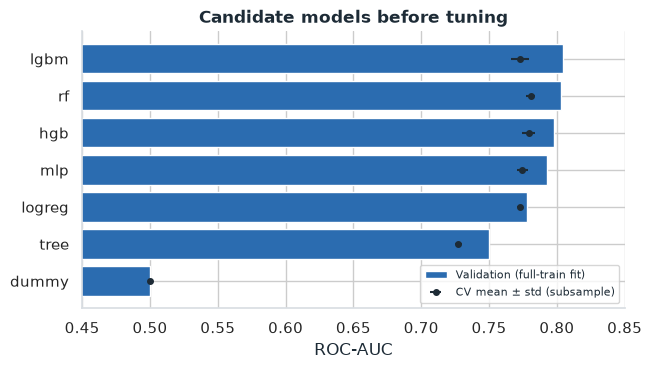

Before tuning, **lgbm** leads on validation ROC-AUC (0.805). The baseline scores 0.500 by construction. The boosting models and the random forest are close, so tuning (Section 6) decides between them. Accuracy alone is misleading here: predicting "never cancelled" already gives 0.725, and the best model reaches 0.775, which is why ROC-AUC is the main criterion. The most flexible models are within 0.012 of each other: four different model families arriving at nearly the same score is a first sign that the limit is in the features, not in the algorithm.

In [41]:
frames = build_model_frames(clean, splits, cfg)
candidates = evaluate_candidates(frames["X_train"], frames["y_train"], frames["X_validation"],
                                 frames["y_validation"], frames["cats"], frames["nums"], cfg)
display(candidates.drop(columns="notes").round(4))
finish_figure(plot_candidates(candidates), "models_candidates", ctx)
best = candidates.iloc[0]
by_model = candidates.set_index("model")
say(f"Before tuning, **{best['model']}** leads on validation ROC-AUC ({best['val_roc_auc']:.3f}). The baseline "
    f"scores {by_model.loc['dummy', 'val_roc_auc']:.3f} by construction. The boosting models and the random "
    f"forest are close, so tuning (Section 6) decides between them. Accuracy alone is misleading here: "
    f"predicting \"never cancelled\" already gives {by_model.loc['dummy', 'val_accuracy_at_0_5']:.3f}, and the "
    f"best model reaches {best['val_accuracy_at_0_5']:.3f}, which is why ROC-AUC is the main criterion. "
    f"The most flexible models are within {candidates['val_roc_auc'].iloc[0] - candidates['val_roc_auc'].iloc[3]:.3f} "
    "of each other: four different model families arriving at nearly the same score is a first sign that the "
    "limit is in the features, not in the algorithm.")

**Three design experiments** with the same LightGBM settings, so only the choice under test changes:

1. **Encoding the categories:** ordinal codes (what the deployed model uses), one-hot, and target
   encoding (fitted inside each fold to avoid leaking the target).
2. **Handling class imbalance:** no correction, class weights, and SMOTENC oversampling (which
   handles categorical columns, and is applied to training folds only). Moving the decision threshold,
   the third option, is done for every model in Section 6.
3. **More feature engineering:** eight further booking-time features (the company ID, the weekday,
   month and day of year of the booking date, the arrival day of year and day of month, and the total
   value of the stay), all legitimate at booking time.

In [42]:
# Copied from hotel_cancellation.experiments by scripts/build_notebooks.py
from __future__ import annotations

def seeded_target_encoder(seed: int) -> TargetEncoder:
    """Deterministic target encoder; scikit-learn 1.9 moved the seed into the ``cv`` argument."""
    import sklearn

    major, minor = (int(p) for p in sklearn.__version__.split(".")[:2])
    if (major, minor) >= (1, 9):
        return TargetEncoder(target_type="binary", cv=StratifiedKFold(5, shuffle=True, random_state=seed))
    return TargetEncoder(target_type="binary", random_state=seed)


def encoding_pipelines(cats: list[str], nums: list[str], cfg: Config) -> dict[str, Pipeline]:
    minf = cfg.features.min_category_frequency

    def wrap(encoder) -> Pipeline:
        columns = ColumnTransformer([("cat", encoder, cats), ("num", "passthrough", nums)],
                                    verbose_feature_names_out=False)
        return Pipeline([("prep", columns), ("float32", FunctionTransformer(to_float32)),
                         ("model", base_estimator("lgbm", cfg))])

    return {
        "ordinal (deployed)": wrap(OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1,
                                                  min_frequency=minf)),
        "one-hot": wrap(OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=minf,
                                      sparse_output=False)),
        # TargetEncoder cross-fits internally, and here it is refitted inside every CV fold.
        "target encoding": wrap(seeded_target_encoder(cfg.seed)),
    }


def compare_encodings(X, y, cats, nums, cfg: Config) -> pd.DataFrame:
    Xs, ys = stratified_subsample(X, y, cfg.tuning.subsample_rows, cfg.seed)
    rows = []
    for name, pipe in encoding_pipelines(cats, nums, cfg).items():
        cv = cross_validate(pipe, Xs, ys, cv=cv_splitter(cfg), scoring=["roc_auc", "average_precision"],
                            return_estimator=True)
        width = cv["estimator"][0].named_steps["prep"].transform(Xs.head(5)).shape[1]
        rows.append({"encoding": name, "cv_roc_auc_mean": float(np.mean(cv["test_roc_auc"])),
                     "cv_roc_auc_std": float(np.std(cv["test_roc_auc"])),
                     "cv_pr_auc_mean": float(np.mean(cv["test_average_precision"])), "model_columns": int(width),
                     "fit_seconds_per_fold": float(np.mean(cv["fit_time"]))})
    return pd.DataFrame(rows)


def compare_feature_sets(train_rows: pd.DataFrame, cfg: Config) -> pd.DataFrame:
    """Would more feature engineering help? Deployed features against deployed plus the candidate group.

    Cross-validated on all training rows with the same folds and the same LightGBM settings,
    so the per-fold differences are paired.
    """
    y = train_rows[cfg.target]
    variants = {"deployed features": deployed_sources(cfg),
                "deployed + candidate features": deployed_sources(cfg) + list(cfg.features.candidate_sources)}
    rows, folds = [], {}
    for name, sources in variants.items():
        X = build_feature_frame(train_rows, sources)
        cats, nums = split_feature_types(list(X.columns))
        pipe = Pipeline(make_tree_preprocessor(cats, nums, cfg.features.min_category_frequency)
                        + [("model", base_estimator("lgbm", cfg))])
        folds[name] = cross_validate(pipe, X, y, cv=cv_splitter(cfg), scoring="roc_auc")["test_score"]
        rows.append({"features": name, "columns": int(X.shape[1]), "cv_roc_auc_mean": float(np.mean(folds[name])),
                     "cv_roc_auc_std": float(np.std(folds[name]))})
    gain = folds["deployed + candidate features"] - folds["deployed features"]
    rows[1].update({"gain_mean": float(np.mean(gain)), "gain_min": float(np.min(gain)), "gain_max": float(np.max(gain))})
    rows[0].update({"gain_mean": 0.0, "gain_min": 0.0, "gain_max": 0.0})
    return pd.DataFrame(rows)


def compare_imbalance(X_train, y_train, X_val, y_val, cats, nums, cfg: Config) -> pd.DataFrame:
    """No correction, class weights, and SMOTENC oversampling (training rows only)."""
    Xs, ys = stratified_subsample(X_train, y_train, cfg.tuning.subsample_rows, cfg.seed)
    prep = make_tree_preprocessor(cats, nums, cfg.features.min_category_frequency)
    ratio = float((ys == 0).sum() / (ys == 1).sum())
    variants = {
        "none": Pipeline(prep + [("model", base_estimator("lgbm", cfg))]),
        "class weights": Pipeline(prep + [("model", base_estimator("lgbm", cfg, scale_pos_weight=ratio))]),
        "SMOTENC oversampling": ImbPipeline(prep + [
            ("smote", SMOTENC(categorical_features=list(range(len(cats))), random_state=cfg.seed)),
            ("model", base_estimator("lgbm", cfg))]),
    }
    rows = []
    for name, pipe in variants.items():
        pipe.fit(Xs, ys)
        p = pipe.predict_proba(X_val)[:, 1]
        rows.append({"method": name, "val_roc_auc": float(roc_auc_score(y_val, p)),
                     "val_pr_auc": float(average_precision_score(y_val, p)),
                     "val_brier": float(brier_score_loss(y_val, p)),
                     "mean_predicted_probability": float(np.mean(p)), "actual_rate": float(np.mean(y_val))})
    return pd.DataFrame(rows)

,encoding,cv_roc_auc_mean,cv_roc_auc_std,cv_pr_auc_mean,model_columns,fit_seconds_per_fold
0,ordinal (deployed),0.7726,0.0067,0.5846,30,2.0464
1,one-hot,0.7752,0.0043,0.5910,89,1.8293
2,target encoding,0.7776,0.0040,0.5937,30,1.2443


,method,val_roc_auc,val_pr_auc,val_brier,mean_predicted_probability,actual_rate
0,none,0.7879,0.6113,0.1552,0.2662,0.2752
1,class weights,0.7878,0.6098,0.1734,0.3822,0.2752
2,SMOTENC oversampling,0.7851,0.6040,0.1574,0.2870,0.2752


,features,columns,cv_roc_auc_mean,cv_roc_auc_std,gain_mean,gain_min,gain_max
0,deployed features,30,0.7986,0.0015,0.0000,0.0000,0.0000
1,deployed + candidate features,38,0.8003,0.0030,0.0017,-0.0004,0.0033


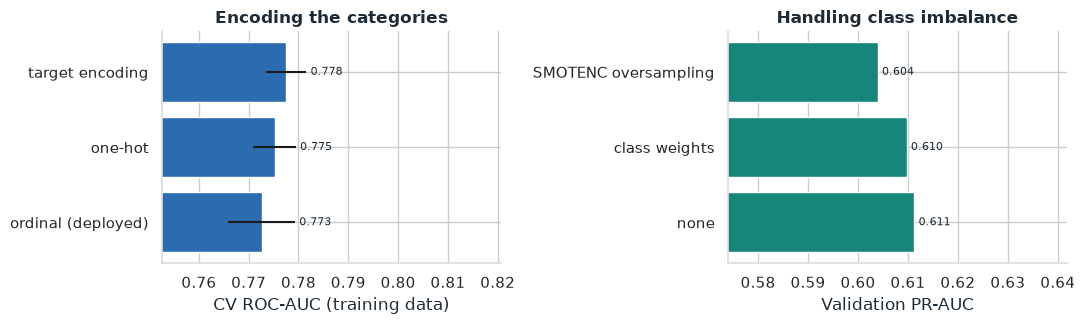


- **Encoding:** the best encoding is 0.0050 ROC-AUC ahead of the ordinal codes the deployed model
  uses. Ordinal codes keep the model small and the ONNX export simple, which matters more here than a
  difference of that size.
- **Imbalance:** validation PR-AUC is 0.611 with no correction,
  0.610 with class weights and 0.604
  with SMOTENC. Class weights and oversampling also push the average predicted probability away from the
  real cancellation rate (27.5%), which would have to be calibrated back.
  **Decision: no resampling.** The imbalance is moderate, the ranking does not improve, and threshold moving
  plus calibration handle the decision directly.
- **More features:** adding 8 features changes
  cross-validated ROC-AUC by **+0.0017** on average (between -0.0004 and
  +0.0033 across the folds, whose own spread is 0.0015).
  **Decision: not adopted.** A gain that small does not justify more inputs for the API to collect, and it
  shows that further feature engineering on these columns will not close the gap to the target.


In [43]:
encodings = compare_encodings(frames["X_train"], frames["y_train"], frames["cats"], frames["nums"], cfg)
imbalance = compare_imbalance(frames["X_train"], frames["y_train"], frames["X_validation"], frames["y_validation"],
                              frames["cats"], frames["nums"], cfg)
feature_additions = compare_feature_sets(train_rows, cfg)
display(encodings.round(4))
display(imbalance.round(4))
display(feature_additions.round(4))
finish_figure(plot_experiments(encodings, imbalance), "models_experiments", ctx)
enc_gap = encodings["cv_roc_auc_mean"].max() - encodings.set_index("encoding").loc["ordinal (deployed)", "cv_roc_auc_mean"]
imb = imbalance.set_index("method")
extra = feature_additions.iloc[1]
say(f"""
- **Encoding:** the best encoding is {enc_gap:.4f} ROC-AUC ahead of the ordinal codes the deployed model
  uses. Ordinal codes keep the model small and the ONNX export simple, which matters more here than a
  difference of that size.
- **Imbalance:** validation PR-AUC is {imb.loc['none', 'val_pr_auc']:.3f} with no correction,
  {imb.loc['class weights', 'val_pr_auc']:.3f} with class weights and {imb.loc['SMOTENC oversampling', 'val_pr_auc']:.3f}
  with SMOTENC. Class weights and oversampling also push the average predicted probability away from the
  real cancellation rate ({imb.loc['none', 'actual_rate']:.1%}), which would have to be calibrated back.
  **Decision: no resampling.** The imbalance is moderate, the ranking does not improve, and threshold moving
  plus calibration handle the decision directly.
- **More features:** adding {int(extra['columns'] - feature_additions.iloc[0]['columns'])} features changes
  cross-validated ROC-AUC by **{extra['gain_mean']:+.4f}** on average (between {extra['gain_min']:+.4f} and
  {extra['gain_max']:+.4f} across the folds, whose own spread is {feature_additions.iloc[0]['cv_roc_auc_std']:.4f}).
  **Decision: not adopted.** A gain that small does not justify more inputs for the API to collect, and it
  shows that further feature engineering on these columns will not close the gap to the target.
""")

## 6. Model evaluation and hyperparameter tuning

### 6.1 Three search strategies, in two stages

**Stage 1: compare the strategies cheaply.** All searches use 3-fold stratified cross-validation on a
stratified training subsample, fixed trial counts and seeded samplers, so they are reproducible.

- **Grid search** on logistic regression: regularisation strength and class weights.
- **Random search** on the random forest: number of trees, depth, leaf size, features per split.
- **All three strategies on LightGBM with the same budget**, so their efficiency can be compared fairly:
  a grid over three key settings, random search and Bayesian optimisation (Optuna's TPE sampler) over
  eight settings.

**Stage 2: refine on all training rows.** The best settings for a small sample are not the best for the
full training set (less data favours smaller, slower-learning models). So a second Bayesian search runs
on all training rows. Its first trials are LightGBM's untuned settings and the winner of each stage-1
search, so it can only match or beat them in cross-validation; the sampler then explores from there.

The best setting of each family is then refitted on all training rows and scored on validation.

,search,strategy,model,rows,configurations,fits,best_cv_roc_auc,seconds
0,logreg_grid,grid,logreg,20000,8,24,0.7729,14.6
1,rf_random,random,rf,20000,20,60,0.7819,345.5
2,lgbm_grid,grid,lgbm,20000,24,72,0.7835,188.1
3,lgbm_random,random,lgbm,20000,24,72,0.7856,203.8
4,lgbm_bayesian,bayesian,lgbm,20000,24,72,0.7866,169.5
5,lgbm_refine,"bayesian, all training rows",lgbm,61058,24,72,0.8043,408.8


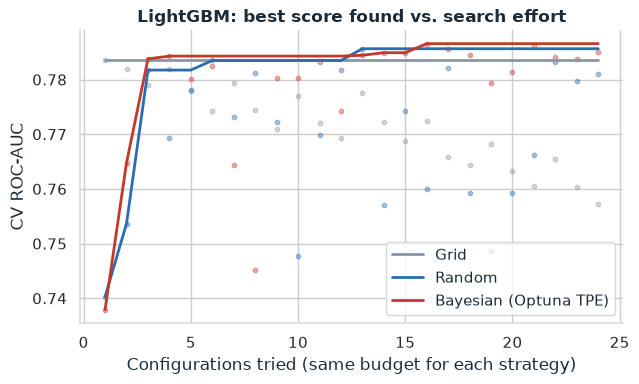


**Stage 1.** With the same budget of 24 configurations, the best
cross-validated ROC-AUC was 0.7835 for grid search, 0.7856 for random search and
0.7866 for Bayesian optimisation. Grid search can only find what its grid contains; random
and Bayesian search explore more settings at the same cost, and Bayesian search uses earlier results to
choose where to look next. The differences between strategies are small here, which is itself informative:
the score is not very sensitive to the settings.

**Stage 2** (all 61,058 training rows). Scores of the starting points:
untuned settings 0.7980, best of grid search 0.7937, best of random search 0.8017, best of Bayesian search 0.7984. Best after 24
configurations: **0.8043**. Scores in the two stages are not comparable with each other,
because stage 2 trains on more rows per fold.


In [44]:
tuning = tune_all(frames["X_train"], frames["y_train"], frames["cats"], frames["nums"], cfg)
search_keys = ["logreg_grid", "rf_random", "lgbm_grid", "lgbm_random", "lgbm_bayesian", "lgbm_refine"]
summary = pd.DataFrame([{"search": k, "strategy": tuning[k]["strategy"], "model": tuning[k]["model"],
                         "rows": tuning[k].get("rows", tuning["subsample_rows"]),
                         "configurations": tuning[k]["configs_tried"], "fits": tuning[k]["fits"],
                         "best_cv_roc_auc": tuning[k]["best_score"], "seconds": tuning[k]["seconds"]}
                        for k in search_keys])
display(summary.round(4))
finish_figure(plot_search_comparison(tuning), "tuning_strategies", ctx)
lg = {k: tuning[k]["best_score"] for k in ("lgbm_grid", "lgbm_random", "lgbm_bayesian")}
refine = tuning["lgbm_refine"]
starts = dict(zip(refine["started_from"], refine["start_scores"]))
say(f"""
**Stage 1.** With the same budget of {tuning['lgbm_grid']['configs_tried']} configurations, the best
cross-validated ROC-AUC was {lg['lgbm_grid']:.4f} for grid search, {lg['lgbm_random']:.4f} for random search and
{lg['lgbm_bayesian']:.4f} for Bayesian optimisation. Grid search can only find what its grid contains; random
and Bayesian search explore more settings at the same cost, and Bayesian search uses earlier results to
choose where to look next. The differences between strategies are small here, which is itself informative:
the score is not very sensitive to the settings.

**Stage 2** (all {refine['rows']:,} training rows). Scores of the starting points:
{', '.join(f'{name} {score:.4f}' for name, score in starts.items())}. Best after {refine['configs_tried']}
configurations: **{refine['best_score']:.4f}**. Scores in the two stages are not comparable with each other,
because stage 2 trains on more rows per fold.
""")

In [45]:
fitted = fit_tuned_models(tuning, frames, cfg)
champion = pick_champion(fitted, cfg)
display(pd.DataFrame(champion["comparison"]).drop(columns="params").round(4))
tied = champion["tied_models"]
untuned_val = by_model.loc[champion["name"], "val_roc_auc"] if champion["name"] in by_model.index else float("nan")
say(f"**Champion: {champion['name']}** (search: {champion['strategy']}), validation ROC-AUC "
    f"**{champion['val_roc_auc']:.4f}** against a best of {champion['best_val_roc_auc']:.4f} among the tuned "
    f"models, and {untuned_val:.4f} for the same model family with untuned settings (Section 5). Settings: "
    f"`{champion['params']}`."
    + (f" The tree models {', '.join(tied)} are within {cfg.selection.tie_tolerance} of each other on validation, "
       "a difference below run-to-run noise, so the smallest is chosen: it deploys and scores faster. The rule "
       "uses validation data only." if len(tied) > 1 else ""))
dummy = make_model("dummy", frames["cats"], frames["nums"], cfg).fit(frames["X_train"], frames["y_train"])
test_models = {"dummy": dummy, "logreg": fitted["logreg"]["model"], "champion": fitted[champion["name"]]["model"]}
champion_model = test_models["champion"]

,model,strategy,cv_roc_auc,val_roc_auc,size_kb
0,logreg,grid,0.7729,0.7767,11.3
1,rf,random,0.7819,0.8020,88321.0
2,lgbm,"bayesian, all training rows",0.8043,0.8098,9011.4


**Champion: lgbm** (search: bayesian, all training rows), validation ROC-AUC **0.8098** against a best of 0.8098 among the tuned models, and 0.8047 for the same model family with untuned settings (Section 5). Settings: `{'num_leaves': 136, 'learning_rate': 0.019948930432040424, 'n_estimators': 630, 'min_child_samples': 7, 'subsample': 0.8829843611389542, 'colsample_bytree': 0.5929159719177697, 'reg_lambda': 0.1407655368983871, 'subsample_freq': 1}`.

### 6.2 Underfitting or overfitting?

The **learning curve** shows the score on training folds and held-out folds as the training set grows.
A large, persistent gap means overfitting; two low, converged curves mean underfitting. The
**validation curve** varies model capacity (`num_leaves`) with everything else fixed.

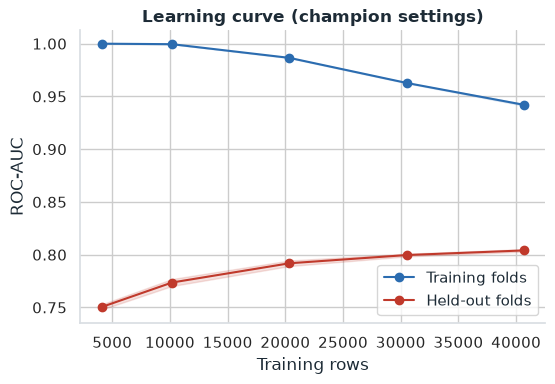

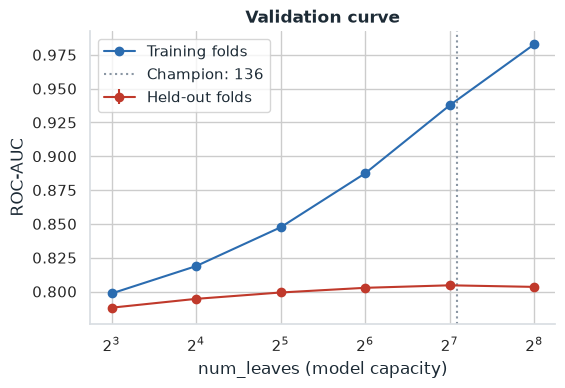

**Overfitting: yes, and it is the harmless kind.** At full size the training-fold score is 0.942 and the held-out score 0.804 (gap 0.138); on all training rows the champion scores 0.915 against 0.810 on validation. A boosted ensemble of this size can partly memorise its training rows, so its training score says little; what matters is the held-out score, and these settings were chosen because they maximise it in cross-validation, over a search space that includes much smaller and more heavily regularised models. The validation curve answers the natural follow-up, whether a smaller model would generalise better: the held-out score is highest at 128 leaves (0.8046), against 0.7880 at 8 leaves and 0.8034 at 256, while the training score climbs from 0.799 to 0.983. Too little capacity costs held-out score (that side is underfitting) and too much only adds memorisation; the champion uses 136 leaves. **Underfitting: no.** A more flexible model does not do better on held-out data. **More data:** the last step of the learning curve added +0.0044 to the held-out score, so the curve is still rising slowly and more bookings of the same kind would help a little, but nowhere near enough to reach the target.

In [46]:
diag = run_diagnostics(champion_model, champion, frames, cfg)
lc = diag["learning_curve"]
finish_figure(plot_learning_curve(lc), "diag_learning_curve", ctx)
if diag["validation_curve"]:
    finish_figure(plot_validation_curve(diag["validation_curve"]), "diag_validation_curve", ctx)
gap = lc["train_mean"][-1] - lc["cv_mean"][-1]
last_gain = lc["cv_mean"][-1] - lc["cv_mean"][-2]
vc = diag["validation_curve"]
capacity_note = ""
if vc:
    best_i = int(np.argmax(vc["cv_mean"]))
    capacity_note = (
        f" The validation curve answers the natural follow-up, whether a smaller model would generalise better: "
        f"the held-out score is highest at {vc['values'][best_i]} leaves ({vc['cv_mean'][best_i]:.4f}), against "
        f"{vc['cv_mean'][0]:.4f} at {vc['values'][0]} leaves and {vc['cv_mean'][-1]:.4f} at {vc['values'][-1]}, while "
        f"the training score climbs from {vc['train_mean'][0]:.3f} to {vc['train_mean'][-1]:.3f}. Too little "
        "capacity costs held-out score (that side is underfitting) and too much only adds memorisation; the "
        f"champion uses {vc['chosen']} leaves.")
say(f"**Overfitting: yes, and it is the harmless kind.** At full size the training-fold score is "
    f"{lc['train_mean'][-1]:.3f} and the held-out score {lc['cv_mean'][-1]:.3f} (gap {gap:.3f}); on all training "
    f"rows the champion scores {diag['train_roc_auc']:.3f} against {diag['val_metrics']['roc_auc']:.3f} on "
    "validation. A boosted ensemble of this size can partly memorise its training rows, so its training score "
    "says little; what matters is the held-out score, and these settings were chosen because they maximise it "
    "in cross-validation, over a search space that includes much smaller and more heavily regularised models."
    + capacity_note
    + f" **Underfitting: no.** A more flexible model does not do better on held-out data. **More data:** the "
      f"last step of the learning curve added {last_gain:+.4f} to the held-out score, so "
    + ("the curve is still rising slowly and more bookings of the same kind would help a little, but nowhere "
       "near enough to reach the target." if last_gain > 0.002 else
       "the curve has flattened and more bookings of the same kind would help little."))

### 6.3 Calibration, the decision threshold and the classification metrics

**Calibration.** The hotel acts on the probability, so a predicted 30% should mean about 30% of such
bookings cancel. Isotonic calibration is fitted on validation only if it improves the out-of-fold Brier
score there.

**Threshold.** The default 0.5 ignores the costs. The threshold that minimises the expected cost per
booking on validation is used instead.

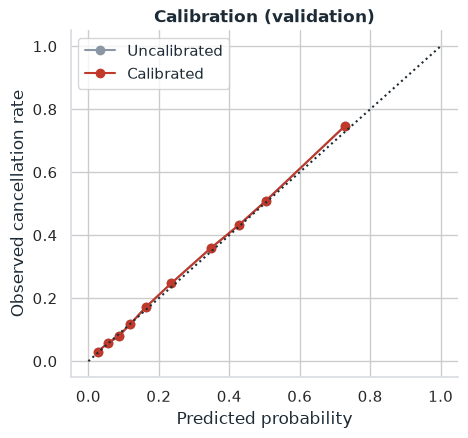

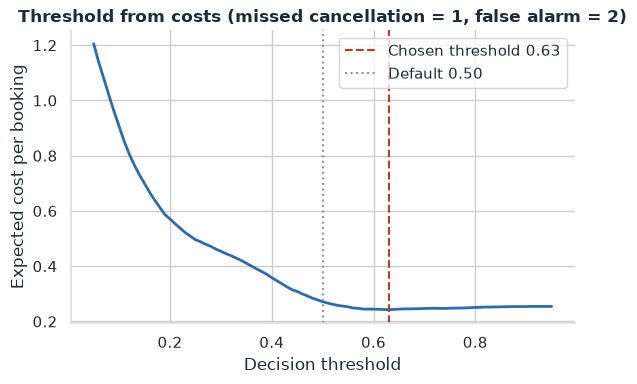

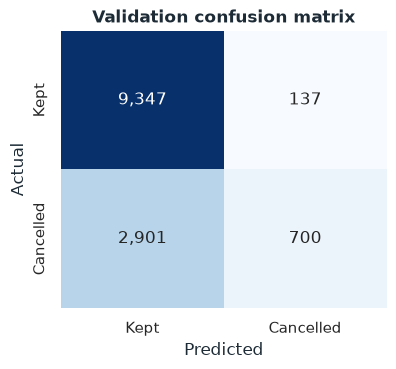

Calibration is not needed: out-of-fold Brier score 0.1483 against 0.1478 uncalibrated. The cost-minimising threshold is **0.63**. Because a false alarm costs twice a missed cancellation, the model flags a booking only when it is fairly sure: on validation, precision is 0.84 and recall 0.19.

In [47]:
finish_figure(plot_calibration(frames["y_validation"], diag["val_proba_raw"], diag["val_proba"]), "diag_calibration", ctx)
finish_figure(plot_cost_curve(diag["cost_curve"], diag["threshold"], cfg.costs.false_negative,
                              cfg.costs.false_positive), "diag_threshold_cost", ctx)
finish_figure(plot_confusion(diag["val_confusion"], "Validation confusion matrix"), "diag_confusion_val", ctx)
cal = diag["calibration"]
say(f"Calibration {'is used' if cal['used'] else 'is not needed'}: out-of-fold Brier score {cal['brier_calibrated_out_of_fold']:.4f} "
    f"against {cal['brier_raw']:.4f} uncalibrated. The cost-minimising threshold is **{diag['threshold']:.2f}**. "
    f"Because a false alarm costs twice a missed cancellation, the model flags a booking only when it is fairly "
    f"sure: on validation, precision is {diag['val_metrics']['precision']:.2f} and recall "
    f"{diag['val_metrics']['recall']:.2f}.")

**Is the low recall a problem with the model or a consequence of the costs?** With calibrated
probabilities, acting on a booking pays off only when its probability of cancelling exceeds
false-alarm cost / (false-alarm cost + missed-cancellation cost) = 2 / 3. Few bookings are that certain
to cancel, so few are flagged and recall is low. That is the cost assumption doing its job, not a
defect: the same model gives very different precision and recall at other thresholds. The table shows
three operating points, all chosen on validation, and the second table shows how the decision moves
when a false alarm is cheaper or dearer than relocating a guest (for example a confirmation e-mail,
where a false alarm costs almost nothing).

,operating_point,threshold,flagged_share,accuracy,precision,recall,f1
0,cost-based (deployed),0.63,0.064,0.768,0.836,0.194,0.315
1,default 0.5,0.50,0.151,0.778,0.675,0.371,0.478
2,best F1,0.29,0.401,0.734,0.511,0.745,0.607


,false_alarm_cost,threshold,flagged_share,precision,recall,f1,cost_per_booking,cost_without_model,saving
0,0.2,0.17,0.537,0.441,0.859,0.583,0.099,0.145,0.319
1,0.5,0.31,0.385,0.519,0.727,0.606,0.168,0.275,0.390
2,1.0,0.50,0.151,0.675,0.371,0.478,0.222,0.275,0.192
3,2.0,0.63,0.064,0.836,0.194,0.315,0.243,0.275,0.118
4,3.0,0.74,0.036,0.929,0.120,0.213,0.250,0.275,0.093


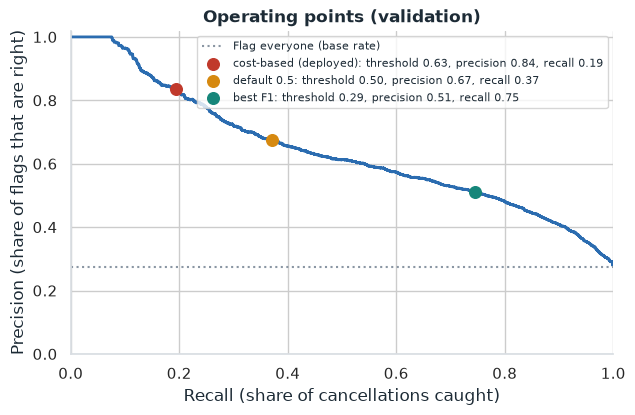


- **Cost-based (deployed):** threshold 0.63, flags
  6.4% of bookings, precision
  0.84, recall 0.19,
  F1 0.32.
- **Best F1:** threshold 0.29, precision 0.51,
  recall 0.75, F1 0.61.
- At the stated costs the model lowers the expected cost by 11.8% compared with the
  best rule that needs no model. That is a modest saving, and it is reported as such: when a wrong flag is
  expensive, a model of this strength should flag few bookings. If a false alarm cost
  0.2 instead (a reminder e-mail), the threshold would drop to 0.17, recall
  would rise to 0.86 and the saving to 31.9%.


In [48]:
display(diag["val_operating_metrics"].round(3))
display(diag["val_cost_sensitivity"].round(3))
finish_figure(plot_operating_points(frames["y_validation"], diag["val_proba"], diag["val_operating_metrics"],
                                    "Operating points (validation)"), "diag_operating_points", ctx)
ops = diag["val_operating_metrics"].set_index("operating_point")
sens = diag["val_cost_sensitivity"].set_index("false_alarm_cost")
deployed_cost = sens.loc[cfg.costs.false_positive]
cheap = sens.iloc[0]
say(f"""
- **Cost-based (deployed):** threshold {ops.loc['cost-based (deployed)', 'threshold']:.2f}, flags
  {ops.loc['cost-based (deployed)', 'flagged_share']:.1%} of bookings, precision
  {ops.loc['cost-based (deployed)', 'precision']:.2f}, recall {ops.loc['cost-based (deployed)', 'recall']:.2f},
  F1 {ops.loc['cost-based (deployed)', 'f1']:.2f}.
- **Best F1:** threshold {ops.loc['best F1', 'threshold']:.2f}, precision {ops.loc['best F1', 'precision']:.2f},
  recall {ops.loc['best F1', 'recall']:.2f}, F1 {ops.loc['best F1', 'f1']:.2f}.
- At the stated costs the model lowers the expected cost by {deployed_cost['saving']:.1%} compared with the
  best rule that needs no model. That is a modest saving, and it is reported as such: when a wrong flag is
  expensive, a model of this strength should flag few bookings. If a false alarm cost
  {cheap.name:g} instead (a reminder e-mail), the threshold would drop to {cheap['threshold']:.2f}, recall
  would rise to {cheap['recall']:.2f} and the saving to {cheap['saving']:.1%}.
""")

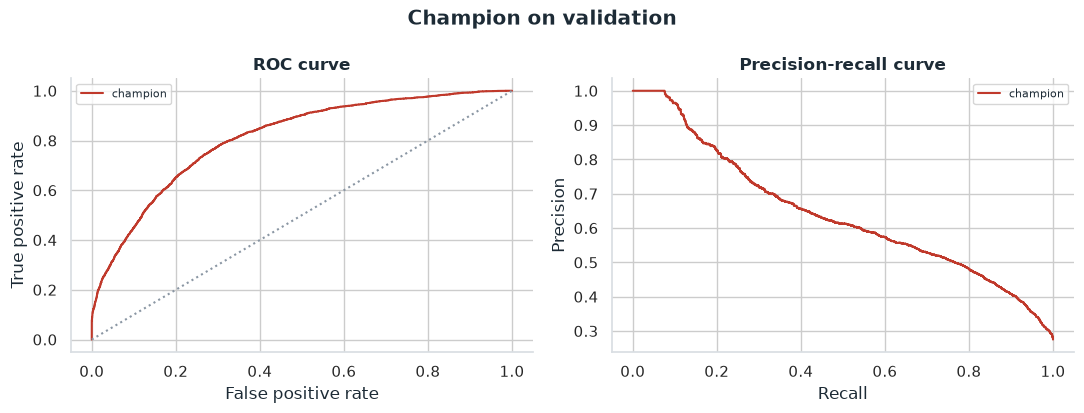

In [49]:
finish_figure(plot_roc_pr({"champion": (frames["y_validation"], diag["val_proba"])}, "Champion on validation"),
              "diag_roc_pr_val", ctx)

### 6.4 What the scores mean for the hotel

Two views that do not depend on a threshold, both on validation data here and repeated on the test
set in Section 8.

- **Risk groups.** Sort bookings by predicted risk and cut them into ten equal groups. A useful model
  concentrates the cancellations in the first groups.
- **Cancellations per hotel and week.** Overbooking is decided for a hotel and a period, on the
  expected *number* of cancellations: the sum of the predicted probabilities. It is compared with the
  forecast that needs no model (number of bookings times the overall cancellation rate in training).
  The error measure is WAPE: summed absolute error divided by the summed actual count.

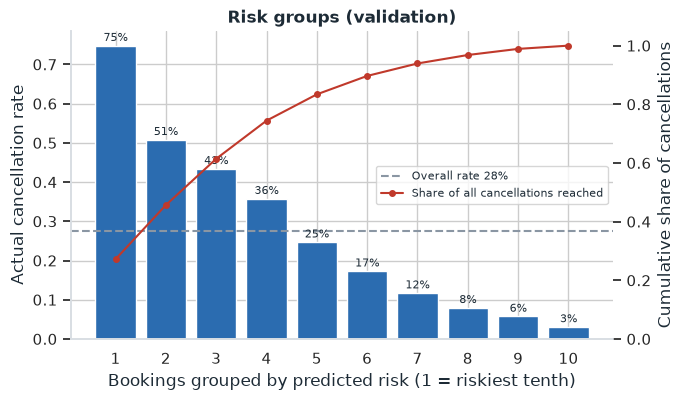

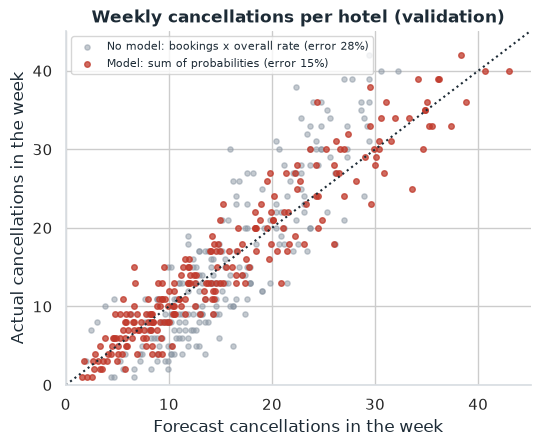

The riskiest tenth of bookings cancels **75%** of the time and the safest tenth 3%; the riskiest three tenths contain **61%** of all cancellations. Per hotel and week (228 hotel-weeks, median 53 validation bookings each), the summed probabilities miss the actual number of cancellations by **15%** (WAPE), against 28% for the no-model forecast; over all weeks the total is off by -2.2%. Added up over a week, the errors on single bookings partly cancel out, which is why forecasting counts is the use this model suits best.

In [50]:
finish_figure(plot_gains(diag["val_gains"], "Risk groups (validation)"), "diag_gains", ctx)
finish_figure(plot_capacity(diag["val_capacity"], "Weekly cancellations per hotel (validation)"), "diag_capacity", ctx)
gains, cap = diag["val_gains"], diag["val_capacity"]
say(f"The riskiest tenth of bookings cancels **{gains.iloc[0]['cancel_rate']:.0%}** of the time and the safest "
    f"tenth {gains.iloc[-1]['cancel_rate']:.0%}; the riskiest three tenths contain "
    f"**{gains.iloc[2]['cumulative_share_of_cancellations']:.0%}** of all cancellations. Per hotel and week "
    f"({cap['weeks']} hotel-weeks, median {cap['bookings_per_week_median']:.0f} validation bookings each), the "
    f"summed probabilities miss the actual number of cancellations by **{cap['wape_model']:.0%}** (WAPE), "
    f"against {cap['wape_base_rate']:.0%} for the no-model forecast; over all weeks the total is off by "
    f"{cap['bias']:+.1%}."
    + (" Added up over a week, the errors on single bookings partly cancel out, which is why forecasting counts "
       "is the use this model suits best." if cap["wape_model"] < cap["wape_base_rate"] else ""))

### 6.5 Error analysis and explanations

Where is the model wrong, and what drives its predictions? All computed on validation data.

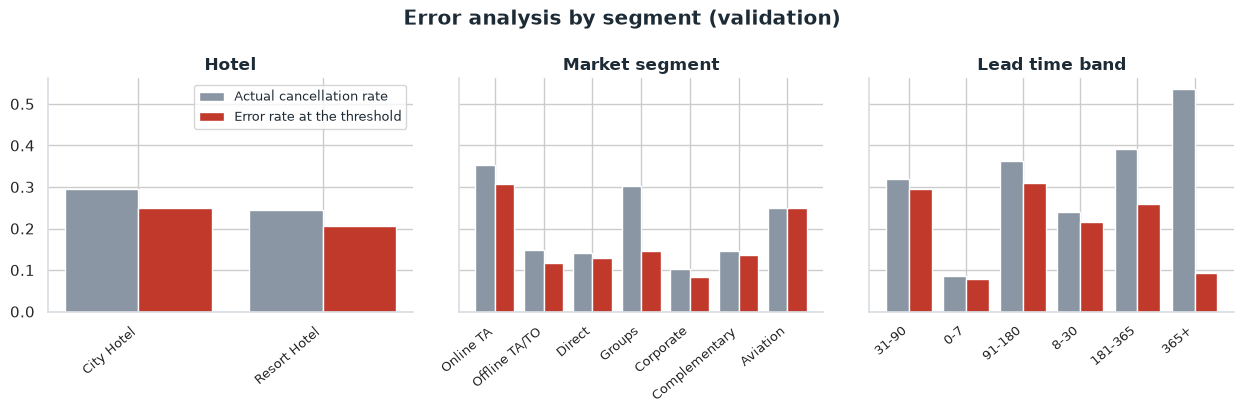

,by,segment,rows,actual_cancel_rate,predicted_cancel_rate,error_rate,roc_auc
0,hotel,City Hotel,8022,0.295,0.064,0.249,0.797
1,hotel,Resort Hotel,5063,0.244,0.065,0.205,0.827
2,market_segment,Online TA,7731,0.352,0.079,0.308,0.766
3,market_segment,Offline TA/TO,2055,0.149,0.033,0.116,0.793
4,market_segment,Direct,1744,0.140,0.013,0.130,0.740
5,market_segment,Groups,787,0.302,0.160,0.145,0.875
6,market_segment,Corporate,630,0.103,0.019,0.084,0.759
7,market_segment,Complementary,102,0.147,0.010,0.137,0.674
8,market_segment,Aviation,36,0.250,0.000,0.250,0.667
9,lead_time_band,31-90,3428,0.319,0.041,0.295,0.753


In [51]:
finish_figure(plot_segments(diag["segments"]), "diag_segments", ctx)
display(diag["segments"].round(3))

In [52]:
# Copied from hotel_cancellation.explain by scripts/build_notebooks.py
from __future__ import annotations

def permutation_importance_frame(model, X_val: pd.DataFrame, y_val, cfg: Config) -> pd.DataFrame:
    """Drop in validation ROC-AUC when each feature is shuffled."""
    result = permutation_importance(model, X_val, y_val, scoring="roc_auc",
                                    n_repeats=cfg.explain.permutation_repeats, random_state=cfg.seed,
                                    n_jobs=1)
    return (pd.DataFrame({"feature": X_val.columns, "importance_mean": result.importances_mean,
                          "importance_std": result.importances_std})
            .sort_values("importance_mean", ascending=False).reset_index(drop=True))


def shap_explanation(model, X_val: pd.DataFrame, cfg: Config) -> shap.Explanation:
    """SHAP values (log-odds) for a sample of validation rows, for tree models."""
    n = min(cfg.explain.shap_rows, len(X_val))
    sample = X_val.sample(n=n, random_state=cfg.seed)
    transformed = model[:-1].transform(sample)
    names = list(model.named_steps["prep"].get_feature_names_out())
    explainer = shap.TreeExplainer(model.named_steps["model"])
    values = explainer(pd.DataFrame(transformed, columns=names, index=sample.index))
    if values.values.ndim == 3:  # some versions return one column per class
        values = values[:, :, 1]
    return values


def shap_importance_frame(values: shap.Explanation) -> pd.DataFrame:
    return (pd.DataFrame({"feature": values.feature_names,
                          "mean_abs_shap": np.abs(values.values).mean(0)})
            .sort_values("mean_abs_shap", ascending=False).reset_index(drop=True))

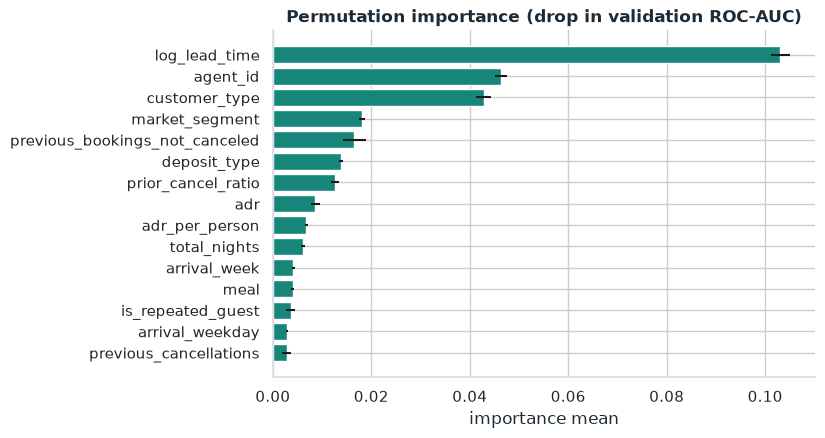

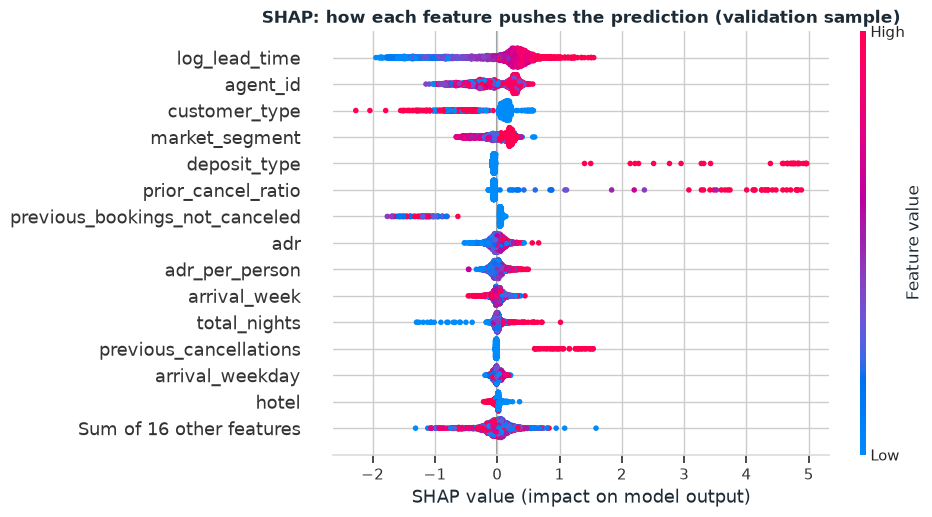

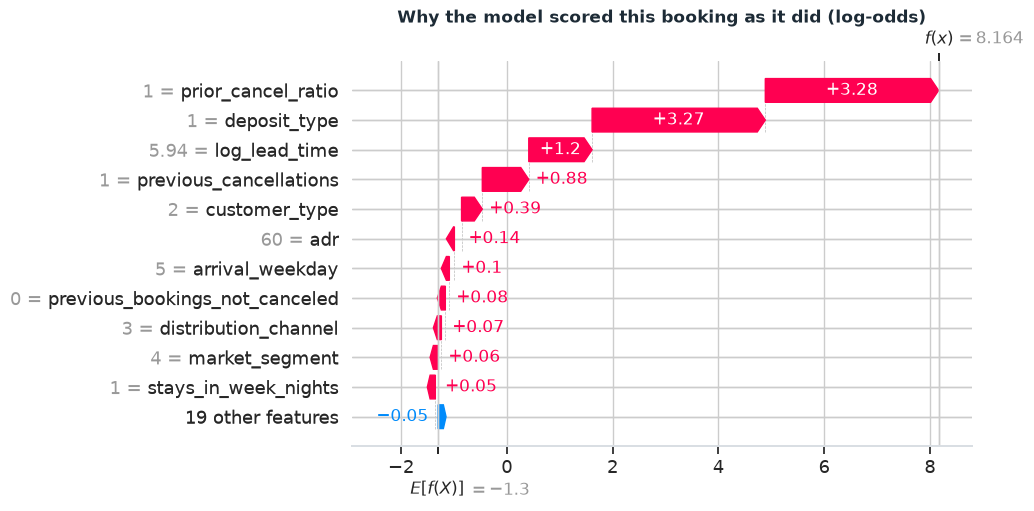

The most important features by permutation are `log_lead_time`, `agent_id`, `customer_type`, `market_segment`. SHAP's leaders are `log_lead_time`, `agent_id`, `customer_type`, `market_segment`. In the SHAP plot each dot is one booking: a dot to the right raised the predicted risk, and red means a high value of the feature. For numeric features that gives a direction (for example, whether long lead times sit on the right); for categorical features the colour is only a code, so the plot shows how much they matter, not which way. The waterfall shows how the features combine for the single booking with the highest predicted risk in the sample.

In [53]:
perm = permutation_importance_frame(champion_model, frames["X_validation"], frames["y_validation"], cfg)
finish_figure(plot_importance(perm, "importance_mean", "importance_std",
                              "Permutation importance (drop in validation ROC-AUC)"), "explain_permutation", ctx)
shap_values = shap_explanation(champion_model, frames["X_validation"], cfg)
shap_imp = shap_importance_frame(shap_values)
finish_figure(plot_shap_summary(shap_values), "explain_shap_summary", ctx)
finish_figure(plot_shap_waterfall(shap_values, int(np.argmax(shap_values.values.sum(1)))), "explain_shap_waterfall", ctx)
say(f"The most important features by permutation are {', '.join(f'`{f}`' for f in perm['feature'].head(4))}. "
    f"SHAP's leaders are {', '.join(f'`{f}`' for f in shap_imp['feature'].head(4))}. In the SHAP plot each dot is "
    "one booking: a dot to the right raised the predicted risk, and red means a high value of the feature. For "
    "numeric features that gives a direction (for example, whether long lead times sit on the right); for "
    "categorical features the colour is only a code, so the plot shows how much they matter, not which way. The "
    "waterfall shows how the features combine for the single booking with the highest predicted risk in the sample.")

### 6.6 Robustness over time

The stratified split mixes all years. A hotel would train on the past and predict the future, so the
champion's settings are refitted on arrivals up to 2016 and scored on 2017, using training and
validation rows only.

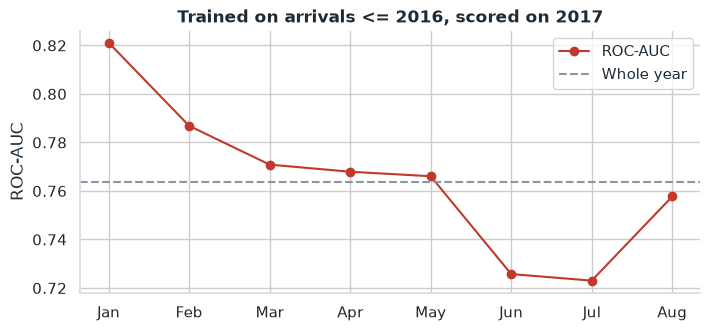

Trained on 47,276 earlier bookings and scored on 26,867 bookings from 2017: ROC-AUC **0.764**, against 0.810 on the stratified validation set. The difference is the price of predicting a year the model has not seen; Section 10 turns this into a retraining policy.

In [54]:
temporal = temporal_check(trval, champion["params"] if champion["name"] == "lgbm" else {}, cfg)
finish_figure(plot_temporal(temporal), "diag_temporal", ctx)
say(f"Trained on {temporal['fit_rows']:,} earlier bookings and scored on {temporal['eval_rows']:,} bookings from "
    f"{temporal['eval_year']}: ROC-AUC **{temporal['eval_roc_auc']:.3f}**, against {diag['val_metrics']['roc_auc']:.3f} "
    "on the stratified validation set. The difference is the price of predicting a year the model has not seen; "
    "Section 10 turns this into a retraining policy.")

## 8. Model testing and deployment

### 8.1 The final evaluation on the test set

The models scored on the test set were fixed in the configuration in advance: the majority-class
baseline, the tuned logistic regression and the champion. Each uses the threshold chosen on validation,
and only the champion is calibrated. The metrics are the same as in the evaluation step.

**The test set has been scored twice, and this is the second time.**

In [55]:
first = cfg.first_test_evaluation
say(f"""
| | First evaluation ({first.date}) | This run |
|---|---|---|
| Champion | {first.champion} | {champion['name']} (search: {champion['strategy']}) |
| Validation ROC-AUC | {first.validation_roc_auc:.4f} | {champion['val_roc_auc']:.4f} |

**What changed between the two, and why.** {" ".join(first.what_changed_afterwards.split())}

**What this means for the numbers below.** A test set that has been looked at is no longer perfectly
unseen: the decision to improve the tuning was taken after the first test result was known, even though
the change itself was chosen on validation data and would have been made on the validation evidence alone
(a tuned model scoring below the untuned one is a defect whatever the test score). The second result is
reported whether it is higher or lower than the first, both are shown, and the first evaluation's test
ROC-AUC was {first.roc_auc:.4f} (95% CI {first.roc_auc_ci[0]:.4f} to {first.roc_auc_ci[1]:.4f}).
""")


| | First evaluation (2026-11-10) | This run |
|---|---|---|
| Champion | LightGBM tuned by Bayesian search on a 20,000-row training subsample | lgbm (search: bayesian, all training rows) |
| Validation ROC-AUC | 0.8017 | 0.8098 |

**What changed between the two, and why.** Only the champion's hyperparameters. The first champion scored lower on validation than LightGBM with default settings, because settings found on a 20,000-row subsample do not transfer to the full training set. A second search stage on all training rows was added. The data, the split, the features, the leakage decisions, the costs and the success criterion are unchanged, and the change was decided on validation data before the test set was scored again.

**What this means for the numbers below.** A test set that has been looked at is no longer perfectly
unseen: the decision to improve the tuning was taken after the first test result was known, even though
the change itself was chosen on validation data and would have been made on the validation evidence alone
(a tuned model scoring below the untuned one is a defect whatever the test score). The second result is
reported whether it is higher or lower than the first, both are shown, and the first evaluation's test
ROC-AUC was 0.7974 (95% CI 0.7887 to 0.8049).


Models declared for the test pass: ['dummy', 'logreg', 'champion']


,model,roc_auc,pr_auc,brier,accuracy,precision,recall,f1,threshold,f1_at_0.5,cost_per_booking
0,dummy,0.5000,0.2752,0.1995,0.7248,0.0000,0.0000,0.0000,0.28,0.0000,0.2752
1,logreg,0.7740,0.5916,0.1580,0.7515,0.8525,0.1172,0.2061,0.61,0.4211,0.2541
2,champion,0.8069,0.6355,0.1487,0.7655,0.8117,0.1927,0.3115,0.63,0.4674,0.2468


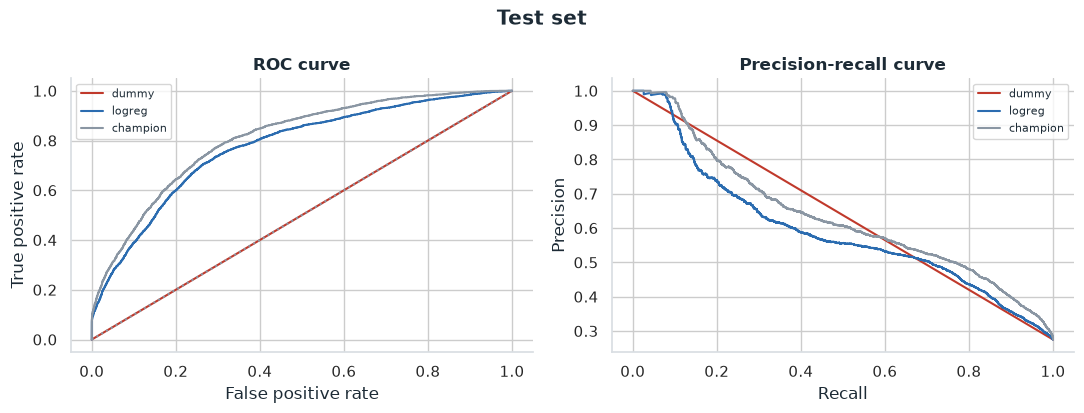

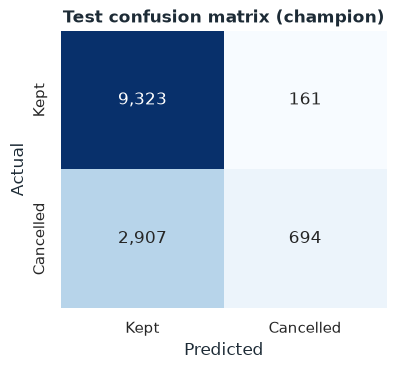

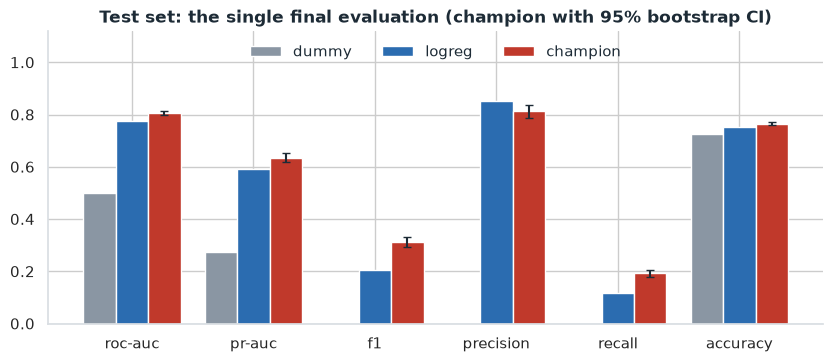

In [56]:
print("Models declared for the test pass:", cfg.test_pass_models)
test = final_test_pass(test_models, diag["calibration"], frames, cfg)
rows = []
for name, r in test["models"].items():
    rows.append({"model": name, **{k: r["metrics"][k] for k in ["roc_auc", "pr_auc", "brier", "accuracy", "precision",
                                                              "recall", "f1", "threshold"]},
                 "f1_at_0.5": r["metrics_at_0_5"]["f1"], "cost_per_booking": r["cost_per_booking"]})
display(pd.DataFrame(rows).round(4))
finish_figure(plot_roc_pr({n: (frames["y_test"], r["proba"]) for n, r in test["models"].items()}, "Test set"),
              "test_roc_pr", ctx)
finish_figure(plot_confusion(test["models"]["champion"]["confusion"], "Test confusion matrix (champion)"),
              "test_confusion", ctx)
finish_figure(plot_test_results(test), "test_results", ctx)

**The champion at the three operating points, and for the hotel's two uses** (thresholds from
validation; the same analyses as Sections 6.3 and 6.4):

,operating_point,threshold,flagged_share,accuracy,precision,recall,f1
0,cost-based (deployed),0.63,0.065,0.766,0.812,0.193,0.311
1,default 0.5,0.50,0.151,0.773,0.661,0.362,0.467
2,best F1,0.29,0.405,0.731,0.507,0.746,0.604


,false_alarm_cost,threshold,flagged_share,precision,recall,f1,cost_per_booking,cost_without_model,saving
0,0.2,0.17,0.537,0.440,0.859,0.582,0.099,0.145,0.317
1,0.5,0.31,0.389,0.516,0.728,0.604,0.169,0.275,0.386
2,1.0,0.50,0.151,0.661,0.362,0.467,0.227,0.275,0.176
3,2.0,0.63,0.065,0.812,0.193,0.311,0.247,0.275,0.103
4,3.0,0.74,0.039,0.906,0.128,0.224,0.251,0.275,0.088


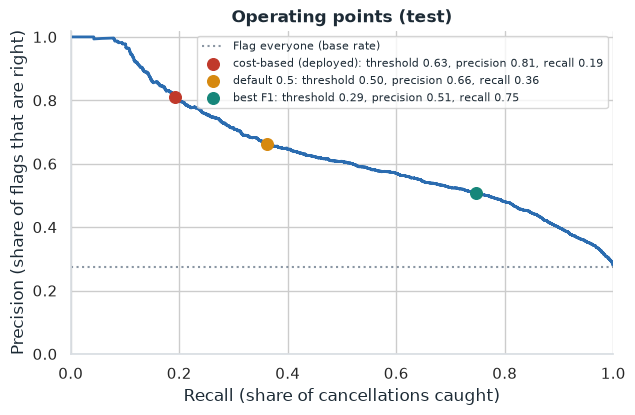

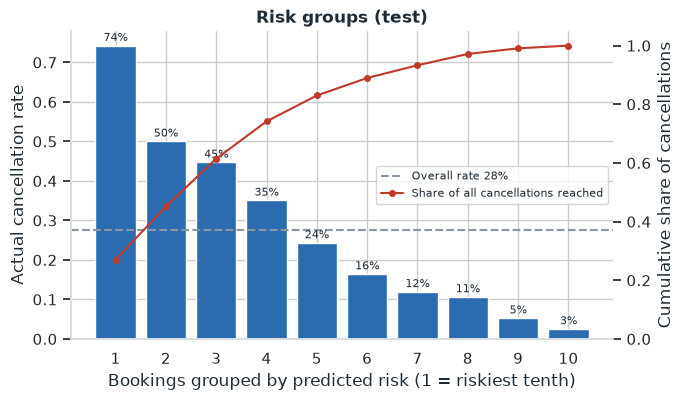

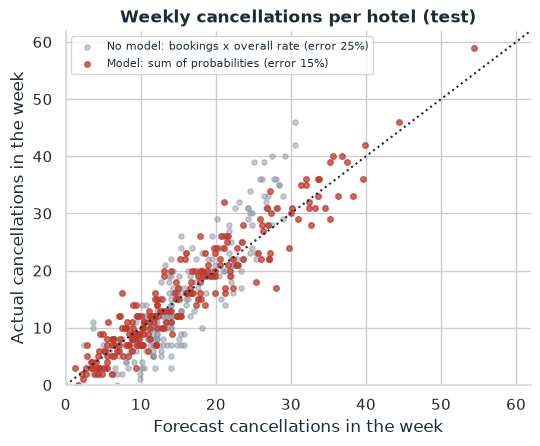

In [57]:
c = test["models"]["champion"]
display(c["operating_metrics"].round(3))
display(c["cost_sensitivity"].round(3))
finish_figure(plot_operating_points(frames["y_test"], c["proba"], c["operating_metrics"], "Operating points (test)"),
              "test_operating_points", ctx)
finish_figure(plot_gains(c["gains"], "Risk groups (test)"), "test_gains", ctx)
finish_figure(plot_capacity(c["capacity"], "Weekly cancellations per hotel (test)"), "test_capacity", ctx)

In [58]:
ci = c["ci"]["roc_auc"]
s = test["success"]
t_ops = c["operating_metrics"].set_index("operating_point")
t_gains, t_cap = c["gains"], c["capacity"]
t_sens = c["cost_sensitivity"].set_index("false_alarm_cost")
say(f"""
**Champion on the test set:** ROC-AUC **{c['metrics']['roc_auc']:.3f}** (95% CI {ci['low']:.3f} to {ci['high']:.3f}),
PR-AUC {c['metrics']['pr_auc']:.3f}, Brier score {c['metrics']['brier']:.4f}.

| Operating point | Threshold | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|---|
""" + "\n".join(f"| {name} | {r['threshold']:.2f} | {r['accuracy']:.3f} | {r['precision']:.3f} | {r['recall']:.3f} | {r['f1']:.3f} |"
                for name, r in t_ops.iterrows()) + f"""

- Expected cost per booking at the stated costs: {c['cost_per_booking']:.3f}, against
  {test['models']['logreg']['cost_per_booking']:.3f} for logistic regression and
  {test['models']['dummy']['cost_per_booking']:.3f} for the majority-class rule
  (a saving of {t_sens.loc[cfg.costs.false_positive, 'saving']:.1%} over the best rule without a model).
- The riskiest tenth of test bookings cancels {t_gains.iloc[0]['cancel_rate']:.0%} of the time, the safest tenth
  {t_gains.iloc[-1]['cancel_rate']:.0%}; the riskiest three tenths contain
  {t_gains.iloc[2]['cumulative_share_of_cancellations']:.0%} of all cancellations.
- Cancellations per hotel and week: error (WAPE) **{t_cap['wape_model']:.0%}** with the model against
  {t_cap['wape_base_rate']:.0%} without; total over all weeks off by {t_cap['bias']:+.1%}.

- Against the first evaluation: test ROC-AUC moved by {c['metrics']['roc_auc'] - first.roc_auc:+.4f}, and
  validation ROC-AUC by {champion['val_roc_auc'] - first.validation_roc_auc:+.4f}. The change on the test set
  mirrors the change that was visible on validation before the test set was scored again.

**Verdict against the criteria set in Section 1:**
- Beats both baselines: **{'yes' if s['beats_baselines'] else 'no'}**.
- Test ROC-AUC of at least {cfg.success.roc_auc}: **{'met' if s['roc_auc_target_met'] else 'not met'}**.
""" + ("" if s["roc_auc_target_met"] else f"""
The target was set before modelling and is not moved after seeing the result. This notebook has shown
why it was missed, with three pieces of evidence:

1. **Scores above {cfg.success.roc_auc} on this data come from information that does not exist at booking
   time.** Adding the columns recorded later lifts validation ROC-AUC from
   {ladder['Deployed (base + kept Tier 3)']:.3f} to {ladder['+ Tier 2 (known after booking)']:.3f} (Section 3.6).
2. **Or from counting easy rows many times.** With duplicates kept and no memorisation possible, the score
   is {duplicates['roc_auc_grouped_split']:.3f}; counting each distinct record once it is
   {duplicates['roc_auc_grouped_one_per_record']:.3f} (Section 3.7).
3. **Better modelling does not close the gap.** The four strongest model families are within
   {candidates['val_roc_auc'].iloc[0] - candidates['val_roc_auc'].iloc[3]:.3f} of each other, eight more features
   add {extra['gain_mean']:+.4f}, and two stages of tuning moved the champion from {untuned_val:.4f} (untuned)
   to {champion['val_roc_auc']:.4f} on validation (Sections 5 and 6).

Reaching the target honestly would need new information available at booking time, such as a guest's
history across stays under a real guest ID, the payment method, or the booking channel's own cancellation
terms, not more tuning. In hindsight the target was set too high for a booking-time model on this data;
that is a finding of the project, and the criterion stays as written.
"""))


**Champion on the test set:** ROC-AUC **0.807** (95% CI 0.799 to 0.814),
PR-AUC 0.636, Brier score 0.1487.

| Operating point | Threshold | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|---|
| cost-based (deployed) | 0.63 | 0.766 | 0.812 | 0.193 | 0.311 |
| default 0.5 | 0.50 | 0.773 | 0.661 | 0.362 | 0.467 |
| best F1 | 0.29 | 0.731 | 0.507 | 0.746 | 0.604 |

- Expected cost per booking at the stated costs: 0.247, against
  0.254 for logistic regression and
  0.275 for the majority-class rule
  (a saving of 10.3% over the best rule without a model).
- The riskiest tenth of test bookings cancels 74% of the time, the safest tenth
  3%; the riskiest three tenths contain
  61% of all cancellations.
- Cancellations per hotel and week: error (WAPE) **15%** with the model against
  25% without; total over all weeks off by -1.2%.

- Against the first evaluation: test ROC-AUC moved by +0.0095, and
  validation ROC-AUC by +0.0081. The change on the test set
  mirrors the change that was visible on validation before the test set was scored again.

**Verdict against the criteria set in Section 1:**
- Beats both baselines: **yes**.
- Test ROC-AUC of at least 0.85: **not met**.

The target was set before modelling and is not moved after seeing the result. This notebook has shown
why it was missed, with three pieces of evidence:

1. **Scores above 0.85 on this data come from information that does not exist at booking
   time.** Adding the columns recorded later lifts validation ROC-AUC from
   0.805 to 0.920 (Section 3.6).
2. **Or from counting easy rows many times.** With duplicates kept and no memorisation possible, the score
   is 0.858; counting each distinct record once it is
   0.800 (Section 3.7).
3. **Better modelling does not close the gap.** The four strongest model families are within
   0.012 of each other, eight more features
   add +0.0017, and two stages of tuning moved the champion from 0.8047 (untuned)
   to 0.8098 on validation (Sections 5 and 6).

Reaching the target honestly would need new information available at booking time, such as a guest's
history across stays under a real guest ID, the payment method, or the booking channel's own cancellation
terms, not more tuning. In hindsight the target was set too high for a booking-time model on this data;
that is a finding of the project, and the criterion stays as written.


### 8.2 Export for deployment

The champion is converted to **ONNX**, a portable format that needs only the small `onnxruntime` library
to run, which keeps the serverless bundle far below its size limit. The export writes two files:
`model.onnx` and `metadata.json` (feature order, category codes, calibration breakpoints, threshold and
test metrics). The API reproduces the pipeline from these two files plus the shared feature code.

**Parity check:** for 200 validation bookings, the exported path must match the scikit-learn pipeline
within 0.0001.

In [59]:
# Copied from hotel_cancellation.export by scripts/build_notebooks.py
from __future__ import annotations

def category_vocabulary(model, cats: list[str]) -> dict[str, dict[str, float]]:
    """The exact code the fitted encoder gives each training category.

    Computed by passing every known category through the fitted encoder, so
    grouped rare categories get the same shared code as in training. Categories
    the encoder never saw are absent and map to the unknown code (-1).
    """
    if not cats:
        return {}
    encoder = model.named_steps["prep"].named_transformers_["cat"]
    vocab = {}
    for j, col in enumerate(cats):
        known = list(encoder.categories_[j])
        probe = pd.DataFrame({c: [encoder.categories_[i][0]] * len(known) for i, c in enumerate(cats)})
        probe[col] = known
        codes = encoder.transform(probe)[:, j]
        vocab[col] = {str(k): float(v) for k, v in zip(known, codes)}
    return vocab


ONNX_GRAPH_NAME = "hotel_cancellation_model"


def export_onnx(model, n_features: int, path: Path) -> Path:
    """Convert the fitted estimator (after preprocessing) to ONNX, float32 input."""
    estimator = model.named_steps["model"]
    if type(estimator).__name__ == "LGBMClassifier":
        from onnxmltools import convert_lightgbm
        from onnxmltools.convert.common.data_types import FloatTensorType as LgbmFloat
        onx = convert_lightgbm(estimator, name=ONNX_GRAPH_NAME, initial_types=[("input", LgbmFloat([None, n_features]))],
                               zipmap=False, target_opset=15)
    else:
        from skl2onnx import convert_sklearn
        from skl2onnx.common.data_types import FloatTensorType
        onx = convert_sklearn(estimator, name=ONNX_GRAPH_NAME, initial_types=[("input", FloatTensorType([None, n_features]))],
                              options={id(estimator): {"zipmap": False}}, target_opset=15)
    # The converter lists the operator sets in an order that depends on Python's per-process hash seed.
    # Sorting them makes the file byte-for-byte reproducible, so its fingerprint identifies the model.
    opsets = sorted(onx.opset_import, key=lambda o: o.domain)
    del onx.opset_import[:]
    onx.opset_import.extend(opsets)
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_bytes(onx.SerializeToString())
    return path


def onnx_probabilities(path: Path, X32: np.ndarray) -> np.ndarray:
    """Positive-class probabilities from an exported ONNX model."""
    options = ort.SessionOptions()
    options.log_severity_level = 3
    session = ort.InferenceSession(str(path), options, providers=["CPUExecutionProvider"])
    outputs = session.run(None, {session.get_inputs()[0].name: X32.astype(np.float32)})
    return np.asarray(outputs[1])[:, 1]


def build_metadata(model, cats: list[str], nums: list[str], sources: list[str], calibration: dict,
                   threshold: float, test_metrics: dict, champion: dict, onnx_path: Path, cfg: Config) -> dict:
    """Everything the service needs, plus a model card summary for ``/api/v1/model``."""
    prep = model.named_steps["prep"]
    order = list(prep.get_feature_names_out())
    digest = hashlib.sha256(Path(onnx_path).read_bytes()).hexdigest()[:12]
    return {
        "model_version": f"{champion['name']}-{digest}",
        "trained_utc": datetime.now(UTC).strftime("%Y-%m-%dT%H:%M:%SZ"),
        "task": "binary classification: will this booking be cancelled?",
        "estimator": champion["name"],
        "params": champion["params"],
        "feature_sources": sources,
        "input_order": order,
        "categorical_features": cats,
        "numeric_features": nums,
        "unknown_category_code": -1.0,
        "category_codes": category_vocabulary(model, cats),
        "calibration": calibration,
        "threshold": float(threshold),
        "risk_bands": {"low": cfg.risk_bands.low, "high": cfg.risk_bands.high},
        "costs": {"false_negative": cfg.costs.false_negative, "false_positive": cfg.costs.false_positive},
        "test_metrics": test_metrics,
        "excluded_columns": {
            "outcome": cfg.leakage.tier1_columns,
            "known_only_after_booking": cfg.leakage.tier2_columns,
            "timing_uncertain": [c for c, d in cfg.leakage.tier3_decisions.items() if d.decision == "exclude"],
            "never_used": cfg.leakage.never_columns,
        },
        "data": {"name": cfg.data.name, "citation": cfg.data.citation, "license": cfg.data.license},
    }


def service_style_proba(rows: pd.DataFrame, metadata: dict, onnx_path: Path) -> np.ndarray:
    """Reproduce the service's computation from the exported files (pipeline-side check)."""
    codes, unknown = metadata["category_codes"], metadata["unknown_category_code"]
    vectors = []
    for r in rows.to_dict("records"):
        feats = derive_features(r, metadata["feature_sources"])
        vectors.append([codes[c].get(str(feats[c]), unknown) if c in codes else float(feats[c])
                        for c in metadata["input_order"]])
    raw = onnx_probabilities(onnx_path, np.asarray(vectors, dtype=np.float32))
    return apply_calibration(raw, metadata["calibration"])

In [60]:
export_dir = ctx.artifacts_dir / "export"
onnx_path = export_onnx(champion_model, len(frames["cats"]) + len(frames["nums"]), export_dir / "model.onnx")
metadata = build_metadata(champion_model, frames["cats"], frames["nums"], frames["sources"], diag["calibration"],
                          diag["threshold"], test["models"]["champion"]["metrics"], champion, onnx_path, cfg)
save_json(metadata, export_dir / "metadata.json")
expected = apply_calibration(champion_model.predict_proba(frames["X_validation"].head(200))[:, 1], diag["calibration"])
served = service_style_proba(frames["raw_validation"].head(200), metadata, onnx_path)
parity = float(np.max(np.abs(expected - served)))
deployment = {"format": "onnx", "model_kb": round(onnx_path.stat().st_size / 1024, 1),
              "model_version": metadata["model_version"], "parity_rows": 200, "parity_max_abs_diff": parity,
              "parity_ok": parity <= 1e-4}
say(f"ONNX model: **{deployment['model_kb']:,} KB**, version `{deployment['model_version']}` (the version is a "
    f"fingerprint of the model file). Largest difference from the scikit-learn pipeline over 200 "
    f"bookings: **{parity:.1e}** ({'passes' if deployment['parity_ok'] else 'FAILS'} the 0.0001 check).")

ONNX model: **6,510.8 KB**, version `lgbm-99276044514e` (the version is a fingerprint of the model file). Largest difference from the scikit-learn pipeline over 200 bookings: **1.3e-07** (passes the 0.0001 check).

### 8.3 The deployed API

The FastAPI service in the repository's `service/` folder is built for Vercel's free tier (a serverless
cloud platform); its address is the `service.url` setting in the configuration and is
printed below. It runs the shared feature code, the ONNX model and the calibration, and returns the
probability, a yes/no decision at the chosen threshold and a risk band. Interactive documentation is at
`/docs` and a demo page at `/`.

| Endpoint | Purpose |
|---|---|
| `GET /` | Demo page |
| `GET /health` | Liveness and model version |
| `GET /api/v1/model` | Model card: features, threshold, test metrics, excluded columns |
| `POST /api/v1/predict` | One booking in, cancellation risk out |
| `POST /api/v1/predict/batch` | Up to 100 bookings |
| `POST /api/v1/feedback` | Report the real outcome of an earlier prediction |
| `GET /api/v1/feedback/summary` | How the predictions compare with the outcomes reported so far |
| `GET /api/v1/metrics` | Request counts and latency for the serving instance |

**Integration with an existing system.** A hotel's booking system would call `POST /api/v1/predict`
with the booking as JSON when the booking is created, store the returned probability and
`prediction_id` next to the reservation, and report the real outcome to `/api/v1/feedback` once the
arrival date has passed. The demo page is itself such a client: it calls the API from the browser in
exactly this way. The cell below is another: plain Python, standard library only.

In [61]:
import json
import urllib.request

SERVICE_URL = os.environ.get("SERVICE_URL", cfg.service.url).rstrip("/")


def call_api(path: str, body: dict | None = None, timeout: float = 30.0) -> dict:
    """GET (no body) or POST (JSON body) to the deployed API and return the parsed reply."""
    data = None if body is None else json.dumps(body).encode()
    req = urllib.request.Request(SERVICE_URL + path, data=data, headers={"Content-Type": "application/json"},
                                 method="GET" if body is None else "POST")
    with urllib.request.urlopen(req, timeout=timeout) as resp:
        return json.loads(resp.read())


def api_reachable() -> bool:
    if not SERVICE_URL:
        return False
    try:
        return call_api("/health", timeout=20).get("status") == "ok"
    except Exception:  # noqa: BLE001 - any failure means "not reachable"
        return False


example_booking = {
    "hotel": "City Hotel", "lead_time": 120, "arrival_date": "2026-08-14", "stays_in_weekend_nights": 1,
    "stays_in_week_nights": 3, "adults": 2, "children": 0, "babies": 0, "meal": "BB",
    "market_segment": "Online TA", "distribution_channel": "TA/TO", "is_repeated_guest": False,
    "previous_cancellations": 0, "previous_bookings_not_canceled": 0, "reserved_room_type": "A",
    "deposit_type": "No Deposit", "agent": 9, "company": None, "customer_type": "Transient", "adr": 115.0,
}
LIVE = api_reachable()
LOCAL = "127.0.0.1" in SERVICE_URL or "localhost" in SERVICE_URL
WHERE = ("a copy of the service running on this machine (the cloud deployment had not been made when this "
         "notebook was executed)" if LOCAL else f"the deployed service at {SERVICE_URL}")
if LIVE:
    health = call_api("/health")
    reply = call_api("/api/v1/predict", example_booking)
    same = health["model_version"] == metadata["model_version"]
    say(f"**The API is running:** {WHERE}, with the demo page at `/` and the documentation at `/docs`. It serves "
        f"model version `{health['model_version']}`, which is "
        + ("**the same file** this notebook just exported (identical fingerprint)." if same else
           f"not byte-identical to the model this run exported (`{metadata['model_version']}`); that is expected "
           "when the notebook is re-run in a different environment or in fast mode. Section 10 measures how far "
           "the predictions differ."))
    print("Request :", json.dumps(example_booking))
    print("Response:", json.dumps(reply))
else:
    print("The API is not reachable from here (no address configured, or no network), so the calls to it are "
          "skipped. Example request body for POST /api/v1/predict:")
    print(json.dumps(example_booking))

**The API is running:** the deployed service at https://hotel-cancellation-risk.vercel.app, with the demo page at `/` and the documentation at `/docs`. It serves model version `lgbm-99276044514e`, which is **the same file** this notebook just exported (identical fingerprint).

Request : {"hotel": "City Hotel", "lead_time": 120, "arrival_date": "2026-08-14", "stays_in_weekend_nights": 1, "stays_in_week_nights": 3, "adults": 2, "children": 0, "babies": 0, "meal": "BB", "market_segment": "Online TA", "distribution_channel": "TA/TO", "is_repeated_guest": false, "previous_cancellations": 0, "previous_bookings_not_canceled": 0, "reserved_room_type": "A", "deposit_type": "No Deposit", "agent": 9, "company": null, "customer_type": "Transient", "adr": 115.0}
Response: {"prediction_id": "1cece11a417d412a982d095299867e32", "cancellation_probability": 0.44408, "will_cancel": false, "risk_band": "medium", "threshold": 0.63, "unseen_categories": [], "model_version": "lgbm-99276044514e", "latency_ms": 0.777}


## 10. Monitoring and maintenance

Once a model is live, four questions matter. Each is answered here with a measurement. In production
the same cells would be re-run on a schedule (monthly, for example) as the monitoring report.

1. **Is the service healthy and fast?** Response latency, including the slow first request of a
   serverless function, and errors.
2. **Does the running service give the same answers as the model evaluated above?**
3. **Is the incoming data still like the training data?** Feature drift between periods.
4. **Is the model still accurate, and how do we find out?** Performance over time, and feedback.

### 10.1 Latency of the running API and agreement with the offline model

Real validation bookings are sent one at a time to `POST /api/v1/predict`. The first request is
reported separately: on a serverless platform it starts a new instance (a "cold start") and is much
slower than the rest. Each answer is compared with the prediction of the model exported in Section 8.2.

In [62]:
# Copied from hotel_cancellation.monitoring.latency by scripts/build_notebooks.py
from __future__ import annotations

MONTH_INDEX = {m: i for i, m in enumerate(
    ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October",
     "November", "December"], start=1)}


def to_api_payload(row: dict) -> dict:
    """Convert one cleaned data row into the JSON body ``/api/v1/predict`` expects."""
    def opt_int(v):
        return None if v is None or (isinstance(v, float) and v != v) else int(v)

    month = MONTH_INDEX[row["arrival_date_month"]]
    return {
        "hotel": row["hotel"], "lead_time": int(row["lead_time"]),
        "arrival_date": f"{int(row['arrival_date_year']):04d}-{month:02d}-{int(row['arrival_date_day_of_month']):02d}",
        "stays_in_weekend_nights": int(row["stays_in_weekend_nights"]),
        "stays_in_week_nights": int(row["stays_in_week_nights"]),
        "adults": int(row["adults"]), "children": int(row["children"]), "babies": int(row["babies"]),
        "meal": row["meal"], "market_segment": row["market_segment"],
        "distribution_channel": row["distribution_channel"],
        "is_repeated_guest": bool(row["is_repeated_guest"]),
        "previous_cancellations": int(row["previous_cancellations"]),
        "previous_bookings_not_canceled": int(row["previous_bookings_not_canceled"]),
        "reserved_room_type": row["reserved_room_type"], "deposit_type": row["deposit_type"],
        "agent": opt_int(row.get("agent")), "company": opt_int(row.get("company")),
        "customer_type": row["customer_type"], "adr": float(row["adr"]),
    }


def post_json(url: str, body: dict, timeout: float = 30.0) -> tuple[dict, float, float | None]:
    """POST ``body``; return the parsed response, client latency (ms) and server time (ms)."""
    data = json.dumps(body).encode()
    req = urllib.request.Request(url, data=data, headers={"Content-Type": "application/json"}, method="POST")
    start = time.perf_counter()
    with urllib.request.urlopen(req, timeout=timeout) as resp:
        payload = json.loads(resp.read())
        server = resp.headers.get("X-Process-Time-ms")
    return payload, (time.perf_counter() - start) * 1000, float(server) if server else None


def replay_requests(base_url: str, rows: pd.DataFrame, expected_proba: np.ndarray | None = None) -> dict:
    """Send each row as one request; the first request is reported separately (cold start)."""
    url = base_url.rstrip("/") + "/api/v1/predict"
    client, server, diffs, errors = [], [], [], 0
    for i, row in enumerate(rows.to_dict("records")):
        try:
            payload, ms, srv = post_json(url, to_api_payload(row))
        except Exception:  # noqa: BLE001 - count failures, keep measuring
            errors += 1
            continue
        client.append(ms)
        if srv is not None:
            server.append(srv)
        if expected_proba is not None:
            diffs.append(abs(payload["cancellation_probability"] - float(expected_proba[i])))
    if not client:
        raise RuntimeError(f"no successful requests to {url}")
    warm = np.array(client[1:]) if len(client) > 1 else np.array(client)
    return {
        "url": url, "requests": len(rows), "errors": errors, "error_rate": errors / len(rows),
        "first_request_ms": float(client[0]),
        "warm_p50_ms": float(np.percentile(warm, 50)), "warm_p95_ms": float(np.percentile(warm, 95)),
        "warm_p99_ms": float(np.percentile(warm, 99)),
        "server_p50_ms": float(np.percentile(server, 50)) if server else None,
        "max_abs_diff_vs_offline": float(max(diffs)) if diffs else None,
        "client_latencies_ms": [float(v) for v in client],
    }

In [63]:
# Copied from hotel_cancellation.monitoring.drift by scripts/build_notebooks.py
from __future__ import annotations

def population_stability_index(reference, current, bins: int = 10, categorical: bool = False) -> float:
    """PSI: below 0.1 is stable, 0.1 to 0.25 is a moderate shift, above 0.25 is a large shift."""
    eps = 1e-6
    if categorical:
        ref = pd.Series(reference).astype(str).value_counts(normalize=True)
        cur = pd.Series(current).astype(str).value_counts(normalize=True)
        keys = ref.index.union(cur.index)
        r, c = ref.reindex(keys, fill_value=0).to_numpy(), cur.reindex(keys, fill_value=0).to_numpy()
    else:
        edges = np.unique(np.quantile(np.asarray(reference, float), np.linspace(0, 1, bins + 1)))
        if len(edges) < 3:
            return 0.0
        edges[0], edges[-1] = -np.inf, np.inf
        r = np.histogram(reference, edges)[0] / len(reference)
        c = np.histogram(current, edges)[0] / len(current)
    r, c = np.clip(r, eps, None), np.clip(c, eps, None)
    return float(np.sum((c - r) * np.log(c / r)))


def drift_report(reference: pd.DataFrame, current: pd.DataFrame, categorical: list[str]) -> pd.DataFrame:
    """PSI for every feature, plus the two-sample KS test for numeric ones."""
    rows = []
    for col in reference.columns:
        is_cat = col in categorical
        row = {"feature": col, "type": "categorical" if is_cat else "numeric",
               "psi": population_stability_index(reference[col], current[col], categorical=is_cat)}
        if not is_cat:
            ks = ks_2samp(reference[col], current[col])
            row.update({"ks_statistic": float(ks.statistic), "ks_pvalue": float(ks.pvalue)})
        row["level"] = "large" if row["psi"] > 0.25 else "moderate" if row["psi"] > 0.1 else "stable"
        rows.append(row)
    return pd.DataFrame(rows).sort_values("psi", ascending=False).reset_index(drop=True)

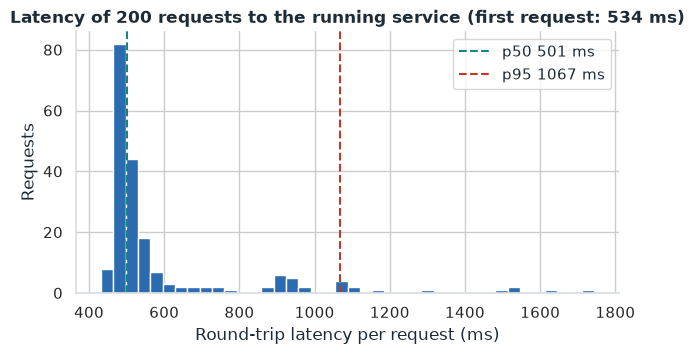

**200 requests to the deployed service at https://hotel-cancellation-risk.vercel.app:** first request **534 ms**, then median **501 ms**, 95th percentile 1067 ms, 99th 1528 ms, measured from the client; error rate 0.0%. The server itself spends a median of 1.7 ms per request; the rest is network and platform overhead. Largest difference between the service's prediction and the offline model: **6.8e-07** (the service rounds to six decimals), so the served model is the model evaluated in this notebook.

In [64]:
latency = None
if LIVE:
    replay_rows = frames["raw_validation"].head(40 if FAST else 200)
    offline = service_style_proba(replay_rows, metadata, onnx_path)
    latency = replay_requests(SERVICE_URL, replay_rows, offline)
    finish_figure(plot_latency(latency), "monitor_latency", ctx)
    say(f"**{latency['requests']} requests to {WHERE}:** first request **{latency['first_request_ms']:.0f} ms**, "
        f"then median **{latency['warm_p50_ms']:.0f} ms**, 95th percentile {latency['warm_p95_ms']:.0f} ms, 99th "
        f"{latency['warm_p99_ms']:.0f} ms, measured from the client; error rate {latency['error_rate']:.1%}. "
        + ("These are local figures, without the network and the cold start that a cloud deployment adds. "
           if LOCAL else "")
        + (f"The server itself spends a median of {latency['server_p50_ms']:.1f} ms per request; the rest is "
           "network and platform overhead. " if latency["server_p50_ms"] is not None else "")
        + f"Largest difference between the service's prediction and the offline model: "
          f"**{latency['max_abs_diff_vs_offline']:.1e}**"
        + (" (the service rounds to six decimals), so the served model is the model evaluated in this notebook."
           if latency["max_abs_diff_vs_offline"] <= 1e-4 else
           ". A difference above 0.0001 means this run's model is not the served one (different environment "
           "or fast mode)."))
else:
    print("Skipped: the API is not reachable from here.")

### 10.2 Data drift

In production the model is trained on the past and used on the future, so the question is how much the
inputs change from one year to the next. For every deployed feature, bookings arriving up to 2016 are
compared with bookings arriving in 2017 (drift needs no labels, so all cleaned bookings are used).

- **Population stability index (PSI):** below 0.1 stable, 0.1 to 0.25 a moderate shift, above 0.25 a large shift.
- **Kolmogorov-Smirnov statistic** for numeric features: the largest gap between the two distributions.

,feature,type,psi,level,ks_statistic,ks_pvalue
0,month_sin,numeric,5.1948,large,0.4261,0.0
1,arrival_week,numeric,4.2945,large,0.4301,0.0
2,month_cos,numeric,1.5770,large,0.1299,0.0
3,agent_id,categorical,0.5790,large,NaN,NaN
4,adr,numeric,0.1403,moderate,0.1676,0.0
5,adr_per_person,numeric,0.1135,moderate,0.1476,0.0
6,log_lead_time,numeric,0.0664,stable,0.1124,0.0
7,market_segment,categorical,0.0529,stable,NaN,NaN
8,customer_type,categorical,0.0509,stable,NaN,NaN
9,meal,categorical,0.0363,stable,NaN,NaN


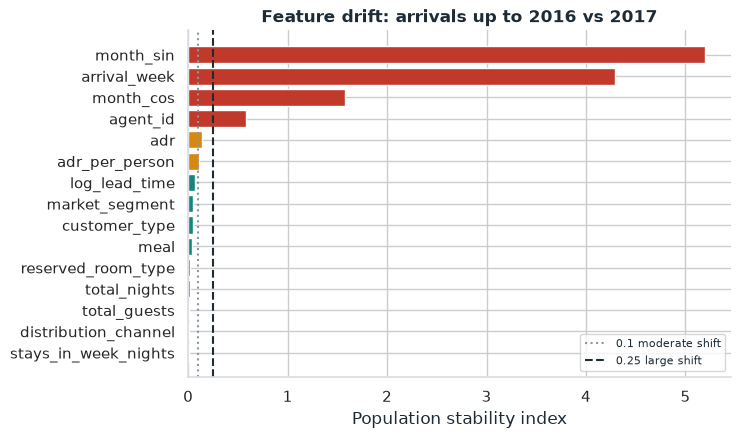

Of 30 features, **4** show a large shift, 2 a moderate one and 24 are stable. The largest is `month_sin` (PSI 5.19). Large shifts: `month_sin`, `arrival_week`, `month_cos`, `agent_id`. 3 of them are calendar features, which shift by construction: the data covers July 2015 to August 2017, so the two periods contain different months. Shifts in how bookings are sold (segment, agent, price) are the ones a revenue manager would watch.

In [65]:
drift_features = build_feature_frame(clean, deployed_sources(cfg))
arrival_year = clean["arrival_date_year"].to_numpy()
cut = cfg.split.temporal_train_until_year
drift = drift_report(drift_features[arrival_year <= cut], drift_features[arrival_year == cut + 1], frames["cats"])
display(drift.round(4).head(10))
finish_figure(plot_drift(drift, f"Feature drift: arrivals up to {cut} vs {cut + 1}"), "monitor_drift", ctx)
levels = drift["level"].value_counts()
calendar = {"month_sin", "month_cos", "arrival_week", "arrival_weekday"}
large = [f for f in drift.loc[drift["level"] == "large", "feature"]]
say(f"Of {len(drift)} features, **{levels.get('large', 0)}** show a large shift, {levels.get('moderate', 0)} a "
    f"moderate one and {levels.get('stable', 0)} are stable. The largest is `{drift.iloc[0]['feature']}` "
    f"(PSI {drift.iloc[0]['psi']:.2f}). Large shifts: {', '.join(f'`{f}`' for f in large) or 'none'}. "
    f"{sum(f in calendar for f in large)} of them are calendar features, which shift by construction: the data "
    "covers July 2015 to August 2017, so the two periods contain different months. Shifts in how bookings "
    "are sold (segment, agent, price) are the ones a revenue manager would watch.")

### 10.3 Performance over time

Section 6.6 already refitted the champion's settings on arrivals up to 2016 and scored 2017. Month by month:

In [66]:
by_month = pd.DataFrame(temporal["by_month"])
display(by_month.round(3))
worst = by_month.loc[by_month["roc_auc"].idxmin()]
say(f"Over {temporal['eval_year']} the ROC-AUC is {temporal['eval_roc_auc']:.3f}, ranging from "
    f"{worst['roc_auc']:.3f} ({worst['month']}) to {by_month['roc_auc'].max():.3f} "
    f"({by_month.loc[by_month['roc_auc'].idxmax(), 'month']}).")

,month,rows,cancel_rate,roc_auc
0,January,2414,0.261,0.821
1,February,2774,0.267,0.787
2,March,3135,0.254,0.771
3,April,3526,0.337,0.768
4,May,3879,0.325,0.766
5,June,3575,0.344,0.726
6,July,3858,0.361,0.723
7,August,3706,0.366,0.758


Over 2017 the ROC-AUC is 0.764, ranging from 0.723 (July) to 0.821 (January).

### 10.4 Collecting feedback

In production the true outcome of a booking is known only after its arrival date. The API therefore
returns a `prediction_id` with every prediction, and the hotel's system reports the outcome later to
`POST /api/v1/feedback`. The cell below plays that loop with a random sample of validation bookings,
whose outcomes are known: predict, then report what really happened, then read the service's running
summary. The service stores only the ID, the outcome and the prediction, never the booking.

In [67]:
if LIVE:
    feedback_rows = frames["raw_validation"].sample(n=20 if FAST else 60, random_state=cfg.seed)
    for row, outcome in zip(feedback_rows.to_dict("records"), frames["y_validation"].loc[feedback_rows.index]):
        prediction = call_api("/api/v1/predict", to_api_payload(row))
        call_api("/api/v1/feedback", {"prediction_id": prediction["prediction_id"], "was_cancelled": bool(outcome),
                                      "cancellation_probability": prediction["cancellation_probability"],
                                      "will_cancel": prediction["will_cancel"],
                                      "model_version": prediction["model_version"]})
    feedback_summary = call_api("/api/v1/feedback/summary")
    shown = {k: feedback_summary[k] for k in ("storage", "records", "outcomes", "calibration", "decisions")}
    print(f"Reported the real outcome of {len(feedback_rows)} predictions. The service's running summary "
          "(it also counts any feedback sent to this instance before):")
    print(json.dumps(shown, indent=2))
else:
    print("Skipped: the API is not reachable from here.")

Reported the real outcome of 60 predictions. The service's running summary (it also counts any feedback sent to this instance before):
{
  "storage": "this instance only",
  "records": 60,
  "outcomes": {
    "cancelled": 16,
    "arrived": 44
  },
  "calibration": {
    "records": 60,
    "observed_cancellation_rate": 0.2667,
    "mean_predicted_probability": 0.2828
  },
  "decisions": {
    "records": 60,
    "confusion": {
      "true_positive": 2,
      "false_positive": 1,
      "true_negative": 43,
      "false_negative": 14
    },
    "accuracy": 0.75,
    "precision": 0.6667,
    "recall": 0.125
  }
}


### 10.5 Retraining policy

Monitoring is only useful if it triggers action. The policy below turns the measurements into rules.

In [68]:
line = diag["val_metrics"]["roc_auc"] - 0.03
below = (by_month["roc_auc"] < line).to_numpy()
two_in_a_row = bool((below[1:] & below[:-1]).any())
say(f"""
| Signal | How it is measured | Action |
|---|---|---|
| **Performance drop** | Monthly ROC-AUC on bookings whose outcome is now known, from the feedback endpoint | Retrain if it falls more than 0.03 below the validation ROC-AUC ({diag['val_metrics']['roc_auc']:.3f}) for two months in a row |
| **Input drift** | Monthly PSI of every feature against the training data | Investigate any PSI above 0.25; retrain if three or more booking-channel or price features exceed it |
| **Calibration** | Average predicted probability against the actual cancellation rate each month | Re-fit the calibration (cheap, no retraining) if they differ by more than 5 percentage points |
| **Scheduled** | Calendar | Retrain at least every six months with the latest 24 months of bookings, so every season is represented |
| **Service health** | 95th-percentile latency and error rate from the logs | Alert if the 95th percentile exceeds 1 s or errors exceed 1% |

Applied to the check in 10.3 (a model trained on arrivals up to {temporal['eval_year'] - 1}, scored on
{temporal['eval_year']}), {int(below.sum())} of the {len(by_month)} months fall below that line ({line:.3f}),
{'including two in a row, so the performance rule would have called for retraining' if two_in_a_row else 'never two in a row, so the performance rule would not have fired'}.
The line comes from a random split, which is an optimistic reference for a model used on a later year;
that is exactly the situation the rule is there to catch.
Retraining means re-running this notebook (or the pipeline) on the newer data: the champion, calibration
and threshold are re-chosen, the parity check must pass, and the new model replaces the old one only if it
is at least as good on the newest validation period.
""")


| Signal | How it is measured | Action |
|---|---|---|
| **Performance drop** | Monthly ROC-AUC on bookings whose outcome is now known, from the feedback endpoint | Retrain if it falls more than 0.03 below the validation ROC-AUC (0.810) for two months in a row |
| **Input drift** | Monthly PSI of every feature against the training data | Investigate any PSI above 0.25; retrain if three or more booking-channel or price features exceed it |
| **Calibration** | Average predicted probability against the actual cancellation rate each month | Re-fit the calibration (cheap, no retraining) if they differ by more than 5 percentage points |
| **Scheduled** | Calendar | Retrain at least every six months with the latest 24 months of bookings, so every season is represented |
| **Service health** | 95th-percentile latency and error rate from the logs | Alert if the 95th percentile exceeds 1 s or errors exceed 1% |

Applied to the check in 10.3 (a model trained on arrivals up to 2016, scored on
2017), 6 of the 8 months fall below that line (0.780),
including two in a row, so the performance rule would have called for retraining.
The line comes from a random split, which is an optimistic reference for a model used on a later year;
that is exactly the situation the rule is there to catch.
Retraining means re-running this notebook (or the pipeline) on the newer data: the champion, calibration
and threshold are re-chosen, the parity check must pass, and the new model replaces the old one only if it
is at least as good on the newest validation period.


## 11. Documentation and reporting

All results are written to one file, `metrics.json`; the README, the process document, the model card
and the slides read their numbers from it, so they cannot disagree with this notebook.

In [69]:
parts = {
    "audit": audit, "cleaning_log": cleaning_log, "rows_after_cleaning": rows_after_cleaning,
    "duplicate_rows_cancel_rate": duplicate_rows_cancel_rate, "split_summary": split_info, "frames": frames,
    "leakage": ablation, "dedup": dedup, "duplicates": duplicates, "quality_audit": quality,
    "candidates": candidates.to_dict("records"),
    "experiments": {"encodings": encodings.to_dict("records"), "imbalance": imbalance.to_dict("records"),
                    "feature_additions": feature_additions.to_dict("records")},
    "tuning": tuning, "champion": champion, "diagnostics": diag, "temporal": temporal,
    "permutation": perm, "shap_importance": shap_imp, "test": test, "deployment": deployment,
}
report = build_metrics_report(parts, cfg)
report["monitoring"] = {"service_url": SERVICE_URL if LIVE else None, "local": LOCAL,
                        "latency": ({k: v for k, v in latency.items() if k != "client_latencies_ms"} if latency else None),
                        "drift_large": large}
save_json(report, ctx.metrics_dir / "metrics.json")
print(f"Saved metrics.json in the '{ctx.root.name}' folder.")

Saved metrics.json in the 'outputs' folder.


In [70]:
say(f"""
### Summary

| | |
|---|---|
| Bookings after cleaning | {rows_after_cleaning:,} |
| Train / validation / test | {split_info['train']['rows']:,} / {split_info['validation']['rows']:,} / {split_info['test']['rows']:,} |
| Champion | {champion['name']} (search: {champion['strategy']}) |
| Test ROC-AUC (95% CI) | {c['metrics']['roc_auc']:.3f} ({ci['low']:.3f} to {ci['high']:.3f}) |
| Test PR-AUC | {c['metrics']['pr_auc']:.3f} |
| Baselines, test ROC-AUC | logistic regression {test['models']['logreg']['metrics']['roc_auc']:.3f}, majority class {test['models']['dummy']['metrics']['roc_auc']:.3f} |
| Cost-based threshold: precision / recall / F1 | {t_ops.loc['cost-based (deployed)', 'threshold']:.2f}: {t_ops.loc['cost-based (deployed)', 'precision']:.3f} / {t_ops.loc['cost-based (deployed)', 'recall']:.3f} / {t_ops.loc['cost-based (deployed)', 'f1']:.3f} |
| Best-F1 threshold: precision / recall / F1 | {t_ops.loc['best F1', 'threshold']:.2f}: {t_ops.loc['best F1', 'precision']:.3f} / {t_ops.loc['best F1', 'recall']:.3f} / {t_ops.loc['best F1', 'f1']:.3f} |
| Weekly cancellations per hotel, forecast error | {t_cap['wape_model']:.0%} with the model, {t_cap['wape_base_rate']:.0%} without |
| What was avoided: ROC-AUC with post-booking columns / with duplicates and a random split | {ladder['+ Tier 2 (known after booking)']:.3f} / {dedup['val_roc_auc_duplicates_kept']:.3f} |
| Success criterion (test ROC-AUC of at least {cfg.success.roc_auc}) | {'met' if s['roc_auc_target_met'] else 'not met (see 8.1)'} |
| API | {('measured against a local copy; not yet deployed to the cloud' if LOCAL else SERVICE_URL) if LIVE else 'see the README'} |

**Limitations.**
- Two hotels in one country, 2015 to 2017: patterns may not transfer to other hotels or to later years
  without retraining, and the temporal check shows the score drops on a year the model has not seen.
- The target ROC-AUC was not met. The model ranks bookings usefully and forecasts weekly cancellation
  counts well, but at the stated costs its single-booking flags save little.
- Several useful columns were excluded because their timing could not be established, which costs
  accuracy but makes the score honest. If a hotel can confirm that special requests are recorded at
  booking, that column should be added back.
- Duplicates were removed although many are probably genuine block bookings; Section 3.7 shows what
  that choice does.
- The cost figures are assumptions; a hotel would replace them with its own, and the threshold follows.
- The test set was scored twice (Section 8.1).
- The "Non Refund" label behaves like a recording practice rather than guest behaviour; the model
  learns it as recorded.

**What I would do next.** Obtain a guest identifier and booking timestamps so that history features and a
truly time-ordered evaluation become possible; treat block bookings as one decision with a room count;
confirm with the hotels when each excluded column is recorded; store feedback durably and automate the
monthly monitoring report; and evaluate overbooking policies by simulation on held-out weeks instead of
through a single cost ratio.

**References.** Antonio, N., de Almeida, A. and Nunes, L. (2019). Hotel booking demand datasets. *Data in
Brief*, 22, 41-49. https://doi.org/10.1016/j.dib.2018.11.126 (CC BY 4.0). Software: scikit-learn, LightGBM,
Optuna, SHAP, imbalanced-learn, ONNX Runtime, FastAPI.
""")


### Summary

| | |
|---|---|
| Bookings after cleaning | 87,228 |
| Train / validation / test | 61,058 / 13,085 / 13,085 |
| Champion | lgbm (search: bayesian, all training rows) |
| Test ROC-AUC (95% CI) | 0.807 (0.799 to 0.814) |
| Test PR-AUC | 0.636 |
| Baselines, test ROC-AUC | logistic regression 0.774, majority class 0.500 |
| Cost-based threshold: precision / recall / F1 | 0.63: 0.812 / 0.193 / 0.311 |
| Best-F1 threshold: precision / recall / F1 | 0.29: 0.507 / 0.746 / 0.604 |
| Weekly cancellations per hotel, forecast error | 15% with the model, 25% without |
| What was avoided: ROC-AUC with post-booking columns / with duplicates and a random split | 0.920 / 0.889 |
| Success criterion (test ROC-AUC of at least 0.85) | not met (see 8.1) |
| API | https://hotel-cancellation-risk.vercel.app |

**Limitations.**
- Two hotels in one country, 2015 to 2017: patterns may not transfer to other hotels or to later years
  without retraining, and the temporal check shows the score drops on a year the model has not seen.
- The target ROC-AUC was not met. The model ranks bookings usefully and forecasts weekly cancellation
  counts well, but at the stated costs its single-booking flags save little.
- Several useful columns were excluded because their timing could not be established, which costs
  accuracy but makes the score honest. If a hotel can confirm that special requests are recorded at
  booking, that column should be added back.
- Duplicates were removed although many are probably genuine block bookings; Section 3.7 shows what
  that choice does.
- The cost figures are assumptions; a hotel would replace them with its own, and the threshold follows.
- The test set was scored twice (Section 8.1).
- The "Non Refund" label behaves like a recording practice rather than guest behaviour; the model
  learns it as recorded.

**What I would do next.** Obtain a guest identifier and booking timestamps so that history features and a
truly time-ordered evaluation become possible; treat block bookings as one decision with a room count;
confirm with the hotels when each excluded column is recorded; store feedback durably and automate the
monthly monitoring report; and evaluate overbooking policies by simulation on held-out weeks instead of
through a single cost ratio.

**References.** Antonio, N., de Almeida, A. and Nunes, L. (2019). Hotel booking demand datasets. *Data in
Brief*, 22, 41-49. https://doi.org/10.1016/j.dib.2018.11.126 (CC BY 4.0). Software: scikit-learn, LightGBM,
Optuna, SHAP, imbalanced-learn, ONNX Runtime, FastAPI.
